In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import os
# Importing the numpy and pandas package
import numpy as np # linear algebra
import pandas as pd # data processing, file I/O
# Data Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV

from skopt import BayesSearchCV

from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score, classification_report,f1_score, average_precision_score,  auc,# This is PR-AUC
    roc_curve,roc_auc_score,ConfusionMatrixDisplay,make_scorer,precision_recall_curve
)

from sklearn.feature_extraction.text import CountVectorizer
import pickle
# Import all models
from lazypredict.Supervised import LazyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier, 
    ExtraTreesClassifier,
    AdaBoostClassifier
)
from catboost import CatBoostClassifier

from sklearn.preprocessing import TargetEncoder
from xgboost import XGBClassifier
import xgboost as xgb
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression, Ridge, Lasso
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from tensorflow import keras

from imblearn.over_sampling import SMOTE

In [3]:
os.chdir(r"C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects")
os.getcwd()

'C:\\Users\\Owner\\Downloads\\Data Science Metro\\DSPP\\Projects'

In [4]:
outputfolder=r"C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects\Output"

In [5]:
df = pd.read_excel(r"C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects\Telco_customer_churn.xlsx")
df.shape

(7043, 33)

In [6]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [7]:
df['Churn Value'].value_counts()

Churn Value
0    5174
1    1869
Name: count, dtype: int64

In [8]:
df['Churn Value'].isna().sum()

np.int64(0)

In [9]:
print(df.shape)
df=df.dropna(subset=['Churn Value'])
print(df.shape)

(7043, 33)
(7043, 33)


## Import DataPipeline

In [10]:
#a .py file(datapipeline.py) must be in the current working directory or in Python’s module search path to be imported.
from Pipeline_TelcoChurn_Sobia_Pervaiz import *

In [11]:
df['Churn Value'].value_counts()

Churn Value
0    5174
1    1869
Name: count, dtype: int64

In [12]:
target = 'Churn Value'
#Split data
train_df, test_df = train_test_split(
    df,
    test_size=0.20,                 # 20%
    stratify=df[target],#if in y_train data, 77% are the values ,in y_test, 77%of 0 will be included to preserve imbalance
    random_state=42
)

#Sanity Check
print("Train distribution:\n", train_df[target].value_counts(normalize=True))
print("="*100)
print("\nTest distribution:\n", test_df[target].value_counts(normalize=True))

Train distribution:
 Churn Value
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Test distribution:
 Churn Value
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [13]:
X_train = train_df.drop(columns=['Churn Value'])
y_train = train_df['Churn Value']

X_test = test_df.drop(columns=['Churn Value'])
y_test = test_df['Churn Value']

In [14]:
"""
MODEL COMPARISON USING OPTIMAL F1-SCORE THRESHOLD
==================================================
For each model, displays:
- Optimal Threshold (θ)
- F1-Score at Optimal Threshold
- F1-Score at Default (0.5) Threshold
- ROC-AUC
- PR-AUC
"""


print("Dataset Information:")
print("=" * 70)
print(f"Training set size: {len(train_df)}")
print(f"Test set size: {len(test_df)}")
print(f"\nClass distribution in training set:")
print(train_df[target].value_counts(normalize=True))
print()


# ══════════════════════════════════════════════════════════════════════
# HELPER FUNCTION: Find optimal threshold and calculate all metrics
# ══════════════════════════════════════════════════════════════════════
def find_optimal_threshold_and_evaluate(y_true, y_pred_proba, model_name="Model"):
    """
    Find the threshold that maximizes F1-Score and calculate all metrics.
    
    Args:
        y_true: True labels
        y_pred_proba: Predicted probabilities (0-1)
        model_name: Name of the model
    
    Returns:
        Dictionary with all metrics
    """
    # Try different thresholds from 0.01 to 0.99
    thresholds = np.arange(0.01, 1.0, 0.01)
    f1_scores = []
    
    # Calculate F1-Score for each threshold
    for threshold in thresholds:
        y_pred_at_threshold = (y_pred_proba >= threshold).astype(int)
        f1 = f1_score(y_true, y_pred_at_threshold, average='binary')
        f1_scores.append(f1)
    
    # Find the threshold that gives the best F1-Score
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    optimal_f1 = f1_scores[optimal_idx]
    
    # Calculate F1 at default 0.5 threshold for comparison
    y_pred_default = (y_pred_proba >= 0.5).astype(int)
    f1_default = f1_score(y_true, y_pred_default, average='binary')
    
    # Calculate ROC-AUC and PR-AUC (threshold-independent)
    roc_auc = roc_auc_score(y_true, y_pred_proba)
    pr_auc = average_precision_score(y_true, y_pred_proba) # For PR-AUC 
    
    return {
        'Model': model_name,
        'Optimal_Threshold': optimal_threshold,
        'F1_Optimal': optimal_f1,
        'F1_Default': f1_default,
        'ROC_AUC': roc_auc,
        'PR_AUC': pr_auc
    }


# ══════════════════════════════════════════════════════════════════════
# Helper function to print results table
# ══════════════════════════════════════════════════════════════════════
def print_results_table(results_list, title):
    """Print a formatted table of results"""
    print(f"\n{title}")
    print("=" * 115)
    print(f"{'Model':<25} {'Optimal θ':<12} {'F1 (Optimal)':<15} {'F1 (Default)':<15} {'ROC-AUC':<12} {'PR-AUC':<12}")
    print("-" * 115)
    
    for result in results_list:
        print(f"{result['Model']:<25} "
              f"{result['Optimal_Threshold']:<12.3f} "
              f"{result['F1_Optimal']:<15.4f} "
              f"{result['F1_Default']:<15.4f} "
              f"{result['ROC_AUC']:<12.4f} "
              f"{result['PR_AUC']:<12.4f}")
    print()


# ══════════════════════════════════════════════════════════════════════
# GROUP 1: ROBUST TREE MODELS(Decision Trees / Random Forest / Extra Trees)
# ══════════════════════════════════════════════════════════════════════
# Preprocess ONCE for all these models
X_train_tree=pipline_Churn(X_train, X_train,
                        scaling_data=False, Handling_Outliers=False,
                        Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=True,
                        encoding=True, is_training_data=True)

y_train_tree  = y_train.loc[X_train_tree.index]
y_train_tree =y_train.loc[X_train_tree.index]
X_test_tree=pipline_Churn(X_test, X_train,
                    scaling_data=False, Handling_Outliers=False,
                    Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=True,
                    encoding=True, is_training_data=False)

X_test_tree = X_test_tree.reindex(columns=X_train_tree.columns, fill_value=0)

y_test_tree = y_test.loc[X_test_tree.index]


tree_robust_models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Extra Trees": ExtraTreesClassifier(random_state=42)
}

tree_results = []
for name, model in tree_robust_models.items():
    # Train
    model.fit(X_train_tree, y_train_tree)
    
    # Get probability predictions
    y_pred_proba = model.predict_proba(X_test_tree)[:, 1]
    
    # Find optimal threshold and evaluate
    metrics = find_optimal_threshold_and_evaluate(y_test_tree, y_pred_proba, name)
    tree_results.append(metrics)

print_results_table(tree_results, "GROUP 1: ROBUST TREE MODELS")
print("="*100)

# ══════════════════════════════════════════════════════════════════════
# GROUP 2: ADABOOST (OUTLIER-SENSITIVE)
# ══════════════════════════════════════════════════════════════════════
X_train_ada=pipline_Churn(X_train, X_train,
                        scaling_data=False, Handling_Outliers=True,
                        Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=True,
                        encoding=True, is_training_data=True)

y_train_ada =y_train.loc[X_train_ada.index]
X_test_ada=pipline_Churn(X_test, X_train,
                    scaling_data=False, Handling_Outliers=True,
                    Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=True,
                    encoding=True, is_training_data=False)
X_test_ada= X_test_ada.reindex(columns=X_train_ada.columns, fill_value=0)

y_test_ada = y_test.loc[X_test_ada.index]


model_ada = AdaBoostClassifier(random_state=42)
model_ada.fit(X_train_ada, y_train_ada)

y_pred_proba_ada = model_ada.predict_proba(X_test_ada)[:, 1]
metrics_ada = find_optimal_threshold_and_evaluate(y_test_ada, y_pred_proba_ada, "AdaBoost")

print_results_table([metrics_ada], "GROUP 2: ADABOOST")
print("="*100)

# ══════════════════════════════════════════════════════════════════════
# GROUP 3: GRADIENT BOOSTING MODELS (WITH ENCODING)
# ══════════════════════════════════════════════════════════════════════
# Preprocess ONCE for all gradient boosting models
X_train_gb=pipline_Churn(X_train, X_train,
                        scaling_data=False, Handling_Outliers=False,
                        Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=False,
                        encoding=True, is_training_data=True)

y_train_gb =y_train.loc[X_train_gb.index]
X_test_gb=pipline_Churn(X_test, X_train,
                    scaling_data=False, Handling_Outliers=False,
                    Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=False,
                    encoding=True, is_training_data=False)

X_test_gb = X_test_gb.reindex(columns=X_train_gb.columns, fill_value=0)

y_test_gb = y_test.loc[X_test_gb.index]


gradient_boosting_models = {
    "XGBoost": xgb.XGBClassifier(random_state=42, eval_metric='logloss'),
    "LightGBM": LGBMClassifier( random_state=42, verbose=-1),

}

gb_results = []
for name, model in gradient_boosting_models.items():
    # Train
    model.fit(X_train_gb, y_train_gb)
    
    # Get probability predictions
    y_pred_proba = model.predict_proba(X_test_gb)[:, 1]
    
    # Find optimal threshold and evaluate
    metrics = find_optimal_threshold_and_evaluate(y_test_gb, y_pred_proba, name)
    gb_results.append(metrics)

print_results_table(gb_results, "GROUP 3.a: GRADIENT BOOSTING MODELS (WITH ENCODING)")
print("="*100)
    
# ══════════════════════════════════════════════════════════════════════
# GROUP 3: GRADIENT BOOSTING MODELS WITHOUT ENCODING
# ══════════════════════════════════════════════════════════════════════
# Preprocess ONCE for all gradient boosting models
X_train_gb2=pipline_Churn(X_train, X_train,
                        scaling_data=False, Handling_Outliers=False,
                        Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=False,
                        encoding=False, is_training_data=True)

y_train_gb2 =y_train.loc[X_train_gb2.index]
X_test_gb2=pipline_Churn(X_test, X_train,
                    scaling_data=False, Handling_Outliers=False,
                    Handling_Missing_Values_Not_DT=False, Handling_Missing_Values_DT=False,
                    encoding=False, is_training_data=False)

X_test_gb2 = X_test_gb2.reindex(columns=X_train_gb2.columns, fill_value=0)

y_test_gb2 = y_test.loc[X_test_gb2.index]

cat_features = ['City']

#CatBoost does NOT allow raw NaN inside categorical columns.

for col in cat_features:
    X_train_gb2[col] = X_train_gb2[col].fillna("Missing").astype(str)
    X_test_gb2[col] = X_test_gb2[col].fillna("Missing").astype(str)
    
gradient_boosting_models = {


    "CatBoost": CatBoostClassifier(cat_features=cat_features, random_state=42, verbose=0)

    }


gb_results = []

for name, model in gradient_boosting_models.items():

    # Train
     model.fit(X_train_gb2, y_train_gb2)
    
     # Get probability predictions
     y_pred_proba = model.predict_proba(X_test_gb2)[:, 1]
    
     # Find optimal threshold and evaluate
     metrics = find_optimal_threshold_and_evaluate(y_test_gb2, y_pred_proba, name)
     gb_results.append(metrics)

print_results_table(gb_results, "GROUP 3.b: GRADIENT BOOSTING MODELS((NO ENCODING!)")
print("="*100)

# ══════════════════════════════════════════════════════════════════════
# GROUP 4: SCALE-SENSITIVE MODELS
# ══════════════════════════════════════════════════════════════════════
# Preprocess ONCE for all scale-sensitive models
X_train_scaled = pipline_Churn(
    df2=X_train,
    Train=X_train,         # Train = itself during training
    scaling_data=True,
    Handling_Outliers=True,
    Handling_Missing_Values_Not_DT=True,
    Handling_Missing_Values_DT=False,
    encoding=True,
    is_training_data=True
)
y_train_scaled = y_train.loc[X_train_scaled.index] 
X_test_scaled= pipline_Churn(
    df2=X_test,
    Train=X_train,         # always pass the original training data — never refit on test
    scaling_data=True,
    Handling_Outliers=True,
    Handling_Missing_Values_Not_DT=True,
    Handling_Missing_Values_DT=False,
    encoding=True,
    is_training_data=False
)
X_test_scaled= X_test_scaled.reindex(columns=X_train_scaled.columns, fill_value=0)
y_test_scaled = y_test.loc[X_test_scaled.index] 

scale_sensitive_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    #"SVM": SVC(kernel='rbf', probability=True, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "LDA": LinearDiscriminantAnalysis()
}

scale_results = []
for name, model in scale_sensitive_models.items():
    # Train
    model.fit(X_train_scaled, y_train_scaled)
    
    # Get probability predictions
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    # Find optimal threshold and evaluate
    metrics = find_optimal_threshold_and_evaluate(y_test_scaled, y_pred_proba, name)
    scale_results.append(metrics)

print_results_table(scale_results, "GROUP 4: SCALE-SENSITIVE MODELS")


# ══════════════════════════════════════════════════════════════════════
# Neural Network (also uses scaled data)
# ══════════════════════════════════════════════════════════════════════
model_nn = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation='sigmoid')
])

model_nn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_nn.fit(
    X_train_scaled, y_train_scaled,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# Get probability predictions
y_pred_proba_nn = model_nn.predict(X_test_scaled, verbose=0).flatten()

# Find optimal threshold and evaluate
metrics_nn = find_optimal_threshold_and_evaluate(y_test_scaled, y_pred_proba_nn, "Neural Network")

print_results_table([metrics_nn], "NEURAL NETWORK")


# ══════════════════════════════════════════════════════════════════════
# COMPREHENSIVE COMPARISON - ALL MODELS
# ══════════════════════════════════════════════════════════════════════
print("\n" + "=" * 115)
print("COMPLETE MODEL COMPARISON - ALL MODELS")
print("=" * 115)

# Combine all results
all_results = tree_results + [metrics_ada] + gb_results + scale_results + [metrics_nn]

# Convert to DataFrame for easier sorting
results_df = pd.DataFrame(all_results)

# Print complete table sorted by F1 (Optimal)
print(f"\n{'Rank':<6} {'Model':<25} {'Optimal θ':<12} {'F1 (Optimal)':<15} {'F1 (Default)':<15} {'ROC-AUC':<12} {'PR-AUC':<12}")
print("-" * 115)

sorted_results = results_df.sort_values('F1_Optimal', ascending=False)
for rank, row in enumerate(sorted_results.itertuples(), 1):
    print(f"{rank:<6} {row.Model:<25} "
          f"{row.Optimal_Threshold:<12.3f} "
          f"{row.F1_Optimal:<15.4f} "
          f"{row.F1_Default:<15.4f} "
          f"{row.ROC_AUC:<12.4f} "
          f"{row.PR_AUC:<12.4f}")


# ══════════════════════════════════════════════════════════════════════
# DETAILED RANKINGS BY EACH METRIC
# ══════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 115)
print("DETAILED RANKINGS BY EACH METRIC")
print("=" * 115)

# Ranking by F1 (Optimal)
print("\n" + "-" * 115)
print("RANKED BY F1-SCORE (OPTIMAL THRESHOLD)")
print("-" * 115)
print(f"{'Rank':<6} {'Model':<25} {'Optimal θ':<12} {'F1 (Optimal)':<15} {'F1 (Default)':<15} {'ROC-AUC':<12} {'PR-AUC':<12}")
print("-" * 115)

sorted_by_f1 = results_df.sort_values('F1_Optimal', ascending=False)
for rank, row in enumerate(sorted_by_f1.itertuples(), 1):
    print(f"{rank:<6} {row.Model:<25} "
          f"{row.Optimal_Threshold:<12.3f} "
          f"{row.F1_Optimal:<15.4f} "
          f"{row.F1_Default:<15.4f} "
          f"{row.ROC_AUC:<12.4f} "
          f"{row.PR_AUC:<12.4f}")

# Ranking by ROC-AUC
print("\n" + "-" * 115)
print("RANKED BY ROC-AUC")
print("-" * 115)
print(f"{'Rank':<6} {'Model':<25} {'Optimal θ':<12} {'F1 (Optimal)':<15} {'F1 (Default)':<15} {'ROC-AUC':<12} {'PR-AUC':<12}")
print("-" * 115)

sorted_by_roc = results_df.sort_values('ROC_AUC', ascending=False)
for rank, row in enumerate(sorted_by_roc.itertuples(), 1):
    print(f"{rank:<6} {row.Model:<25} "
          f"{row.Optimal_Threshold:<12.3f} "
          f"{row.F1_Optimal:<15.4f} "
          f"{row.F1_Default:<15.4f} "
          f"{row.ROC_AUC:<12.4f} "
          f"{row.PR_AUC:<12.4f}")

# Ranking by PR-AUC
print("\n" + "-" * 115)
print("RANKED BY PR-AUC (MOST IMPORTANT FOR IMBALANCED DATA)")
print("-" * 115)
print(f"{'Rank':<6} {'Model':<25} {'Optimal θ':<12} {'F1 (Optimal)':<15} {'F1 (Default)':<15} {'ROC-AUC':<12} {'PR-AUC':<12}")
print("-" * 115)

sorted_by_pr = results_df.sort_values('PR_AUC', ascending=False)
for rank, row in enumerate(sorted_by_pr.itertuples(), 1):
    print(f"{rank:<6} {row.Model:<25} "
          f"{row.Optimal_Threshold:<12.3f} "
          f"{row.F1_Optimal:<15.4f} "
          f"{row.F1_Default:<15.4f} "
          f"{row.ROC_AUC:<12.4f} "
          f"{row.PR_AUC:<12.4f}")


# ══════════════════════════════════════════════════════════════════════
# BEST MODELS SUMMARY
# ══════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 115)
print("BEST MODELS BY EACH METRIC")
print("=" * 115)

best_f1_model = sorted_by_f1.iloc[0]
best_roc_model = sorted_by_roc.iloc[0]
best_pr_model = sorted_by_pr.iloc[0]

print(f"\nBEST F1-SCORE (OPTIMIZED):  {best_f1_model['Model']}")
print(f"   - Optimal Threshold:  {best_f1_model['Optimal_Threshold']:.3f}")
print(f"   - F1 (Optimal):       {best_f1_model['F1_Optimal']:.4f}")
print(f"   - F1 (Default):       {best_f1_model['F1_Default']:.4f}")
print(f"   - ROC-AUC:            {best_f1_model['ROC_AUC']:.4f}")
print(f"   - PR-AUC:             {best_f1_model['PR_AUC']:.4f}")

print(f"\nBEST ROC-AUC:               {best_roc_model['Model']}")
print(f"   - Optimal Threshold:  {best_roc_model['Optimal_Threshold']:.3f}")
print(f"   - F1 (Optimal):       {best_roc_model['F1_Optimal']:.4f}")
print(f"   - F1 (Default):       {best_roc_model['F1_Default']:.4f}")
print(f"   - ROC-AUC:            {best_roc_model['ROC_AUC']:.4f}")
print(f"   - PR-AUC:             {best_roc_model['PR_AUC']:.4f}")

print(f"\nBEST PR-AUC (RECOMMENDED):  {best_pr_model['Model']}")
print(f"   - Optimal Threshold:  {best_pr_model['Optimal_Threshold']:.3f}")
print(f"   - F1 (Optimal):       {best_pr_model['F1_Optimal']:.4f}")
print(f"   - F1 (Default):       {best_pr_model['F1_Default']:.4f}")
print(f"   - ROC-AUC:            {best_pr_model['ROC_AUC']:.4f}")
print(f"   - PR-AUC:             {best_pr_model['PR_AUC']:.4f}")


# ══════════════════════════════════════════════════════════════════════
# OVERALL WINNER (Balanced Performance Across All Metrics)
# ══════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 115)
print("OVERALL WINNER (Average Rank Across All Metrics)")
print("=" * 115)

# Calculate ranks for each metric
results_df['F1_Rank'] = results_df['F1_Optimal'].rank(ascending=False)
results_df['ROC_Rank'] = results_df['ROC_AUC'].rank(ascending=False)
results_df['PR_Rank'] = results_df['PR_AUC'].rank(ascending=False)

# Calculate average rank
results_df['Avg_Rank'] = (results_df['F1_Rank'] + results_df['ROC_Rank'] + results_df['PR_Rank']) / 3

# Sort by average rank
sorted_by_avg = results_df.sort_values('Avg_Rank')

print(f"\n{'Rank':<6} {'Model':<25} {'Avg Rank':<12} {'F1 (Optimal)':<15} {'ROC-AUC':<12} {'PR-AUC':<12}")
print("-" * 115)
for rank, row in enumerate(sorted_by_avg.itertuples(), 1):
    print(f"{rank:<6} {row.Model:<25} "
          f"{row.Avg_Rank:<12.2f} "
          f"{row.F1_Optimal:<15.4f} "
          f"{row.ROC_AUC:<12.4f} "
          f"{row.PR_AUC:<12.4f}")

overall_winner = sorted_by_avg.iloc[0]
print("\n" + "=" * 115)
print(f"OVERALL WINNER: {overall_winner['Model']}")
print(f"   - Average Rank:       {overall_winner['Avg_Rank']:.2f}")
print(f"   - Optimal Threshold:  {overall_winner['Optimal_Threshold']:.3f}")
print(f"   - F1 (Optimal):       {overall_winner['F1_Optimal']:.4f}")
print(f"   - F1 (Default):       {overall_winner['F1_Default']:.4f}")
print(f"   - ROC-AUC:            {overall_winner['ROC_AUC']:.4f}")
print(f"   - PR-AUC:             {overall_winner['PR_AUC']:.4f}")
print("=" * 115)


# ══════════════════════════════════════════════════════════════════════
# SAVE RESULTS TO CSV
# ══════════════════════════════════════════════════════════════════════
# Save complete results to CSV for further analysis
results_df_export = results_df[[
    'Model', 'Optimal_Threshold', 'F1_Optimal', 'F1_Default', 
    'ROC_AUC', 'PR_AUC', 'Avg_Rank'
]].copy()

results_df_export.to_csv('model_comparison_results.csv', index=False)
print("\nResults saved to 'model_comparison_results.csv'")


# ══════════════════════════════════════════════════════════════════════
# SUMMARY STATISTICS
# ══════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 115)
print("SUMMARY STATISTICS")
print("=" * 115)

print(f"\nOptimal Threshold Distribution:")
print(f"   - Mean:    {results_df['Optimal_Threshold'].mean():.3f}")
print(f"   - Median:  {results_df['Optimal_Threshold'].median():.3f}")
print(f"   - Min:     {results_df['Optimal_Threshold'].min():.3f}")
print(f"   - Max:     {results_df['Optimal_Threshold'].max():.3f}")

f1_improvement = results_df['F1_Optimal'] - results_df['F1_Default']
print(f"\nF1-Score Improvement (Optimal vs Default):")
print(f"   - Mean Improvement:    +{f1_improvement.mean():.4f}")
print(f"   - Median Improvement:  +{f1_improvement.median():.4f}")
print(f"   - Max Improvement:     +{f1_improvement.max():.4f}")
print(f"   - Min Improvement:     +{f1_improvement.min():.4f}")

relative_improvement = (f1_improvement / results_df['F1_Default']) * 100
print(f"\nRelative F1-Score Improvement:")
print(f"   - Average: {relative_improvement.mean():.1f}% improvement over default threshold")

print("\n" + "=" * 115)

Dataset Information:
Training set size: 5634
Test set size: 1409

Class distribution in training set:
Churn Value
0    0.734647
1    0.265353
Name: proportion, dtype: float64


GROUP 1: ROBUST TREE MODELS
Model                     Optimal θ    F1 (Optimal)    F1 (Default)    ROC-AUC      PR-AUC      
-------------------------------------------------------------------------------------------------------------------
Decision Tree             0.010        0.5243          0.5243          0.6763       0.4027      
Random Forest             0.290        0.6418          0.5667          0.8438       0.6482      
Extra Trees               0.380        0.6394          0.5848          0.8462       0.6670      


GROUP 2: ADABOOST
Model                     Optimal θ    F1 (Optimal)    F1 (Default)    ROC-AUC      PR-AUC      
-------------------------------------------------------------------------------------------------------------------
AdaBoost                  0.470        0.6284          0.5

In [15]:
X_train_gb2.select_dtypes(exclude='number').columns

Index(['City'], dtype='object')

### Compare untuned models to get an idea

In [16]:
X_train_s=X_train_scaled.copy()
y_train=y_train_scaled.copy()#y_train_scaled is actual y_train we are not scaling targetwe only removed those Ys that we removed their rows
X_test_s=X_test_scaled.copy()
y_test=y_test_scaled.copy()#y_test_scaled is actual y_tes we are not/ scaling target

In [17]:
def precision_recall_lift_at_k(y_true, y_prob, k_pct):
    """Precision, recall, and lift when flagging the top k% by predicted probability."""

    y_true = np.asarray(y_true).ravel()
    y_prob = np.asarray(y_prob).ravel()

    n = len(y_true)
    k = max(1, int(np.ceil(n * k_pct / 100)))

    order = np.argsort(y_prob)[::-1]
    top_idx = order[:k]

    tp = y_true[top_idx].sum()
    total_pos = y_true.sum()

    precision = tp / k
    recall = tp / total_pos if total_pos > 0 else 0.0

    baseline_positive_rate = total_pos / n
    lift = precision / baseline_positive_rate if baseline_positive_rate > 0 else 0.0

    return float(precision), float(recall), float(lift)


def store_results(name, X_train, y_train, X_test, y_test, model, folds,
                  norm="N/A", c="N/A", class_weight="N/A", fit=True):

    # ---- 1-D y
    y_train_1d = np.asarray(y_train).ravel()
    y_test_1d  = np.asarray(y_test).ravel()

    # ---- fit + persist
    if fit:
        model.fit(X_train, y_train_1d)

    with open(f"{name}.pkl", "wb") as f:
        pickle.dump(model, f)

    # ---- probabilities
    y_prob       = model.predict_proba(X_test)[:, 1]
    y_prob_train = model.predict_proba(X_train)[:, 1]

    # ---- threshold = 0.50 predictions
    y_pred_05       = (y_prob >= 0.50).astype(int)
    y_pred_train_05 = (y_prob_train >= 0.50).astype(int)

    # ---- confusion matrix
    print("Confusion matrix (prob threshold = 0.50):")
    cnf_matrix = confusion_matrix(y_test_1d, y_pred_05, labels=[0, 1])
    print(cnf_matrix)

    ConfusionMatrixDisplay(
        confusion_matrix=cnf_matrix,
        display_labels=[0, 1]
    ).plot(cmap=plt.cm.Blues)

    plt.title(f"{name} - Confusion Matrix (threshold=0.50)")
    plt.show()

    # ---- accuracy / F1 at 0.50
    train_accuracy_score = round(accuracy_score(y_train_1d, y_pred_train_05), 4)
    test_accuracy_score  = round(accuracy_score(y_test_1d, y_pred_05), 4)

    train_f1_score = round(f1_score(y_train_1d, y_pred_train_05), 4)
    test_f1_score  = round(f1_score(y_test_1d, y_pred_05), 4)

    print(f"Train F1 Score (0.50): {train_f1_score}")
    print(f"Test  F1 Score (0.50): {test_f1_score}")

    print("\nClassification Report (0.50):")
    print(classification_report(y_test_1d, y_pred_05))

    # ---- ROC + PR plots
    auc_pr_curve, auc_roc = plot_roc_and_pr(y_test_1d, y_prob, name=name)

    # ---- PR-AUC train + test
    train_pr_auc = average_precision_score(y_train_1d, y_prob_train)
    test_pr_auc  = average_precision_score(y_test_1d, y_prob)

    # ---- precision / recall / lift at top 1%, 5%, 10%
    topk_metrics = {}

    for k_pct in (1, 5, 10):
        p_te, r_te, l_te = precision_recall_lift_at_k(
            y_test_1d, y_prob, k_pct
        )

        p_tr, r_tr, l_tr = precision_recall_lift_at_k(
            y_train_1d, y_prob_train, k_pct
        )

        topk_metrics[f"Train_Precision@top{k_pct}%"] = round(p_tr, 4)
        topk_metrics[f"Train_Recall@top{k_pct}%"]    = round(r_tr, 4)
        topk_metrics[f"Train_Lift@top{k_pct}%"]      = round(l_tr, 4)

        topk_metrics[f"Test_Precision@top{k_pct}%"]  = round(p_te, 4)
        topk_metrics[f"Test_Recall@top{k_pct}%"]     = round(r_te, 4)
        topk_metrics[f"Test_Lift@top{k_pct}%"]       = round(l_te, 4)

    # ---- threshold sweep + rank-based evaluation
    eval_df, best_threshold, best_f1 = visualize_metrics_vs_threshold(
        model,
        name,
        X_test,
        y_test_1d,
        thresholds=np.arange(0.0, 1.05, 0.05)
    )

    rank_thre = evaluate_models(name, y_test_1d, y_prob)

    # ---- cross-validation
    cv_s = StratifiedKFold(
        n_splits=folds,
        shuffle=True,
        random_state=42
    )

    cv_res = cross_validate(
        model,
        X_train,
        y_train_1d,
        cv=cv_s,
        n_jobs=1,
        scoring=["roc_auc", "f1", "accuracy", "average_precision"],
        return_train_score=False
    )

    cv_auc = cv_res["test_roc_auc"].mean()
    cv_acc = cv_res["test_accuracy"].mean()

    cv_f1_scores = cv_res["test_f1"]
    cv_f1 = cv_f1_scores.mean()

    cv_pr_scores = cv_res["test_average_precision"]
    cv_pr_mean = cv_pr_scores.mean()
    cv_pr_std = cv_pr_scores.std()

    # ---- assemble row
    entry = {
        "Model": [name],
        "Class_weight": [class_weight],

        "Test_ROC_AUC": [round(auc_roc, 4)],
        "Train_PR_AUC": [round(train_pr_auc, 4)],
        "Test_PR_AUC": [round(test_pr_auc, 4)],

        "Train_Test_Gap(PR_AUC)": [round(train_pr_auc - test_pr_auc, 4)],
        "CrossVal_Std(PR_AUC)": [round(cv_pr_std, 4)],

        "CrossVal_Mean(ROC_AUC)": [round(cv_auc, 4)],
        "CrossVal_Mean_Accuracy": [round(cv_acc, 4)],
        "CrossVal_Mean(F1_score)": [round(cv_f1, 4)],
        "CrossVal_Mean(PR_AUC)": [round(cv_pr_mean, 4)],

        "train_accuracy_score@0.50": [train_accuracy_score],
        "test_accuracy_score@0.50": [test_accuracy_score],

        "train_f1_score@0.50": [train_f1_score],
        "test_f1_score@0.50": [test_f1_score],

        "max_f1score": [best_f1],
        "best_Prob_threshold": [best_threshold],
    }

    # ---- per-fold F1 and PR-AUC
    for i, s in enumerate(cv_f1_scores, start=1):
        entry[f"CrossVal{i}(f1)"] = [round(float(s), 4)]

    for i, s in enumerate(cv_pr_scores, start=1):
        entry[f"CrossVal{i}(PR_AUC)"] = [round(float(s), 4)]

    # ---- add top-k metrics
    for col, val in topk_metrics.items():
        entry[col] = [val]

    entry["Regularization"] = [norm]
    entry["C"] = [c]

    result = pd.DataFrame(entry)

    return result, eval_df, rank_thre

In [18]:
#step1. create an instanse
model1 = LogisticRegression(random_state=1234)

#step2. train (fit) model
model1.fit(X_train_s,y_train)

#step 3. predict on test set
y_pred = model1.predict(X_test_s)
y_pred_probs = model1.predict_proba(X_test_s)


In [19]:
df_test = X_test_s.copy() #original features
df_test['Actual class']=y_test.copy() # actual values
df_test['Prob'] = y_pred_probs[:, 1]  # probabilty of class 1(the 2nd one that has index 1 is probabilty of claas 1)
df_test['Prediction using thresold=0.5'] = y_pred.copy() #prediction ( class) using default threshold(=0.5)
df_test.head()

,Gender,Senior_Citizen,Partner,Dependents,Tenure_Months,Phone_Service,Multiple_Lines,Internet_Service,Online_Security,Online_Backup,...,City_Yosemite_National_Park,City_Yountville,City_Yreka,City_Yuba_City,City_Yucaipa,City_Yucca_Valley,City_Zenia,Actual class,Prob,Prediction using thresold=0.5
2196,0.0,0.0,1.0,0.0,0.934783,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.064118,0
3549,1.0,1.0,0.0,0.0,-0.456522,0.0,0.0,0.0,-1.0,-1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.754283,1
3515,1.0,0.0,1.0,0.0,0.260870,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.048346,0
5162,0.0,0.0,1.0,0.0,-0.239130,0.0,-1.0,0.0,-1.0,-1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.255805,0
4642,1.0,0.0,1.0,0.0,0.934783,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.024396,0


In [20]:
def visualize_metrics_vs_threshold(model, name, X_test, y_test,
                                   thresholds=np.arange(0.0, 1.01, 0.01)):
    """
    Visualize how FN, FP, Precision, Recall, and F1 vary across probability thresholds.

    Parameters
    ----------
    model : fitted sklearn-like classifier
        Trained model with predict_proba method.
    name : str
        Model name for plot titles.
    X_test : array-like
        Test features.
    y_test : array-like
        True labels (0/1).
    thresholds : array-like, optional
        Thresholds to evaluate (default: 0.00 to 1.00 step 0.01).

    Returns
    -------
    eval_df : pd.DataFrame
        Metrics per threshold (TN, FP, FN, TP, precision, recall, f1)
    best_threshold : float
        Threshold that gives maximum F1-score
    best_f1 : float
        Maximum F1-score value
    """

    # 1️. Predict probabilities
    y_prob = model.predict_proba(X_test)[:, 1]
    y_true = np.asarray(y_test)

    # 2.Compute metrics for each threshold
    rows, fn_list, fp_list, prec_list, rec_list, f1_list = [], [], [], [], [], []

    for thr in thresholds:
        y_pred = (y_prob >= thr).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

        prec = precision_score(y_true, y_pred, zero_division=0)
        rec = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)

        rows.append({
            "Model": name,
            "Threshold": thr,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Precision": prec,
            "Recall": rec,
            "F1": f1
        })

        fn_list.append(fn)
        fp_list.append(fp)
        prec_list.append(prec)
        rec_list.append(rec)
        f1_list.append(f1)

    eval_df = pd.DataFrame(rows)

    # 3. Find best threshold by F1
    best_idx = int(np.nanargmax(eval_df["F1"].values))
    best_threshold = eval_df.loc[best_idx, "Threshold"]
    best_f1 = eval_df.loc[best_idx, "F1"]

    print(f"[{name}] Best F1-score = {best_f1:.4f} at threshold = {best_threshold:.2f}")

    # 4.Plot FN & FP
    plt.figure(figsize=(6, 3))
    plt.plot(thresholds, fn_list, label="False Negatives", marker="o")
    plt.plot(thresholds, fp_list, label="False Positives", marker="o")
    plt.axvline(best_threshold, linestyle="--", color="gray",
                label=f"Best Threshold = {best_threshold:.2f}")
    plt.title(f"{name}: FN and FP vs Threshold")
    plt.xlabel("Threshold")
    plt.ylabel("Count")
    plt.legend()
    plt.grid(True)
    plt.show()

    # 5.Plot Precision, Recall, and F1
    plt.figure(figsize=(6, 3))
    plt.plot(thresholds, prec_list, label="Precision", marker="o")
    plt.plot(thresholds, rec_list, label="Recall", marker="o")
    plt.plot(thresholds, f1_list, label="F1-Score", marker="o")
    plt.axvline(best_threshold, linestyle="--", color="gray",
                label=f"Best Threshold = {best_threshold:.2f}")
    plt.title(f"{name}: Precision, Recall & F1 vs Threshold")
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.legend()
    plt.grid(True)
    plt.show()

    return eval_df, best_threshold, best_f1

In [21]:
def plot_roc_and_pr(y_test, y_proba, name="Model"):
    # --- Make y_test 1D
    y_test = np.asarray(y_test).ravel()

    # --- Handle y_proba 1D or 2D
    y_proba = np.asarray(y_proba)
    if y_proba.ndim == 2 and y_proba.shape[1] == 2:
        y_proba = y_proba[:, 1]
    else:
        y_proba = y_proba.ravel()

    # =========================
    # 1) ROC curve + ROC AUC
    # =========================
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_roc = roc_auc_score(y_test, y_proba)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f"{name} ROC (AUC={auc_roc:.3f})")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")
    plt.xlabel("False Positive Rate (FPR)")
    plt.ylabel("True Positive Rate (TPR)")
    plt.title("ROC Curve")
    plt.grid(True)
    plt.legend()
    plt.show()

    # =========================
    # 2) Precision-Recall curve + PR AUC
    # =========================
    precision, recall, _ = precision_recall_curve(y_test, y_proba)

    # recall often decreasing, so reverse before auc()
    auc_pr = auc(recall[::-1], precision[::-1])

    plt.figure(figsize=(8, 6))
    plt.plot(recall, precision, marker="o", label=f"{name} PR (AUC={auc_pr:.3f})")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curve")
    plt.grid(True)
    plt.legend()
    plt.show()

    return auc_pr, auc_roc

In [22]:
def evaluate_models(name, y_test, y_proba, thresholds=list(range(100, 0, -5))):
    """
    Rank-based thresholding.
    Evaluates TP, TN, FP, FN when predicting top N% as positive.
    Calculates precision, recall, F1, and lift at top k%.
    """

    summary = []

    y_test = np.array(y_test)
    probabilities = np.array(y_proba)

    overall_positive_rate = y_test.mean()

    sorted_indices = probabilities.argsort()[::-1]
    sorted_y_test = y_test[sorted_indices]

    for threshold in thresholds:
        top_n = int(len(sorted_y_test) * (threshold / 100))

        predicted_labels = np.array(
            [1] * top_n + [0] * (len(sorted_y_test) - top_n)
        )

        tn, fp, fn, tp = confusion_matrix(
            sorted_y_test,
            predicted_labels,
            labels=[0, 1]
        ).ravel()

        accuracy = (tp + tn) / (tp + tn + fp + fn)
        precision = tp / (tp + fp) if (tp + fp) != 0 else 0
        recall = tp / (tp + fn) if (tp + fn) != 0 else 0
        f1_score = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) != 0 else 0

        lift = precision / overall_positive_rate if overall_positive_rate != 0 else 0

        summary.append({
            'Model': name,
            'Ranking_Threshold (%)': threshold,
            'TP': tp,
            'TN': tn,
            'FP': fp,
            'FN': fn,
            'Accuracy@top k%': accuracy,
            'Precision@top k%': precision,
            'Recall@top k%': recall,
            'F1_score@top k%': f1_score,
            'Lift@top k%': lift
        })

    eval_df = pd.DataFrame(summary)
    return eval_df

In [23]:
# Create an empty DataFrame
Model_Comparison = pd.DataFrame()
Ranking_Threshold_Comparison = pd.DataFrame()
Probability_Threshold_Comparison = pd.DataFrame()

Confusion matrix (prob threshold = 0.50):
[[921 114]
 [158 216]]


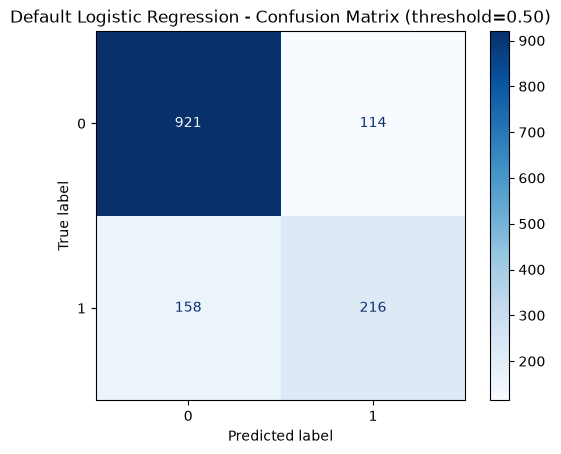

Train F1 Score (0.50): 0.7085
Test  F1 Score (0.50): 0.6136

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.65      0.58      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



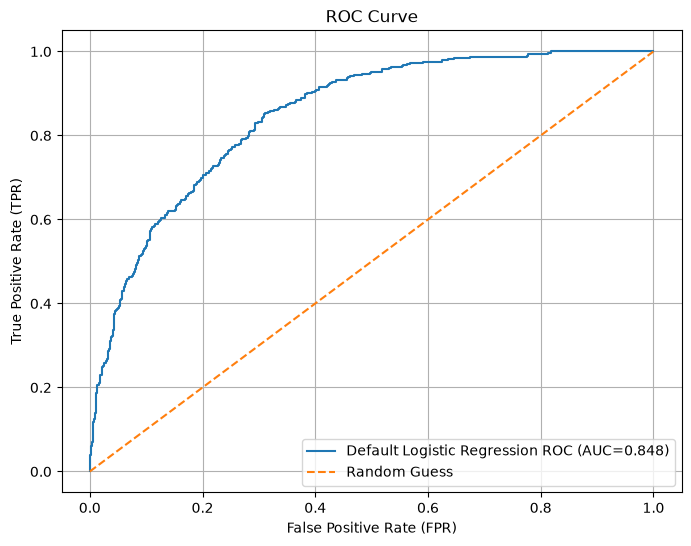

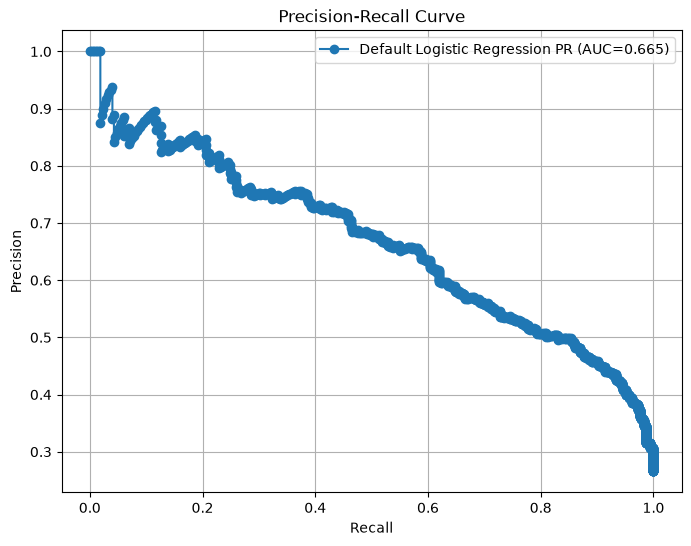

[Default Logistic Regression] Best F1-score = 0.6239 at threshold = 0.20


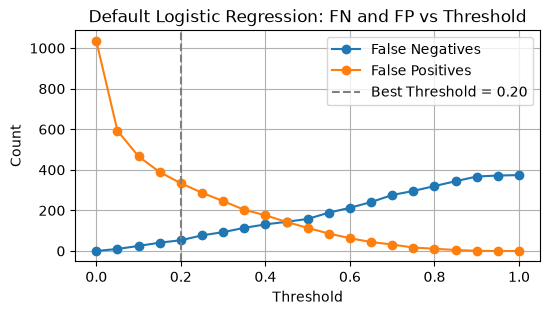

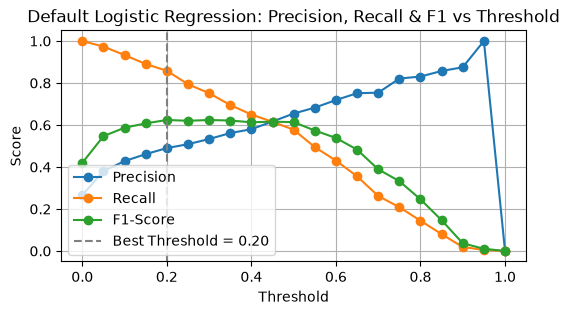

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),...,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.809,0.6136,...,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1


In [24]:
LR= LogisticRegression(random_state=1234)

result_df, Probability_Threshold, Ranking_Threshold= store_results("Default Logistic Regression",X_train_s, y_train,X_test_s, y_test, LR, 5,"L2", 1,"NA")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison 

## Techniques to Handle Imbalanced Data

#### Method 1: Penalize Algorithms (Cost-Sensitive Training)
This tactic is to use penalized learning algorithms that increase the cost of classification mistakes on the minority class.

Confusion matrix (prob threshold = 0.50):
[[769 266]
 [ 89 285]]


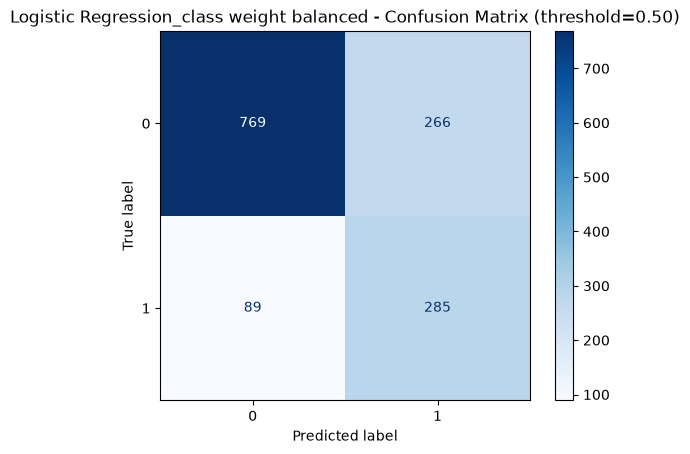

Train F1 Score (0.50): 0.7004
Test  F1 Score (0.50): 0.6162

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1035
           1       0.52      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.75      0.76      1409



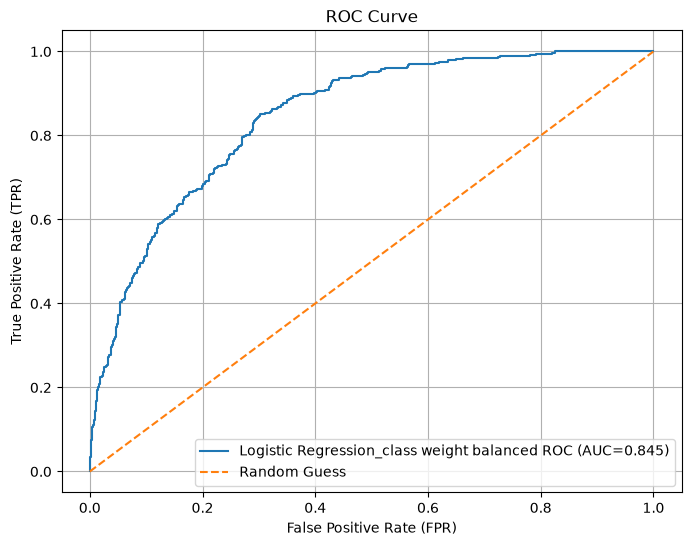

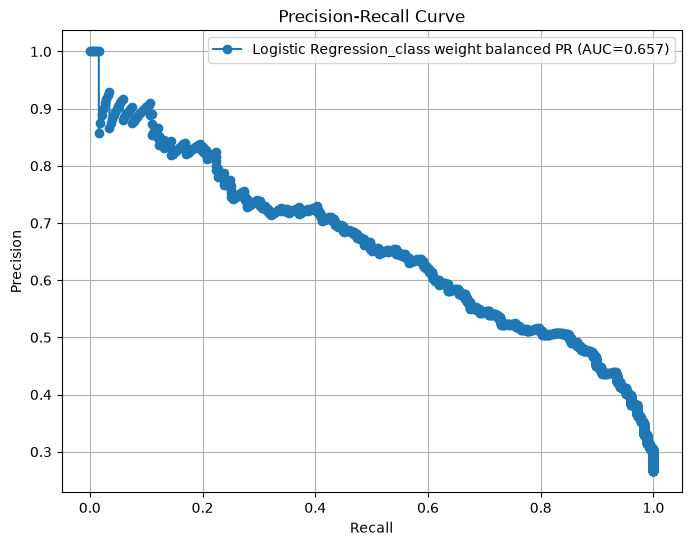

[Logistic Regression_class weight balanced] Best F1-score = 0.6278 at threshold = 0.40


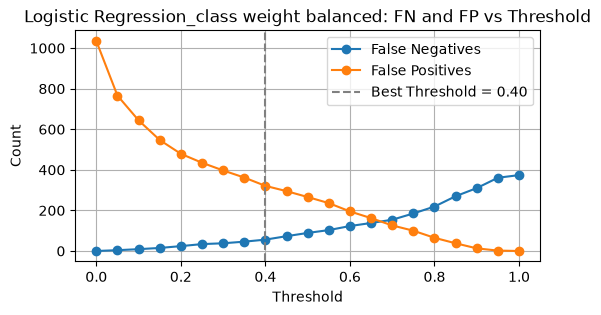

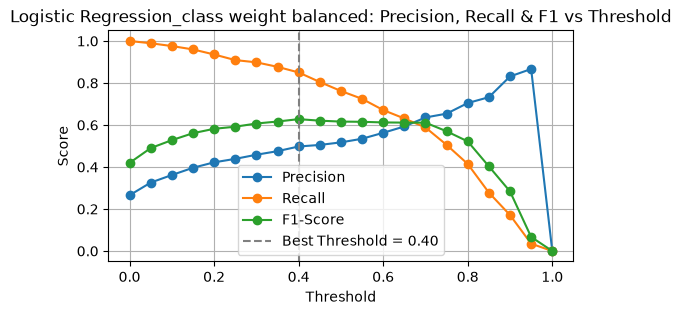

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),...,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,...,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,...,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1


In [25]:
LR_W= LogisticRegression(class_weight='balanced',random_state=1234)

result_df, Probability_Threshold, Ranking_Threshold= store_results("Logistic Regression_class weight balanced",X_train_s, y_train,X_test_s, y_test, LR_W, 5,"L2", 1,"Balanced")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison

### Method 2: Over Sampling

In [26]:
sm  = SMOTE(random_state=0)
X_train_sm, y_train_sm = sm.fit_resample(X_train_s, y_train)

Confusion matrix (prob threshold = 0.50):
[[783 252]
 [101 273]]


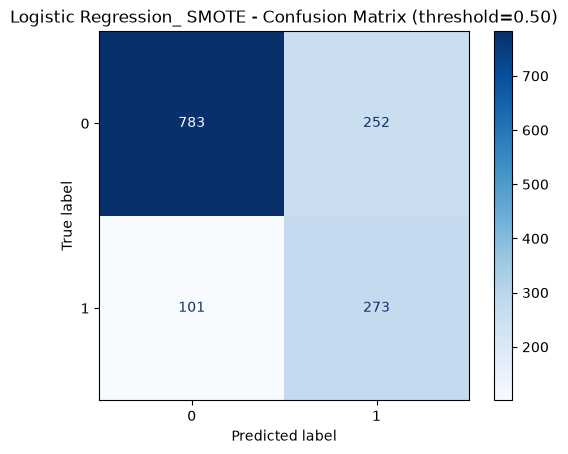

Train F1 Score (0.50): 0.8522
Test  F1 Score (0.50): 0.6073

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.89      0.76      0.82      1035
           1       0.52      0.73      0.61       374

    accuracy                           0.75      1409
   macro avg       0.70      0.74      0.71      1409
weighted avg       0.79      0.75      0.76      1409



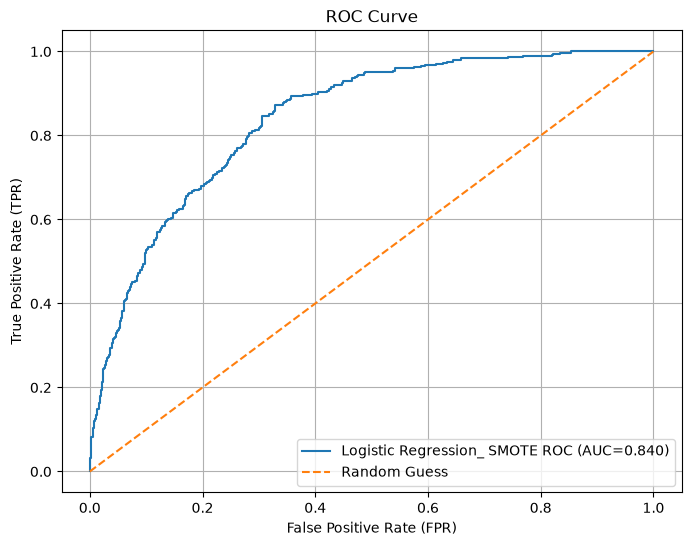

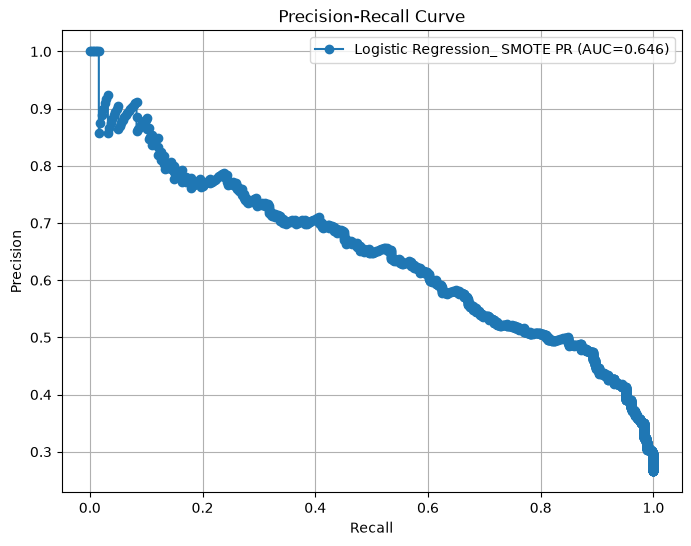

[Logistic Regression_ SMOTE] Best F1-score = 0.6211 at threshold = 0.35


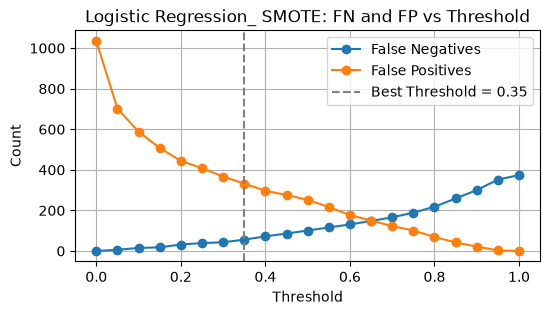

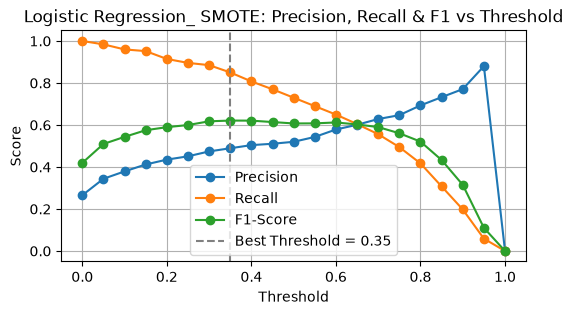

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),...,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,...,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,...,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,...,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1


In [27]:
LR_sm= LogisticRegression(random_state=1234)

result_df, Probability_Threshold, Ranking_Threshold= store_results("Logistic Regression_ SMOTE",X_train_sm, y_train_sm,X_test_s, y_test, LR_sm, 5,"L2", 1,"SMOTE")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison 

In [28]:
pd.options.display.max_columns=500
Model_Comparison

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1


### Method3 : Down-sample Majority Class method

In [29]:
y_train.value_counts()

Churn Value
0    4139
1    1495
Name: count, dtype: int64

In [30]:
df_train=X_train_s.copy()
df_train['Churn Value']=y_train.copy()
df_train.head()

,Gender,Senior_Citizen,Partner,Dependents,Tenure_Months,Phone_Service,Multiple_Lines,Internet_Service,Online_Security,Online_Backup,Device_Protection,Tech_Support,Streaming_TV,Streaming_Movies,Contract,Paperless_Billing,Payment_Method,Monthly_Charges,Total_Charges,CLTV,Tenure_Months_flag,Monthly_Charges_flag,Total_Charges_flag,CLTV_flag,TotalCharge_CityRatio,ACT,TCR,City_Acampo,City_Acton,City_Adelanto,City_Adin,City_Agoura_Hills,City_Aguanga,City_Ahwahnee,City_Alameda,City_Alamo,City_Albany,City_Albion,City_Alderpoint,City_Alhambra,City_Aliso_Viejo,City_Alleghany,City_Alpaugh,City_Alpine,City_Alta,City_Altadena,City_Alturas,City_Alviso,City_Amador_City,City_Amboy,City_Anaheim,City_Anderson,City_Angels_Camp,City_Angelus_Oaks,City_Angwin,City_Annapolis,City_Antelope,City_Antioch,City_Anza,City_Apple_Valley,City_Applegate,City_Aptos,City_Arbuckle,City_Arcadia,City_Arcata,City_Armona,City_Arnold,City_Aromas,City_Arroyo_Grande,City_Artesia,City_Arvin,City_Atascadero,City_Atherton,City_Atwater,City_Auberry,City_Auburn,City_Avalon,City_Avenal,City_Avery,City_Avila_Beach,City_Azusa,City_Badger,City_Baker,City_Bakersfield,City_Baldwin_Park,City_Ballico,City_Bangor,City_Banning,City_Barstow,City_Bass_Lake,City_Bayside,City_Beale_Afb,City_Beaumont,City_Bell,City_Bella_Vista,City_Bellflower,City_Belmont,City_Belvedere_Tiburon,City_Ben_Lomond,City_Benicia,City_Benton,City_Berkeley,City_Berry_Creek,City_Bethel_Island,City_Beverly_Hills,City_Bieber,City_Big_Bar,City_Big_Bear_City,City_Big_Bear_Lake,City_Big_Bend,City_Big_Creek,City_Big_Oak_Flat,City_Big_Pine,City_Big_Sur,City_Biggs,City_Biola,City_Birds_Landing,City_Bishop,City_Blairsden_Graeagle,City_Blocksburg,City_Bloomington,City_Blue_Lake,City_Blythe,City_Bodega,City_Bodega_Bay,City_Bodfish,City_Bolinas,City_Bonita,City_Bonsall,City_Boonville,City_Boron,City_Borrego_Springs,City_Boulder_Creek,City_Boulevard,City_Bradley,City_Branscomb,City_Brawley,City_Brea,City_Brentwood,City_Bridgeport,City_Bridgeville,City_Brisbane,City_Brookdale,City_Brooks,City_Browns_Valley,City_Brownsville,City_Buellton,City_Buena_Park,City_Burbank,City_Burlingame,City_Burney,City_Burnt_Ranch,City_Burson,City_Butte_City,City_Buttonwillow,City_Byron,City_Cabazon,City_Calabasas,City_Calexico,City_Caliente,City_California_City,City_California_Hot_Springs,City_Calimesa,City_Calipatria,City_Calistoga,City_Callahan,City_Calpine,City_Camarillo,City_Cambria,City_Camino,City_Camp_Nelson,City_Campbell,City_Campo,City_Campo_Seco,City_Camptonville,City_Canby,City_Canoga_Park,City_Cantua_Creek,City_Canyon_Country,City_Canyon_Dam,City_Capay,City_Capistrano_Beach,City_Capitola,City_Cardiff_By_The_Sea,City_Carlotta,City_Carlsbad,City_Carmel,City_Carmel_By_The_Sea,City_Carmel_Valley,City_Carmichael,City_Carnelian_Bay,City_Carpinteria,City_Carson,City_Caruthers,City_Casmalia,City_Caspar,City_Cassel,City_Castaic,City_Castella,City_Castro_Valley,City_Castroville,City_Cathedral_City,City_Catheys_Valley,City_Cayucos,City_Cedar_Glen,City_Cedarville,City_Ceres,City_Cerritos,City_Challenge,City_Chatsworth,City_Chester,City_Chico,City_Chilcoot,City_Chino,City_Chino_Hills,City_Chowchilla,City_Chualar,City_Chula_Vista,City_Citrus_Heights,City_Claremont,City_Clarksburg,City_Clayton,City_Clearlake,City_Clearlake_Oaks,City_Clements,City_Clio,City_Clipper_Mills,City_Cloverdale,City_Clovis,City_Coachella,City_Coalinga,City_Coarsegold,City_Cobb,City_Coleville,City_Colfax,City_Colton,City_Columbia,City_Colusa,City_Comptche,City_Compton,City_Concord,City_Cool,City_Copperopolis,City_Corcoran,City_Corning,City_Corona,City_Corona_Del_Mar,City_Coronado,City_Corte_Madera,City_Costa_Mesa,...,City_San_Juan_Capistrano,City_San_Leandro,City_San_Lorenzo,City_San_Lucas,City_San_Luis_Obispo,City_San_Marcos,City_San_Marino,City_San_Martin,City_San_Mateo,City_San_Miguel,City_San_Pablo,City_San_Pedro,City_San_Quentin,City_San_Rafael,City_San_Ramon,City_San_Simeon,City_San_Ysidro,City_Sanger,City_Santa_Ana,City_Santa_Barbara,City_Santa_Clara,City_Santa_Clarita,Ci

In [31]:
n1=df_train['Churn Value'].value_counts()[1]
n1

np.int64(1495)

In [32]:
df_train['Churn Value'].value_counts()

Churn Value
0    4139
1    1495
Name: count, dtype: int64

In [33]:
# Separate majority and minority classes
df_majority = df_train[df_train['Churn Value']==0]
df_minority =df_train[df_train['Churn Value']==1]

In [34]:
from sklearn.utils import resample
# Downsample majority class
df_majority_downsampled = resample(df_majority, 
                                 replace=False,    # sample without replacement
                                 n_samples=n1,     # to match minority class
                                 random_state=0) # reproducible results

In [35]:
len(df_majority_downsampled)

1495

In [36]:
# Combine majority class with upsampled minority class
dfb = pd.concat([df_majority_downsampled, df_minority], ignore_index=True)

In [37]:
dfb['Churn Value'].value_counts()

Churn Value
0    1495
1    1495
Name: count, dtype: int64

In [38]:
X_train_d=dfb.drop('Churn Value',axis=1)

y_train_d=dfb['Churn Value']

Confusion matrix (prob threshold = 0.50):
[[749 286]
 [ 80 294]]


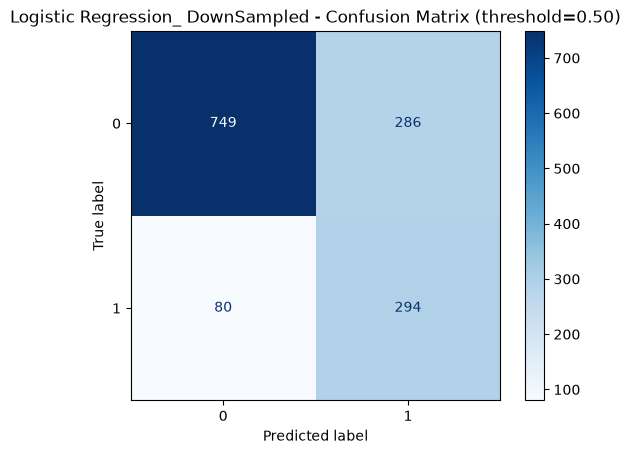

Train F1 Score (0.50): 0.8285
Test  F1 Score (0.50): 0.6164

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



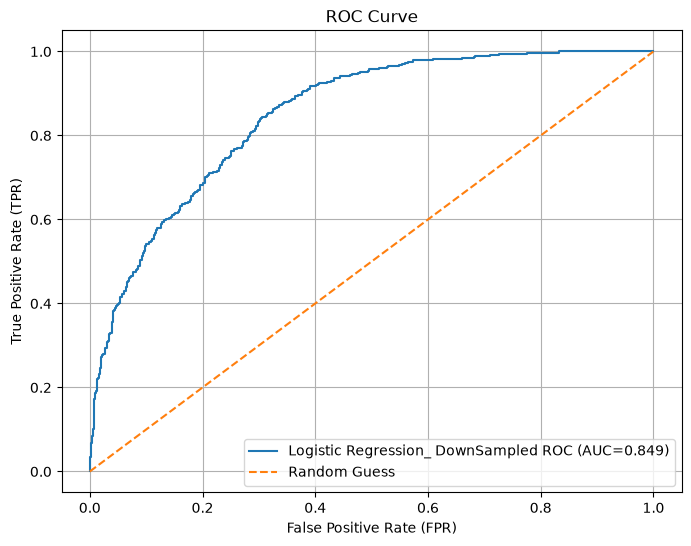

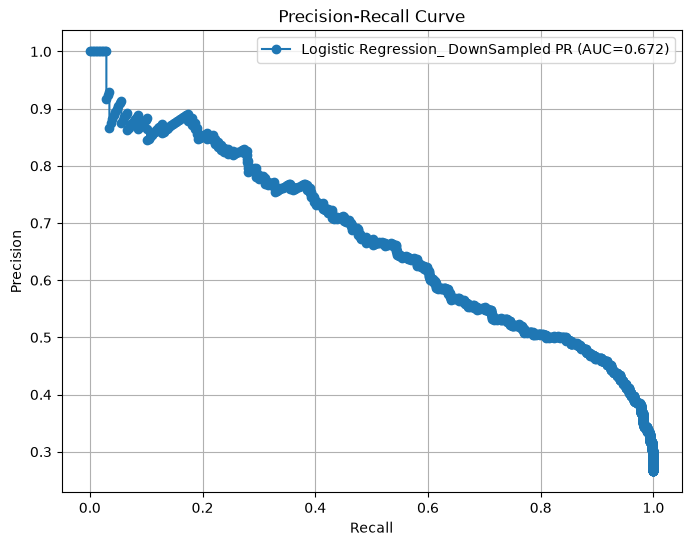

[Logistic Regression_ DownSampled] Best F1-score = 0.6226 at threshold = 0.40


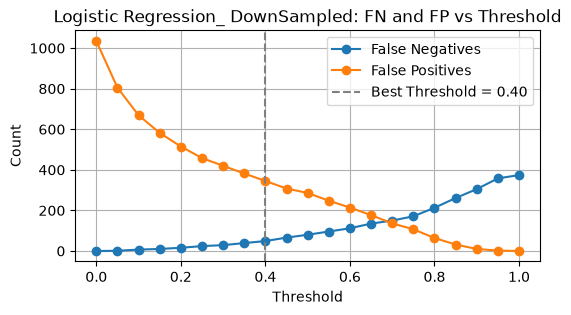

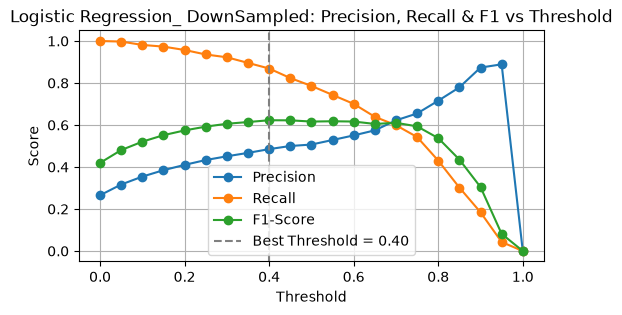

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1


In [39]:
LR_d= LogisticRegression(random_state=1234)

result_df, Probability_Threshold, Ranking_Threshold= store_results("Logistic Regression_ DownSampled",X_train_d, y_train_d,X_test_s, y_test, LR_d, 5,"L2", 1,"DownSampled")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison 

# Logistic Regression with Lasso Regularization (L1)

## Key Parameters:

- `penalty='l1'`: Specifies the use of L1 regularization.
- `solver='saga'`: The optimization algorithm used for solving logistic regression with L1 regularization.
- `C=1.0`: Sets the inverse of the regularization strength. Smaller values specify stronger regularization.


Confusion matrix (prob threshold = 0.50):
[[758 277]
 [ 79 295]]


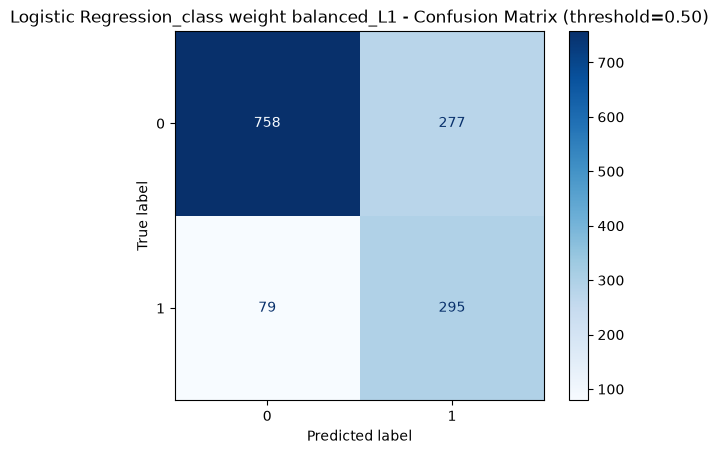

Train F1 Score (0.50): 0.6459
Test  F1 Score (0.50): 0.6237

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.52      0.79      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



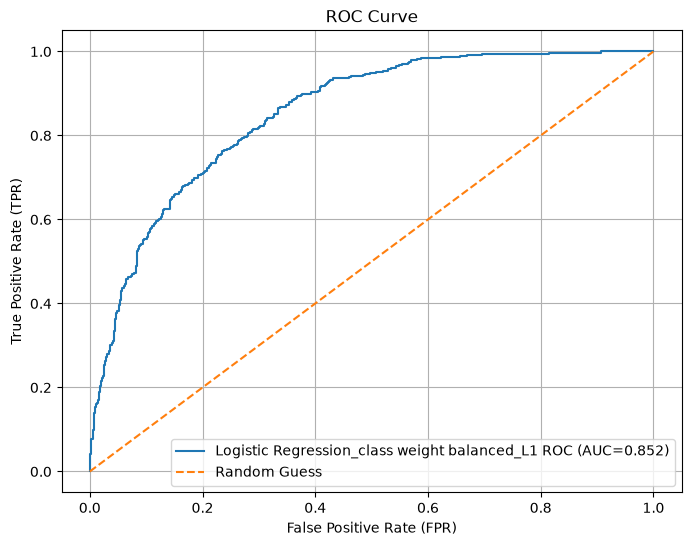

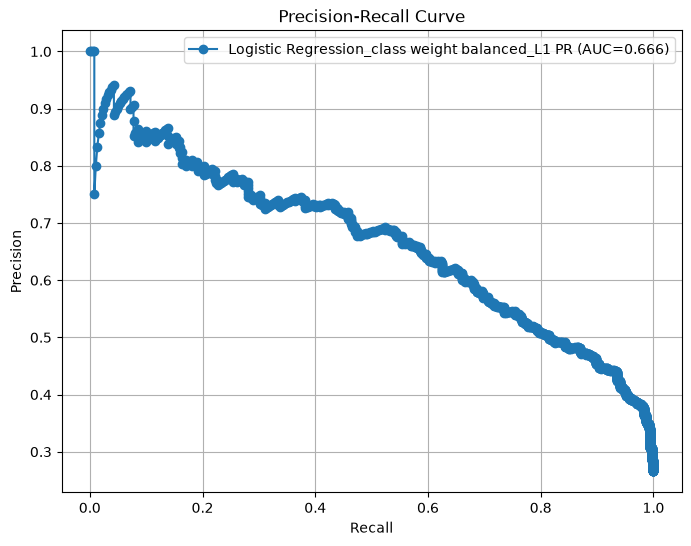

[Logistic Regression_class weight balanced_L1] Best F1-score = 0.6310 at threshold = 0.65


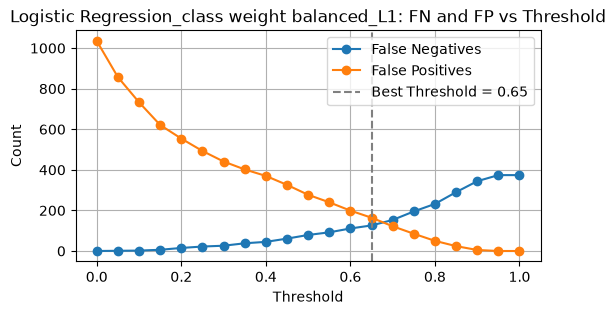

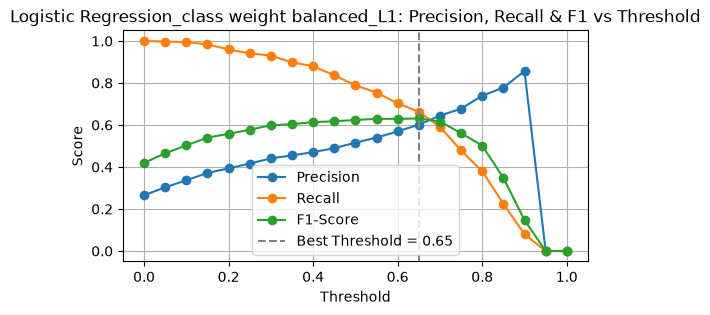

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1


In [40]:
LR_W2= LogisticRegression(penalty='l1', solver='saga',C=1.0,class_weight='balanced',random_state=1234)

result_df, Probability_Threshold, Ranking_Threshold= store_results("Logistic Regression_class weight balanced_L1",X_train_s, y_train,X_test_s, y_test, LR_W2, 5,"L1", 1,"Balanced")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison 

In [41]:
LR_W2.coef_

array([[0.02650267, 0.19408451, 0.05840188, ..., 0.        , 0.        ,
        0.        ]], shape=(1, 1155))

# Logistic Regression with Ridge Regularization (L2)

Confusion matrix (prob threshold = 0.50):
[[769 266]
 [ 90 284]]


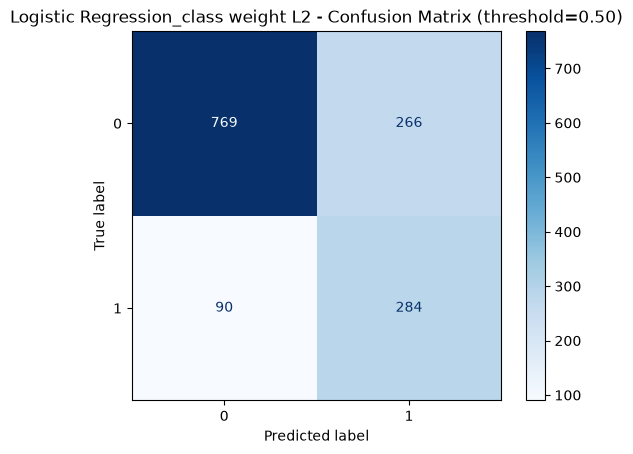

Train F1 Score (0.50): 0.7016
Test  F1 Score (0.50): 0.6147

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1035
           1       0.52      0.76      0.61       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



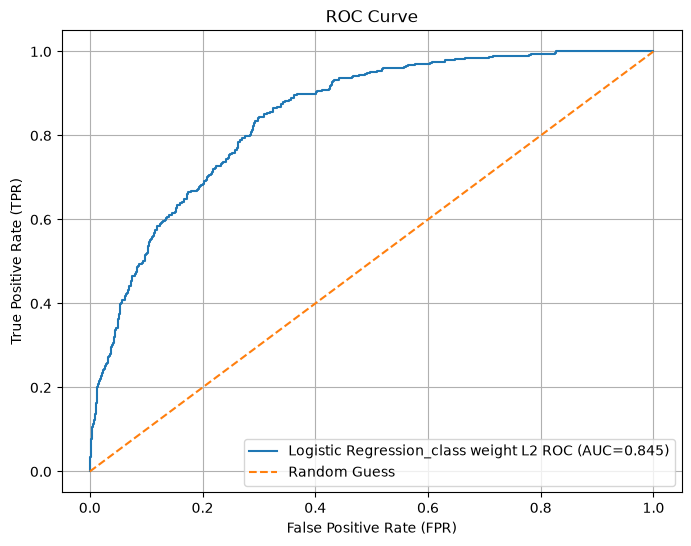

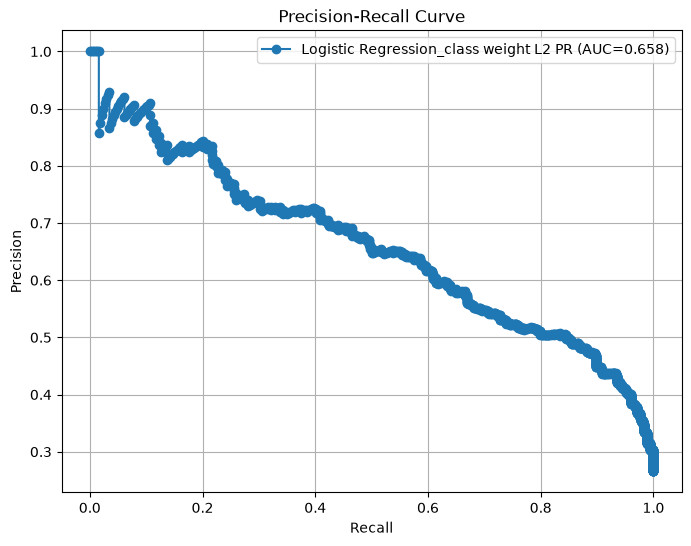

[Logistic Regression_class weight L2] Best F1-score = 0.6278 at threshold = 0.40


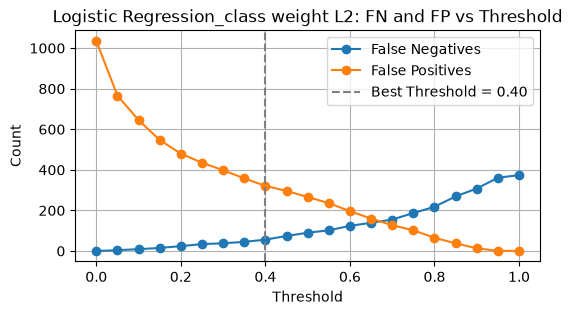

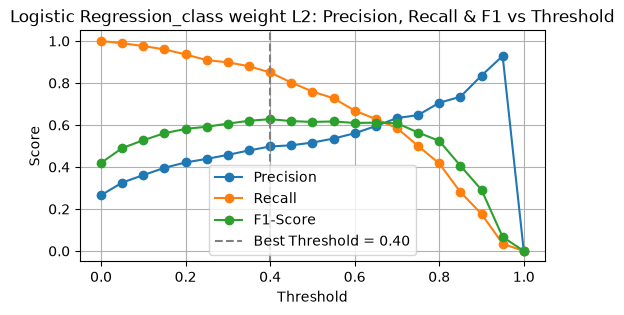

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1


In [42]:
#for Ridge
LR_W3 =LogisticRegression(
    penalty='l2',
    solver='lbfgs',
    C=1.0,
    class_weight='balanced',
    random_state=1234,
    max_iter=1000
)
result_df, Probability_Threshold, Ranking_Threshold= store_results("Logistic Regression_class weight L2",X_train_s, y_train,X_test_s, y_test, LR_W3, 5,"L2", 1,"Balanced")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison 

Confusion matrix (prob threshold = 0.50):
[[941  94]
 [ 27 347]]


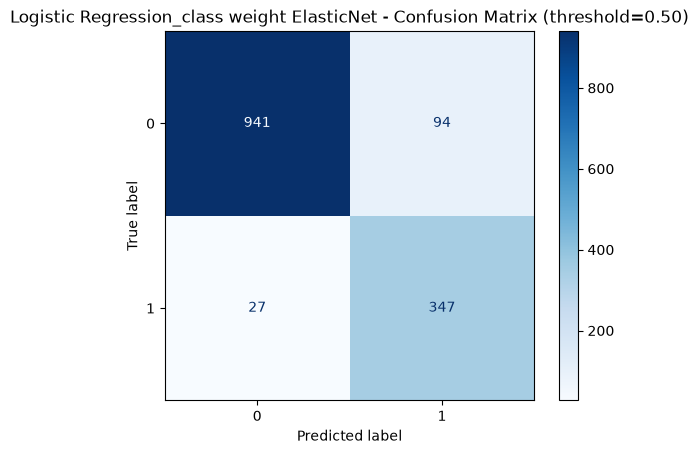

Train F1 Score (0.50): 0.8507
Test  F1 Score (0.50): 0.8515

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.97      0.91      0.94      1035
           1       0.79      0.93      0.85       374

    accuracy                           0.91      1409
   macro avg       0.88      0.92      0.90      1409
weighted avg       0.92      0.91      0.92      1409



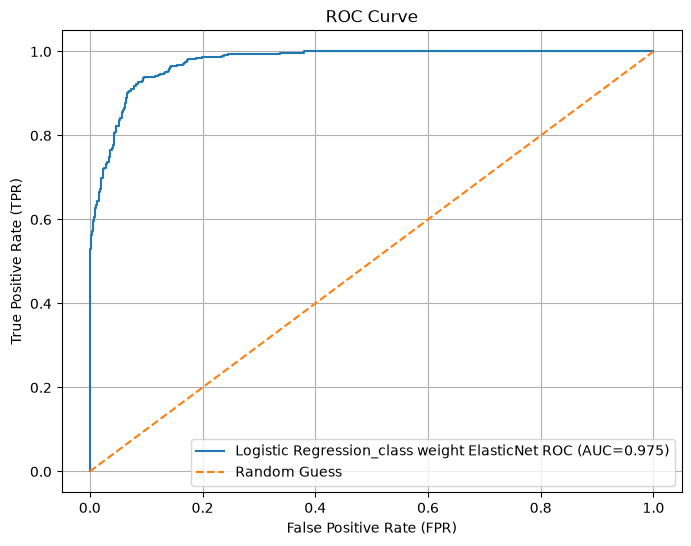

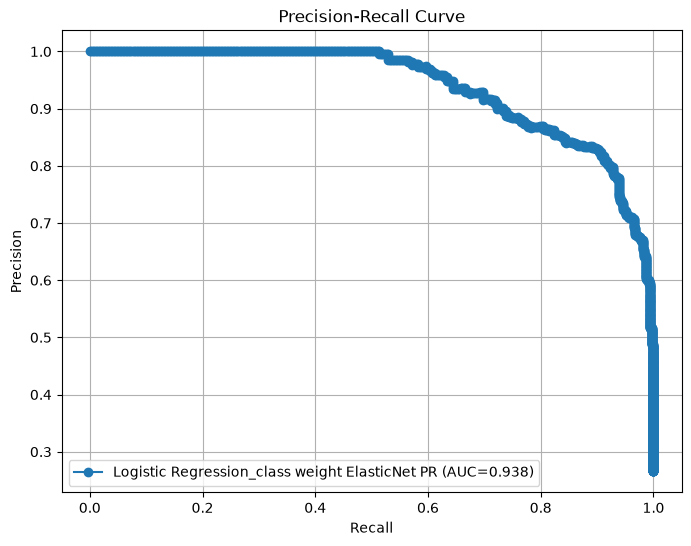

[Logistic Regression_class weight ElasticNet] Best F1-score = 0.8608 at threshold = 0.60


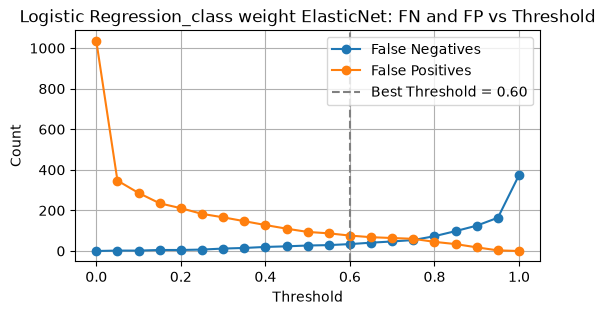

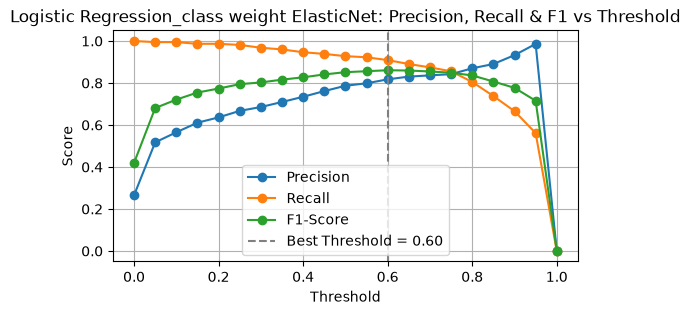

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.9759,0.9625,0.9409,0.0215,0.0055,0.9757,0.9212,0.8509,0.9388,0.9397,0.9233,0.8857,0.8571,0.860825,0.40,0.8514,0.8501,0.8419,0.8447,0.8666,0.9432,0.9375,0.9305,0.9367,0.9462,1.0,0.0381,3.7686,1.0,0.0401,3.7674,1.0,0.1886,3.7686,1.0,0.1898,3.7674,1.0000,0.3773,3.7686,1.0000,0.3770,3.7674,L2,1.0
1,Logistic Regression_class weight balanced,Balanced,0.9754,0.9609,0.9399,0.0210,0.0054,0.9756,0.9132,0.8489,0.9384,0.9326,0.9163,0.8829,0.8536,0.859296,0.55,0.8625,0.8263,0.8428,0.8397,0.8734,0.9426,0.9369,0.9301,0.9367,0.9457,1.0,0.0381,3.7686,1.0,0.0401,3.7674,1.0,0.1886,3.7686,1.0,0.1898,3.7674,1.0000,0.3773,3.7686,1.0000,0.3770,3.7674,L2,1.0
2,Logistic Regression_ SMOTE,SMOTE,0.9752,0.9888,0.9394,0.0494,0.0022,0.9835,0.9337,0.9346,0.9822,0.9488,0.9219,0.9496,0.8608,0.861538,0.55,0.9378,0.9242,0.9407,0.9279,0.9426,0.9852,0.9803,0.9810,0.9801,0.9843,1.0,0.0201,2.0000,1.0,0.0401,3.7674,1.0,0.1000,2.0000,1.0,0.1898,3.7674,1.0000,0.2000,2.0000,1.0000,0.3770,3.7674,L2,1.0
3,Logistic Regression_ DownSampled,DownSampled,0.9756,0.9872,0.9411,0.0460,0.0018,0.9768,0.9184,0.9194,0.9757,0.9405,0.9148,0.9413,0.8529,0.852941,0.50,0.9281,0.9213,0.9135,0.9198,0.9143,0.9730,0.9772,0.9761,0.9743,0.9778,1.0,0.0201,2.0000,1.0,0.0401,3.7674,1.0,0.1003,2.0000,1.0,0.1898,3.7674,1.0000,0.2000,2.0000,1.0000,0.3770,3.7674,L2,1.0
4,Logistic Regression_class weight balanced_L1,Balanced,0.9701,0.9319,0.9259,0.0061,0.0054,0.9713,0.8963,0.8276,0.9299,0.8958,0.8992,0.8268,0.8329,0.847150,0.65,0.8391,0.8081,0.8269,0.8156,0.8485,0.9351,0.9201,0.9286,0.9336,0.9321,1.0,0.0381,3.7686,1.0,0.0401,3.7674,1.0,0.1886,3.7686,1.0,0.1898,3.7674,0.9982,0.3766,3.7619,0.9929,0.3743,3.7407,L1,1.0
5,Logistic Regression_class weight L2,Balanced,0.9754,0.9609,0.9399,0.0210,0.0054,0.9756,0.9132,0.8489,0.9384,0.9326,0.9163,0.8829,0.8536,0.859296,0.55,0.8625,0.8263,0.8428,0.8397,0.8734,0.9426,0.9369,0.9301,0.9367,0.9457,1.0,0.0381,3.7686,1.0,0.0401,3.7674,1.0,0.1886,3.7686,1.0,0.1898,3.7674,1.0000,0.3773,3.7686,1.0000,0.3770,3.7674,L2,1.0
6,Logistic Regression_class weight ElasticNet,Balanced,0.9749,0.9422,0.9384,0.0038,0.0055,0.9765,0.9111,0.8481,0.9402,0.9127,0.9141,0.8507,0.8515,0.860759,0.60,0.8731,0.8242,0.8318,0.8430,0.8682,0.9454,0.9383,0.9311,0.9399,0.9464,1.0,0.0381,3.7686,1.0,0.0401,3.7674,1.0,0.1886,3.7686,1.0,0.1898,3.7674,0.9982,0.3766,3.7619,1.0000,0.3770,3.7674,ElasticNet,0.5


In [46]:
LR_W4 = LogisticRegression(
    penalty='elasticnet',
    solver='saga',
    l1_ratio=0.5,
    C=0.5,
    class_weight='balanced',
    random_state=1234,
    max_iter=1000,
    n_jobs=-1
)

result_df, Probability_Threshold, Ranking_Threshold= store_results("Logistic Regression_class weight ElasticNet",X_train_s, y_train,X_test_s, y_test, LR_W4, 5,"ElasticNet", 0.5,"Balanced")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison 

### Feature Selection
### Feature Selection Using RFE
Recursive Feature Elimination (RFE) is an automated feature elimination algorithm.Recursive feature elimination is based on the idea of repeatedly constructing a model (for example, an SVM or a regression model) and choosing either the best or the worst performing feature (for example, based on coefficients), setting the feature aside and then repeating the process with the rest of the features. This process is applied until all the features in the data set are exhausted. Features are then ranked according to when they were eliminated.  As such, it is a greedy optimisation for finding the best performing subset of features. The RFE object takes two arguments, a machine learning object and an integer, to represent the number of features to keep. RFE trains a model of the given ML algorithm, finds the least important feature, and eliminates it. Then it retrains a new model and again finds the least important feature to eliminate. This repeats until the specified number of features are left.

In [43]:
from sklearn.feature_selection import RFE


rfe = RFE(LR_W,n_features_to_select = 20)           # running RFE with 20 variable output. # 20 is a arbitrary number. 
rfe = rfe.fit(X_train_s, y_train)

In [44]:
col = X_train_s.columns[rfe.support_]
col

Index(['Dependents', 'Monthly_Charges', 'Total_Charges', 'City_Atherton',
       'City_Beverly_Hills', 'City_Bradley', 'City_Compton', 'City_Crockett',
       'City_Elk_Grove', 'City_Emeryville', 'City_Gardena',
       'City_Grizzly_Flats', 'City_Redondo_Beach', 'City_Running_Springs',
       'City_Saint_Helena', 'City_San_Dimas', 'City_Santa_Maria',
       'City_Seeley', 'City_Smith_River', 'City_Upland'],
      dtype='object')

### Dropped Columns after RFE

Retrain the model after RFE--DO IT

In [45]:
X_train_s.columns[~rfe.support_]

Index(['Gender', 'Senior_Citizen', 'Partner', 'Tenure_Months', 'Phone_Service',
       'Multiple_Lines', 'Internet_Service', 'Online_Security',
       'Online_Backup', 'Device_Protection',
       ...
       'City_Yermo', 'City_Yorba_Linda', 'City_Yorkville',
       'City_Yosemite_National_Park', 'City_Yountville', 'City_Yreka',
       'City_Yuba_City', 'City_Yucaipa', 'City_Yucca_Valley', 'City_Zenia'],
      dtype='object', length=1135)

# """Decision Tree """

#### `So Decision Trees are not sensitve to missing values,Outliers,imbalanced data and do not require normalization`

In [46]:
X_train=X_train_tree.copy()
y_train =y_train_tree.copy()
X_test=X_test_tree.copy()
y_test = y_test_tree.copy()

In [47]:
X_train.head()

,Gender,Senior_Citizen,Partner,Dependents,Tenure_Months,Phone_Service,Multiple_Lines,Internet_Service,Online_Security,Online_Backup,Device_Protection,Tech_Support,Streaming_TV,Streaming_Movies,Contract,Paperless_Billing,Payment_Method,Monthly_Charges,Total_Charges,CLTV,TotalCharge_CityRatio,ACT,TCR,City_Acampo,City_Acton,City_Adelanto,City_Adin,City_Agoura_Hills,City_Aguanga,City_Ahwahnee,City_Alameda,City_Alamo,City_Albany,City_Albion,City_Alderpoint,City_Alhambra,City_Aliso_Viejo,City_Alleghany,City_Alpaugh,City_Alpine,City_Alta,City_Altadena,City_Alturas,City_Alviso,City_Amador_City,City_Amboy,City_Anaheim,City_Anderson,City_Angels_Camp,City_Angelus_Oaks,City_Angwin,City_Annapolis,City_Antelope,City_Antioch,City_Anza,City_Apple_Valley,City_Applegate,City_Aptos,City_Arbuckle,City_Arcadia,City_Arcata,City_Armona,City_Arnold,City_Aromas,City_Arroyo_Grande,City_Artesia,City_Arvin,City_Atascadero,City_Atherton,City_Atwater,City_Auberry,City_Auburn,City_Avalon,City_Avenal,City_Avery,City_Avila_Beach,City_Azusa,City_Badger,City_Baker,City_Bakersfield,City_Baldwin_Park,City_Ballico,City_Bangor,City_Banning,City_Barstow,City_Bass_Lake,City_Bayside,City_Beale_Afb,City_Beaumont,City_Bell,City_Bella_Vista,City_Bellflower,City_Belmont,City_Belvedere_Tiburon,City_Ben_Lomond,City_Benicia,City_Benton,City_Berkeley,City_Berry_Creek,City_Bethel_Island,City_Beverly_Hills,City_Bieber,City_Big_Bar,City_Big_Bear_City,City_Big_Bear_Lake,City_Big_Bend,City_Big_Creek,City_Big_Oak_Flat,City_Big_Pine,City_Big_Sur,City_Biggs,City_Biola,City_Birds_Landing,City_Bishop,City_Blairsden_Graeagle,City_Blocksburg,City_Bloomington,City_Blue_Lake,City_Blythe,City_Bodega,City_Bodega_Bay,City_Bodfish,City_Bolinas,City_Bonita,City_Bonsall,City_Boonville,City_Boron,City_Borrego_Springs,City_Boulder_Creek,City_Boulevard,City_Bradley,City_Branscomb,City_Brawley,City_Brea,City_Brentwood,City_Bridgeport,City_Bridgeville,City_Brisbane,City_Brookdale,City_Brooks,City_Browns_Valley,City_Brownsville,City_Buellton,City_Buena_Park,City_Burbank,City_Burlingame,City_Burney,City_Burnt_Ranch,City_Burson,City_Butte_City,City_Buttonwillow,City_Byron,City_Cabazon,City_Calabasas,City_Calexico,City_Caliente,City_California_City,City_California_Hot_Springs,City_Calimesa,City_Calipatria,City_Calistoga,City_Callahan,City_Calpine,City_Camarillo,City_Cambria,City_Camino,City_Camp_Nelson,City_Campbell,City_Campo,City_Campo_Seco,City_Camptonville,City_Canby,City_Canoga_Park,City_Cantua_Creek,City_Canyon_Country,City_Canyon_Dam,City_Capay,City_Capistrano_Beach,City_Capitola,City_Cardiff_By_The_Sea,City_Carlotta,City_Carlsbad,City_Carmel,City_Carmel_By_The_Sea,City_Carmel_Valley,City_Carmichael,City_Carnelian_Bay,City_Carpinteria,City_Carson,City_Caruthers,City_Casmalia,City_Caspar,City_Cassel,City_Castaic,City_Castella,City_Castro_Valley,City_Castroville,City_Cathedral_City,City_Catheys_Valley,City_Cayucos,City_Cedar_Glen,City_Cedarville,City_Ceres,City_Cerritos,City_Challenge,City_Chatsworth,City_Chester,City_Chico,City_Chilcoot,City_Chino,City_Chino_Hills,City_Chowchilla,City_Chualar,City_Chula_Vista,City_Citrus_Heights,City_Claremont,City_Clarksburg,City_Clayton,City_Clearlake,City_Clearlake_Oaks,City_Clements,City_Clio,City_Clipper_Mills,City_Cloverdale,City_Clovis,City_Coachella,City_Coalinga,City_Coarsegold,City_Cobb,City_Coleville,City_Colfax,City_Colton,City_Columbia,City_Colusa,City_Comptche,City_Compton,City_Concord,City_Cool,City_Copperopolis,City_Corcoran,City_Corning,City_Corona,City_Corona_Del_Mar,City_Coronado,City_Corte_Madera,City_Costa_Mesa,City_Cotati,City_Cottonwood,City_Coulterville,City_Courtland,...,City_San_Juan_Bautista,City_San_Juan_Capistrano,City_San_Leandro,City_San_Lorenzo,City_San_Lucas,City_San_Luis_Obispo,City_San_Marcos,City_San_Marino,City_San_Martin,City_San_Mateo,City_San_Miguel,City_San_Pablo,City_San_Pedro,City_San_Quentin,City_San_Rafael,City_San_Ramon,City_San_Simeon,City_San_Ysidro,City_Sanger,City_Santa_Ana,City_Santa_Barbara,City_Santa_Clara,City_S

In [48]:
X_train.describe()

,Gender,Senior_Citizen,Partner,Dependents,Tenure_Months,Phone_Service,Multiple_Lines,Internet_Service,Online_Security,Online_Backup,Device_Protection,Tech_Support,Streaming_TV,Streaming_Movies,Contract,Paperless_Billing,Payment_Method,Monthly_Charges,Total_Charges,CLTV,TotalCharge_CityRatio,ACT,TCR,City_Acampo,City_Acton,City_Adelanto,City_Adin,City_Agoura_Hills,City_Aguanga,City_Ahwahnee,City_Alameda,City_Alamo,City_Albany,City_Albion,City_Alderpoint,City_Alhambra,City_Aliso_Viejo,City_Alleghany,City_Alpaugh,City_Alpine,City_Alta,City_Altadena,City_Alturas,City_Alviso,City_Amador_City,City_Amboy,City_Anaheim,City_Anderson,City_Angels_Camp,City_Angelus_Oaks,City_Angwin,City_Annapolis,City_Antelope,City_Antioch,City_Anza,City_Apple_Valley,City_Applegate,City_Aptos,City_Arbuckle,City_Arcadia,City_Arcata,City_Armona,City_Arnold,City_Aromas,City_Arroyo_Grande,City_Artesia,City_Arvin,City_Atascadero,City_Atherton,City_Atwater,City_Auberry,City_Auburn,City_Avalon,City_Avenal,City_Avery,City_Avila_Beach,City_Azusa,City_Badger,City_Baker,City_Bakersfield,City_Baldwin_Park,City_Ballico,City_Bangor,City_Banning,City_Barstow,City_Bass_Lake,City_Bayside,City_Beale_Afb,City_Beaumont,City_Bell,City_Bella_Vista,City_Bellflower,City_Belmont,City_Belvedere_Tiburon,City_Ben_Lomond,City_Benicia,City_Benton,City_Berkeley,City_Berry_Creek,City_Bethel_Island,City_Beverly_Hills,City_Bieber,City_Big_Bar,City_Big_Bear_City,City_Big_Bear_Lake,City_Big_Bend,City_Big_Creek,City_Big_Oak_Flat,City_Big_Pine,City_Big_Sur,City_Biggs,City_Biola,City_Birds_Landing,City_Bishop,City_Blairsden_Graeagle,City_Blocksburg,City_Bloomington,City_Blue_Lake,City_Blythe,City_Bodega,City_Bodega_Bay,City_Bodfish,City_Bolinas,City_Bonita,City_Bonsall,City_Boonville,City_Boron,City_Borrego_Springs,City_Boulder_Creek,City_Boulevard,City_Bradley,City_Branscomb,City_Brawley,City_Brea,City_Brentwood,City_Bridgeport,City_Bridgeville,City_Brisbane,City_Brookdale,City_Brooks,City_Browns_Valley,City_Brownsville,City_Buellton,City_Buena_Park,City_Burbank,City_Burlingame,City_Burney,City_Burnt_Ranch,City_Burson,City_Butte_City,City_Buttonwillow,City_Byron,City_Cabazon,City_Calabasas,City_Calexico,City_Caliente,City_California_City,City_California_Hot_Springs,City_Calimesa,City_Calipatria,City_Calistoga,City_Callahan,City_Calpine,City_Camarillo,City_Cambria,City_Camino,City_Camp_Nelson,City_Campbell,City_Campo,City_Campo_Seco,City_Camptonville,City_Canby,City_Canoga_Park,City_Cantua_Creek,City_Canyon_Country,City_Canyon_Dam,City_Capay,City_Capistrano_Beach,City_Capitola,City_Cardiff_By_The_Sea,City_Carlotta,City_Carlsbad,City_Carmel,City_Carmel_By_The_Sea,City_Carmel_Valley,City_Carmichael,City_Carnelian_Bay,City_Carpinteria,City_Carson,City_Caruthers,City_Casmalia,City_Caspar,City_Cassel,City_Castaic,City_Castella,City_Castro_Valley,City_Castroville,City_Cathedral_City,City_Catheys_Valley,City_Cayucos,City_Cedar_Glen,City_Cedarville,City_Ceres,City_Cerritos,City_Challenge,City_Chatsworth,City_Chester,City_Chico,City_Chilcoot,City_Chino,City_Chino_Hills,City_Chowchilla,City_Chualar,City_Chula_Vista,City_Citrus_Heights,City_Claremont,City_Clarksburg,City_Clayton,City_Clearlake,City_Clearlake_Oaks,City_Clements,City_Clio,City_Clipper_Mills,City_Cloverdale,City_Clovis,City_Coachella,City_Coalinga,City_Coarsegold,City_Cobb,City_Coleville,City_Colfax,City_Colton,City_Columbia,City_Colusa,City_Comptche,City_Compton,City_Concord,City_Cool,City_Copperopolis,City_Corcoran,City_Corning,City_Corona,City_Corona_Del_Mar,City_Coronado,City_Corte_Madera,City_Costa_Mesa,City_Cotati,City_Cottonwood,City_Coulterville,City_Courtland,...,City_San_Juan_Bautista,City_San_Juan_Capistrano,City_San_Leandro,City_San_Lorenzo,City_San_Lucas,City_San_Luis_Obispo,City_San_Marcos,City_San_Marino,City_San_Martin,City_San_Mateo,City_San_Miguel,City_San_Pablo,City_San_Pedro,City_San_Quentin,City_San_Rafael,City_San_Ramon,City_San_Simeon,City_San_Ysidro,City_Sanger,City_Santa_Ana,City_Santa_Barbara,City_Santa_Clara,City_S

Confusion matrix (prob threshold = 0.50):
[[670 365]
 [ 59 315]]


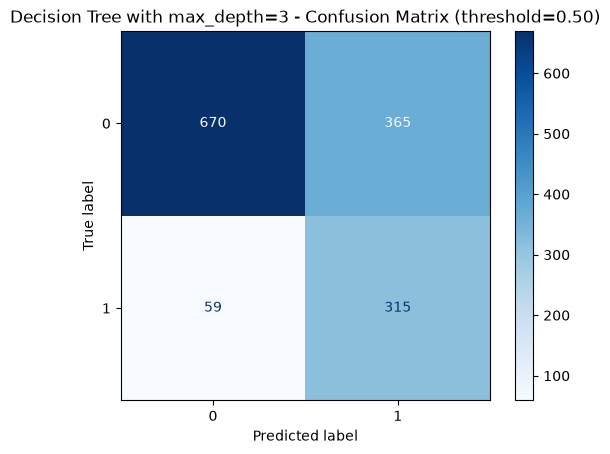

Train F1 Score (0.50): 0.6102
Test  F1 Score (0.50): 0.5977

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.92      0.65      0.76      1035
           1       0.46      0.84      0.60       374

    accuracy                           0.70      1409
   macro avg       0.69      0.74      0.68      1409
weighted avg       0.80      0.70      0.72      1409



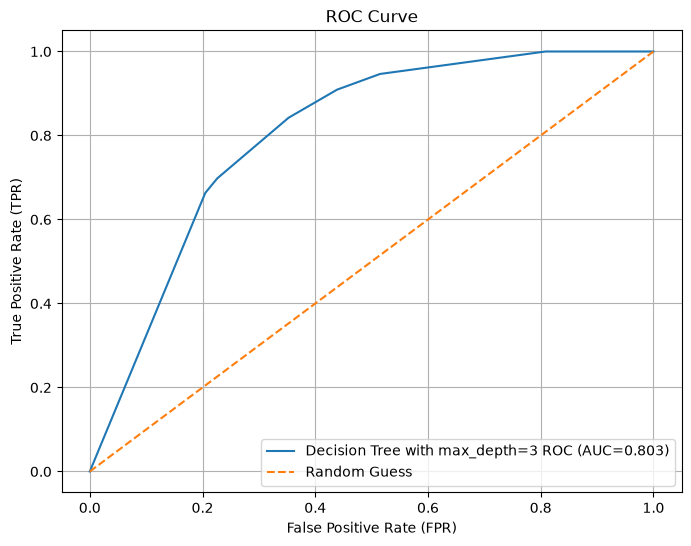

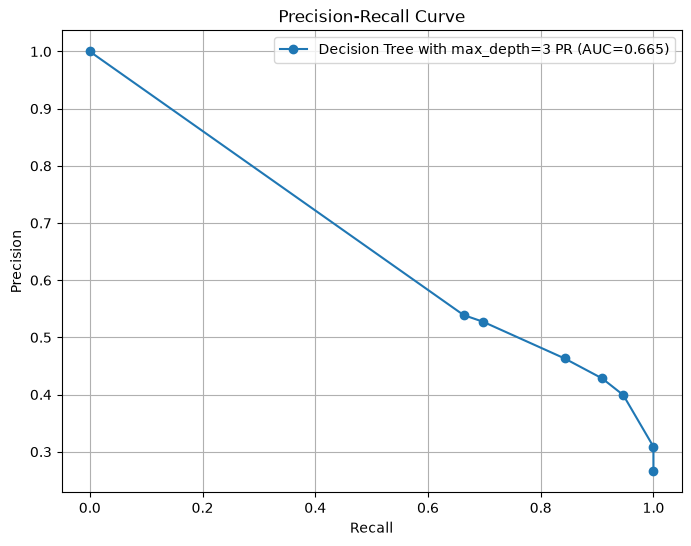

[Decision Tree with max_depth=3] Best F1-score = 0.6007 at threshold = 0.55


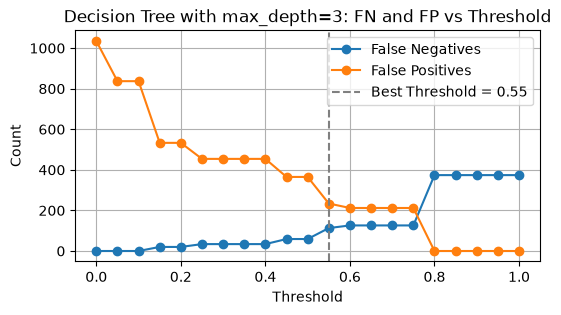

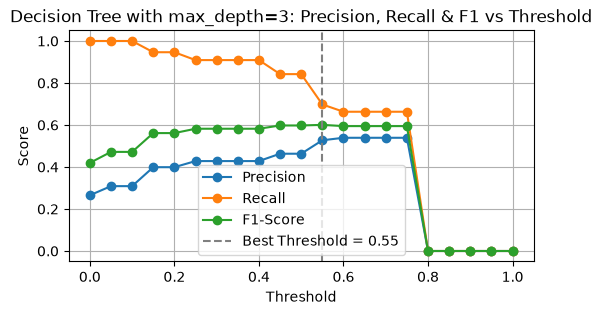

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA


In [49]:
DT1= DecisionTreeClassifier(class_weight='balanced',max_depth=3,random_state=1234)

result_df, Probability_Threshold, Ranking_Threshold= store_results("Decision Tree with max_depth=3",X_train, y_train,X_test, y_test, DT1, 5,"NA", "NA","Balanced")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison 

In [50]:
pd.options.display.max_columns=500
Model_Comparison

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA


# Visualize Decision Tree

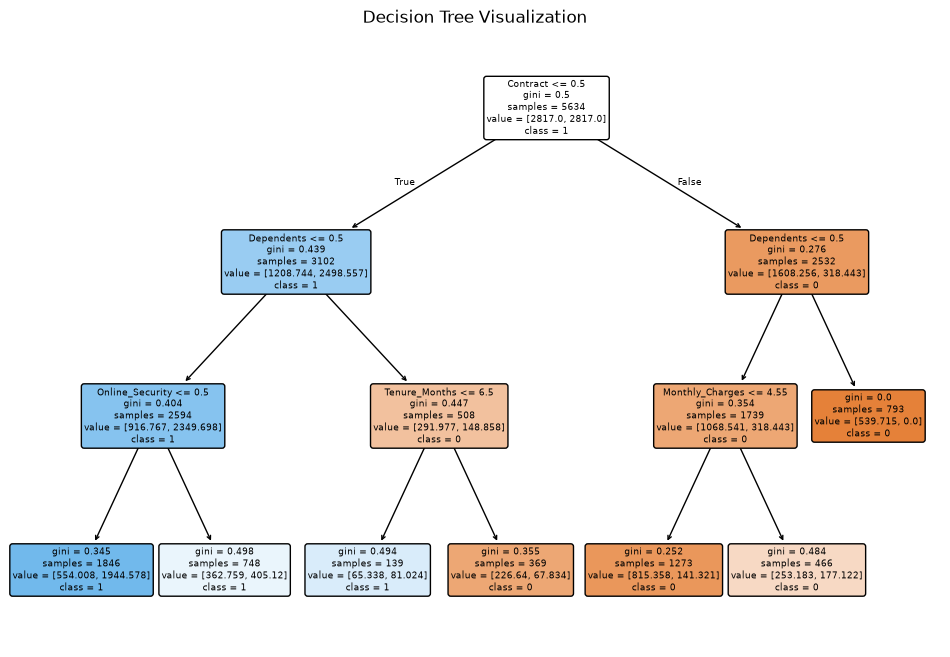

In [51]:
from sklearn.tree import plot_tree
feature_names1=list(X_train.columns)
plt.figure(figsize=(12, 8))
plot_tree(
    DT1,
    feature_names=feature_names1,
    class_names=['0', '1'],
    filled=True,
    rounded=True
)
plt.title("Decision Tree Visualization")
plt.show()

# Exporting Decision Tree Rules (Text Format)

In [52]:
from sklearn.tree import export_text

rules = export_text(DT1, feature_names=feature_names1)
print(rules)

|--- Contract <= 0.50
|   |--- Dependents <= 0.50
|   |   |--- Online_Security <= 0.50
|   |   |   |--- class: 1
|   |   |--- Online_Security >  0.50
|   |   |   |--- class: 1
|   |--- Dependents >  0.50
|   |   |--- Tenure_Months <= 6.50
|   |   |   |--- class: 1
|   |   |--- Tenure_Months >  6.50
|   |   |   |--- class: 0
|--- Contract >  0.50
|   |--- Dependents <= 0.50
|   |   |--- Monthly_Charges <= 4.55
|   |   |   |--- class: 0
|   |   |--- Monthly_Charges >  4.55
|   |   |   |--- class: 0
|   |--- Dependents >  0.50
|   |   |--- class: 0



In [53]:
from sklearn.tree import _tree
def get_rules(tree, feature_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    def recurse(node, depth):
        indent = "  " * depth
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            print(f"{indent}if {name} <= {threshold:.2f}:")
            recurse(tree_.children_left[node], depth + 1)
            print(f"{indent}else:  # if {name} > {threshold:.2f}")
            recurse(tree_.children_right[node], depth + 1)
        else:
            print(f"{indent}return {tree_.value[node]}")

    recurse(0, 0)

In [54]:
get_rules(DT1, feature_names1)

if Contract <= 0.50:
  if Dependents <= 0.50:
    if Online_Security <= 0.50:
      return [[0.22172853 0.77827147]]
    else:  # if Online_Security > 0.50
      return [[0.47241688 0.52758312]]
  else:  # if Dependents > 0.50
    if Tenure_Months <= 6.50:
      return [[0.44641163 0.55358837]]
    else:  # if Tenure_Months > 6.50
      return [[0.76964283 0.23035717]]
else:  # if Contract > 0.50
  if Dependents <= 0.50:
    if Monthly_Charges <= 4.55:
      return [[0.85227951 0.14772049]]
    else:  # if Monthly_Charges > 4.55
      return [[0.58837968 0.41162032]]
  else:  # if Dependents > 0.50
    return [[1. 0.]]


In [55]:
scores = []
for i in range(1,20):
    dt = DecisionTreeClassifier(max_depth=i,class_weight='balanced',random_state=1234)
    scores.append(cross_val_score(dt,X_train,y_train,cv=4).mean())

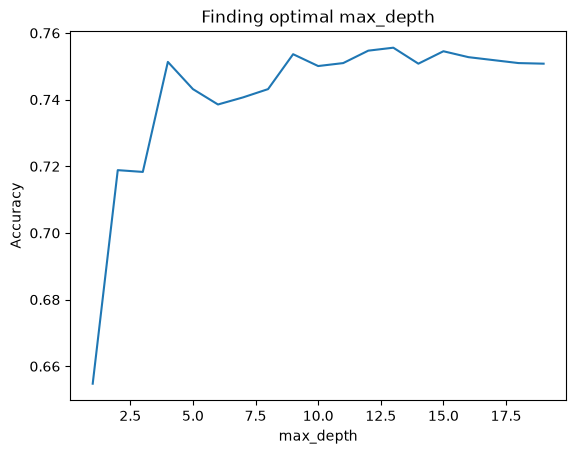

In [56]:
plt.plot(range(1,20),scores)
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Finding optimal max_depth")
plt.show()

In [57]:
scores = []
for i in range(1,20):
    dt = DecisionTreeClassifier(max_depth=i,class_weight='balanced',random_state=1234)
    s=cross_val_score(dt,X_train, y_train,cv=4,scoring='f1').mean()
    scores.append(s)
    print(i,s)

1 0.5770376472128937
2 0.6021036436376128
3 0.6070403912012307
4 0.6200333161517602
5 0.6213771768319096
6 0.6190541082480059
7 0.6157713229060104
8 0.6151022991464742
9 0.6206030030506089
10 0.6088493085505523
11 0.6042907164076519
12 0.6006713199898128
13 0.5976272958262667
14 0.5886912106941125
15 0.5888789282476611
16 0.5817413863363552
17 0.5773007614456434
18 0.5756508172159356
19 0.5720623136172018


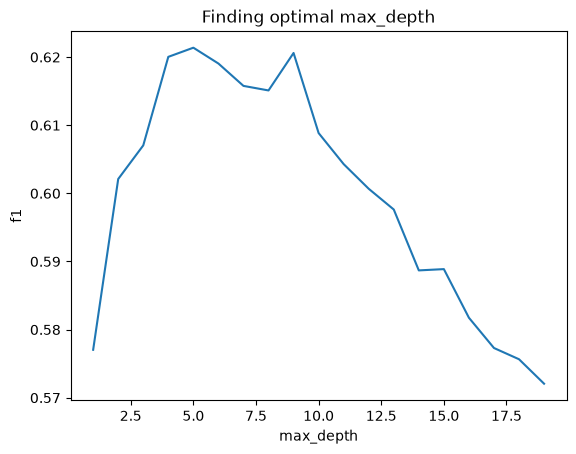

In [58]:
plt.plot(range(1,20),scores)
plt.xlabel("max_depth")
plt.ylabel("f1")
plt.title("Finding optimal max_depth")
plt.show()

# Hyperparameter Tuning with Grid Search and Cross Validation

In [59]:
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(3,9),
    'min_samples_split': [5, 10, 20],
    'min_samples_leaf': [2,3] #min_samples_leaf = the minimum number of samples (rows) that must be present in a leaf node(A leaf node is the final node that makes a prediction (e.g., “class 1”)) of a Decision Tree.
}

In [60]:
# Define scorers for class 1 (positive class)
f1_for_class1 = make_scorer(f1_score, pos_label=1)#f1_for_class1 at 50% threshold
recall_for_class1 = make_scorer(recall_score, pos_label=1)
precision_for_class1 = make_scorer(precision_score, pos_label=1)

In [61]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
DT =DecisionTreeClassifier(class_weight='balanced',random_state=1234)

In [62]:
grid = GridSearchCV(
    estimator=DT,
    param_grid=param_grid_dt,
    scoring={
        'PR_AUC': 'average_precision',
        'f1_class1': f1_for_class1,
        'recall_class1': recall_for_class1,
        'precision_class1': precision_for_class1
    },
    refit='PR_AUC',   # choose best model using PR-AUC
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best PR_AUC:", grid.best_score_)

Fitting 4 folds for each of 72 candidates, totalling 288 fits
Best Parameters: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 3, 'min_samples_split': 20}
Best PR_AUC: 0.6105520385930414


In [63]:
# All CV results
cvres = pd.DataFrame(grid.cv_results_)
cvres.head(2)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_criterion,param_max_depth,param_min_samples_leaf,param_min_samples_split,params,split0_test_PR_AUC,split1_test_PR_AUC,split2_test_PR_AUC,split3_test_PR_AUC,mean_test_PR_AUC,std_test_PR_AUC,rank_test_PR_AUC,split0_test_f1_class1,split1_test_f1_class1,split2_test_f1_class1,split3_test_f1_class1,mean_test_f1_class1,std_test_f1_class1,rank_test_f1_class1,split0_test_recall_class1,split1_test_recall_class1,split2_test_recall_class1,split3_test_recall_class1,mean_test_recall_class1,std_test_recall_class1,rank_test_recall_class1,split0_test_precision_class1,split1_test_precision_class1,split2_test_precision_class1,split3_test_precision_class1,mean_test_precision_class1,std_test_precision_class1,rank_test_precision_class1
0,0.506911,0.003894,0.140411,0.028797,gini,3,2,5,"{'criterion': 'gini', 'max_depth': 3, 'min_sam...",0.498421,0.505765,0.530318,0.508089,0.510649,0.011904,67,0.605187,0.603774,0.605778,0.605206,0.604986,0.000739,55,0.842246,0.855615,0.871314,0.745989,0.828791,0.0489,1,0.472264,0.466472,0.464286,0.509124,0.478036,0.018184,67
1,0.514209,0.009466,0.131772,0.024135,gini,3,2,10,"{'criterion': 'gini', 'max_depth': 3, 'min_sam...",0.498421,0.505765,0.530318,0.508089,0.510649,0.011904,67,0.605187,0.603774,0.605778,0.605206,0.604986,0.000739,55,0.842246,0.855615,0.871314,0.745989,0.828791,0.0489,1,0.472264,0.466472,0.464286,0.509124,0.478036,0.018184,67


In [64]:
# Columns for your three metrics
keep = [
    'param_criterion', 'param_max_depth', 'param_min_samples_leaf', 'param_min_samples_split','params',
  'mean_test_PR_AUC','std_test_PR_AUC','mean_test_f1_class1','rank_test_PR_AUC', 'std_test_f1_class1', 'rank_test_f1_class1',
    'mean_test_recall_class1', 'std_test_recall_class1',
    'mean_test_precision_class1', 'std_test_precision_class1'
]
pd.set_option('display.max_colwidth', None)
# View top rows sorted by the F1 rank
cvres[keep].sort_values('rank_test_PR_AUC').head(3)

,param_criterion,param_max_depth,param_min_samples_leaf,param_min_samples_split,params,mean_test_PR_AUC,std_test_PR_AUC,mean_test_f1_class1,rank_test_PR_AUC,std_test_f1_class1,rank_test_f1_class1,mean_test_recall_class1,std_test_recall_class1,mean_test_precision_class1,std_test_precision_class1
65,entropy,7,3,20,"{'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 3, 'min_samples_split': 20}",0.610552,0.015805,0.618291,1,0.004103,22,0.808720,0.04594,0.502008,0.016460
59,entropy,6,3,20,"{'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 3, 'min_samples_split': 20}",0.609889,0.013023,0.619719,2,0.006713,7,0.809375,0.02065,0.502339,0.008801
58,entropy,6,3,10,"{'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 3, 'min_samples_split': 10}",0.609502,0.013234,0.619874,3,0.006664,5,0.809375,0.02065,0.502536,0.008592


Confusion matrix (prob threshold = 0.50):
[[739 296]
 [ 75 299]]


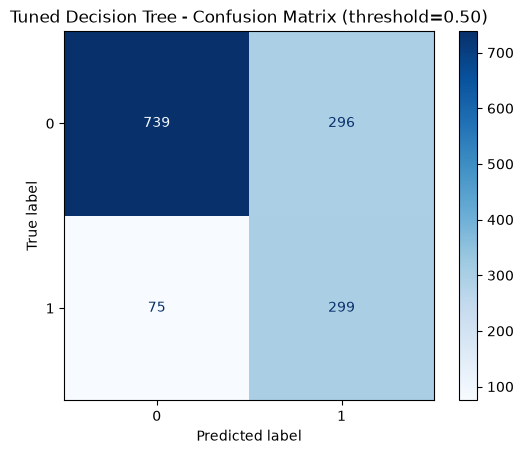

Train F1 Score (0.50): 0.6674
Test  F1 Score (0.50): 0.6171

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1035
           1       0.50      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



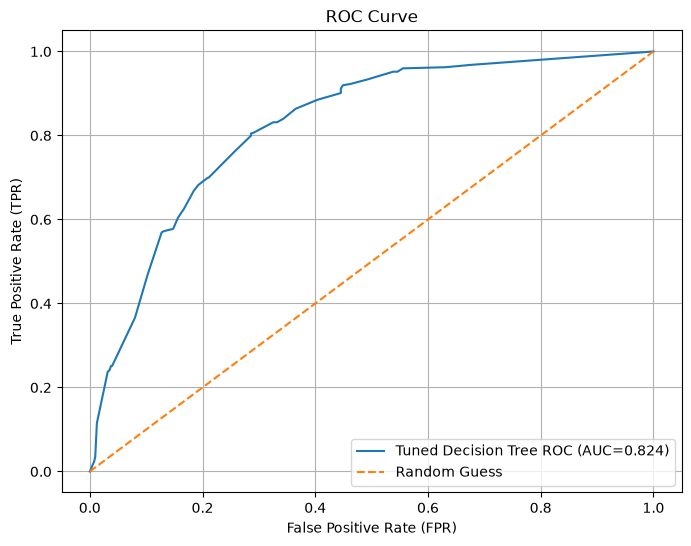

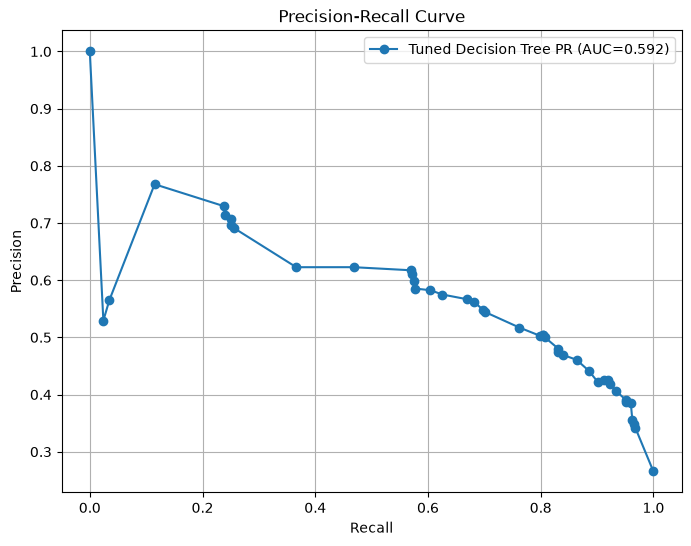

[Tuned Decision Tree] Best F1-score = 0.6176 at threshold = 0.45


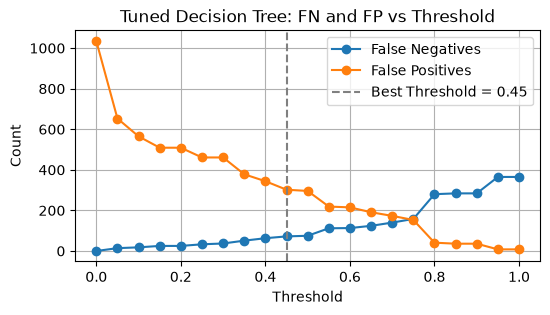

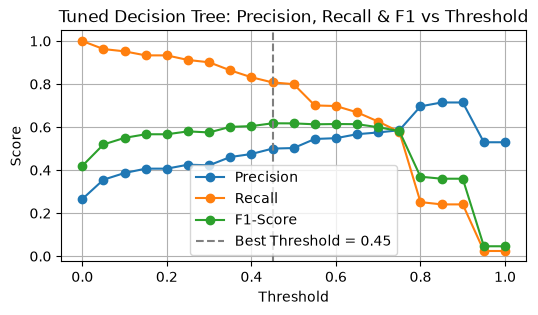

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA


In [65]:
DT2=grid.best_estimator_

result_df, Probability_Threshold, Ranking_Threshold= store_results("Tuned Decision Tree",X_train, y_train,X_test, y_test, DT2, 5,"NA", "NA","Balanced",fit=False)
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison 

In [66]:
Model_Comparison

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA


## Ensemble Learning

Confusion matrix (prob threshold = 0.50):
[[895 140]
 [167 207]]


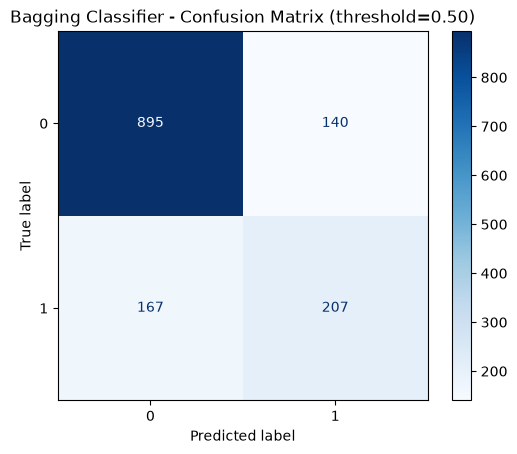

Train F1 Score (0.50): 0.9742
Test  F1 Score (0.50): 0.5742

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.84      0.86      0.85      1035
           1       0.60      0.55      0.57       374

    accuracy                           0.78      1409
   macro avg       0.72      0.71      0.71      1409
weighted avg       0.78      0.78      0.78      1409



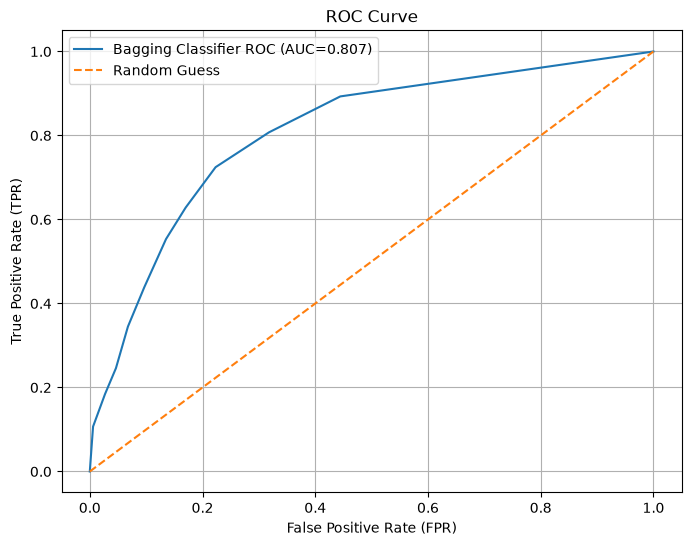

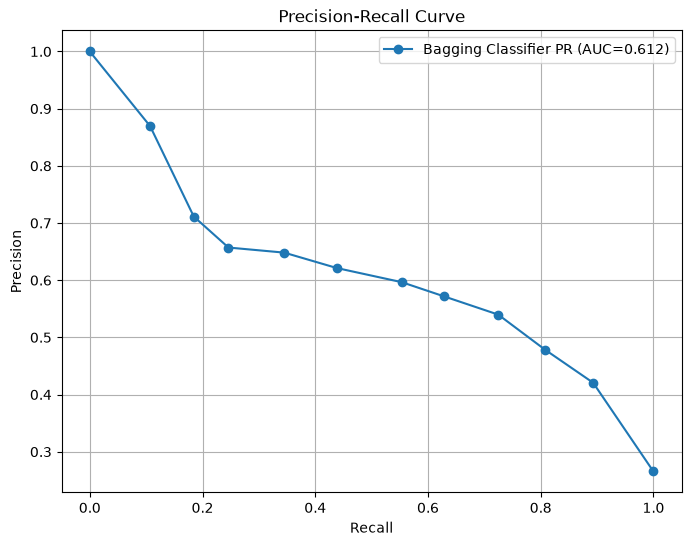

[Bagging Classifier] Best F1-score = 0.6187 at threshold = 0.25


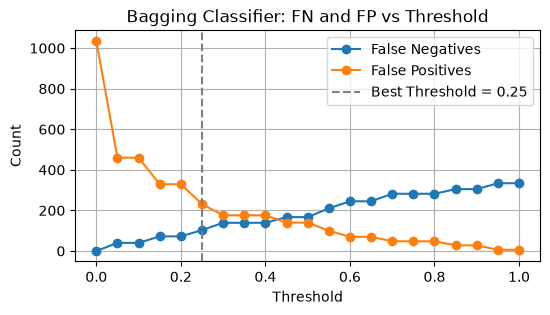

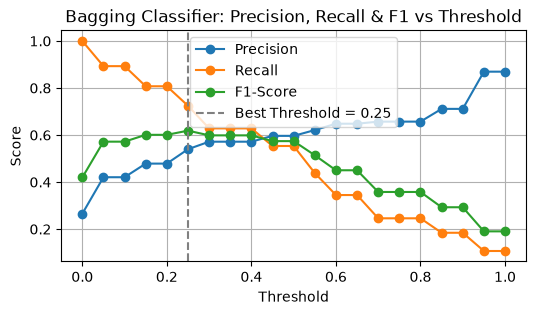

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA


In [67]:
model_bagging = BaggingClassifier(random_state = 1234)#default n_estimators=10
result_df, Probability_Threshold, Ranking_Threshold= store_results("Bagging Classifier",X_train, y_train,X_test, y_test, model_bagging, 5,"NA", "NA","NA")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison 

## Random Forest

Confusion matrix (prob threshold = 0.50):
[[946  89]
 [195 179]]


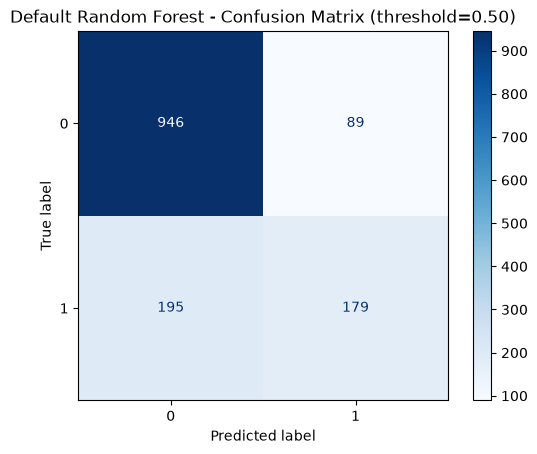

Train F1 Score (0.50): 1.0
Test  F1 Score (0.50): 0.5576

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1035
           1       0.67      0.48      0.56       374

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.71      1409
weighted avg       0.79      0.80      0.79      1409



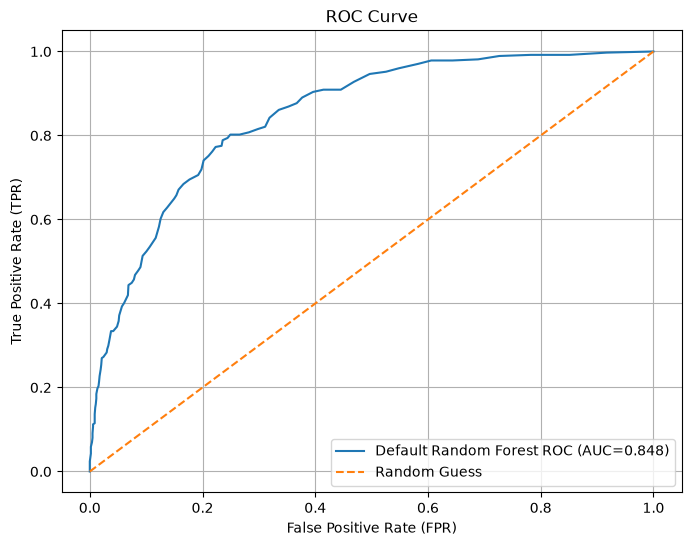

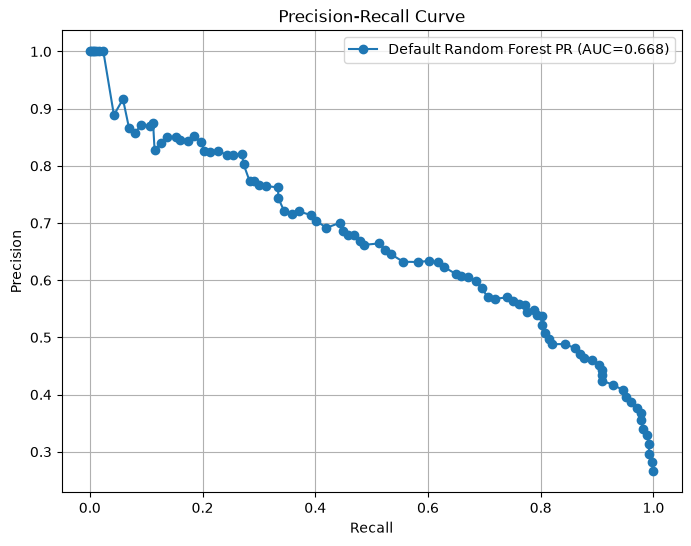

[Default Random Forest] Best F1-score = 0.6448 at threshold = 0.30


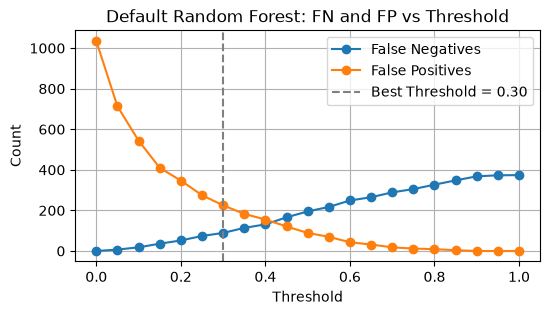

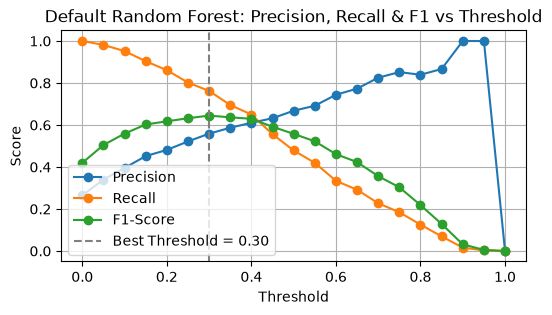

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [68]:
RF1=RandomForestClassifier(random_state=1234)
result_df, Probability_Threshold, Ranking_Threshold= store_results("Default Random Forest",X_train, y_train,X_test, y_test, RF1, 5,"NA", "NA","NA")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison 

## Tuning

In [69]:
param_grid={'n_estimators':[100,150,200],#range(10,110,10),
            'max_depth':[3,5,7],
            'min_samples_split':[3,5],
            'criterion':['gini','entropy']}

grid2 = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=1234),
    param_grid,
    cv=5,
    scoring='average_precision',  # PR_AUC (Precision-Recall)
    return_train_score=True  # Get training scores too
)

grid2.fit(X_train, y_train)

# Analyze results
results_df = pd.DataFrame(grid2.cv_results_)
results_df['gap'] = results_df['mean_train_score'] - results_df['mean_test_score']

# Sort by test PR_AUC (high) then by gap (small)
results_df_sorted = results_df.sort_values(
    ['mean_test_score', 'gap'], 
    ascending=[False, True]
)

# Display top candidates
print("Top models by PR_AUC with smallest gap:")
print(results_df_sorted[['params', 'mean_test_score', 'mean_train_score', 'gap']].head(10))

# Get the best model
best_idx = results_df_sorted.index[0]
best_params = results_df.loc[best_idx, 'params']

print(f"\n Best params: {best_params}")
print(f"  Test PR_AUC: {results_df.loc[best_idx, 'mean_test_score']:.4f}")
print(f"  Train PR_AUC: {results_df.loc[best_idx, 'mean_train_score']:.4f}")
print(f"  Gap: {results_df.loc[best_idx, 'gap']:.4f}")

# Use the best estimator
best_model = grid2.best_estimator_

Top models by PR_AUC with smallest gap:
                                                                                   params  \
33  {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 100}   
12     {'criterion': 'gini', 'max_depth': 7, 'min_samples_split': 3, 'n_estimators': 100}   
15     {'criterion': 'gini', 'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 100}   
30  {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 3, 'n_estimators': 100}   
34  {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 150}   
31  {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 3, 'n_estimators': 150}   
32  {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 3, 'n_estimators': 200}   
35  {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 200}   
13     {'criterion': 'gini', 'max_depth': 7, 'min_samples_split': 3, 'n_estimators': 150}   
16     {'criterion': 'gini', '

Confusion matrix (prob threshold = 0.50):
[[742 293]
 [ 75 299]]


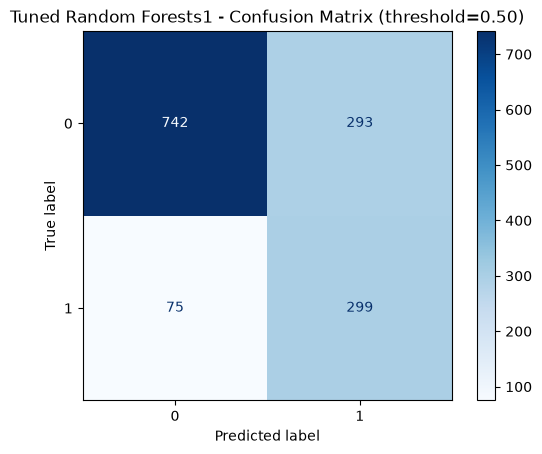

Train F1 Score (0.50): 0.6405
Test  F1 Score (0.50): 0.619

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1035
           1       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



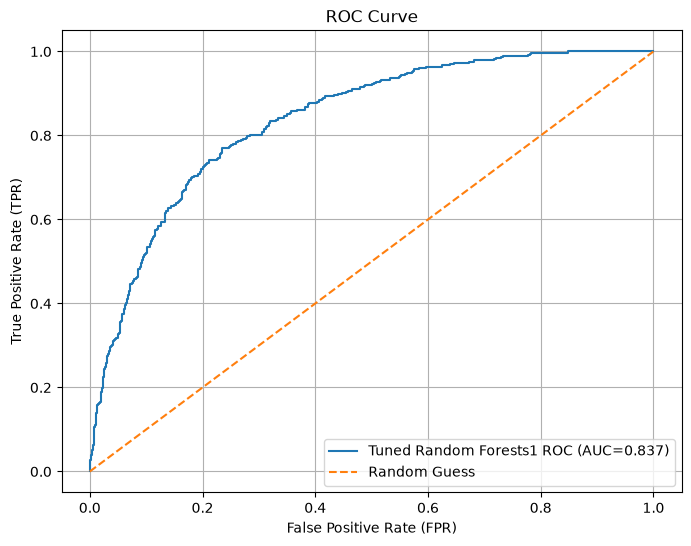

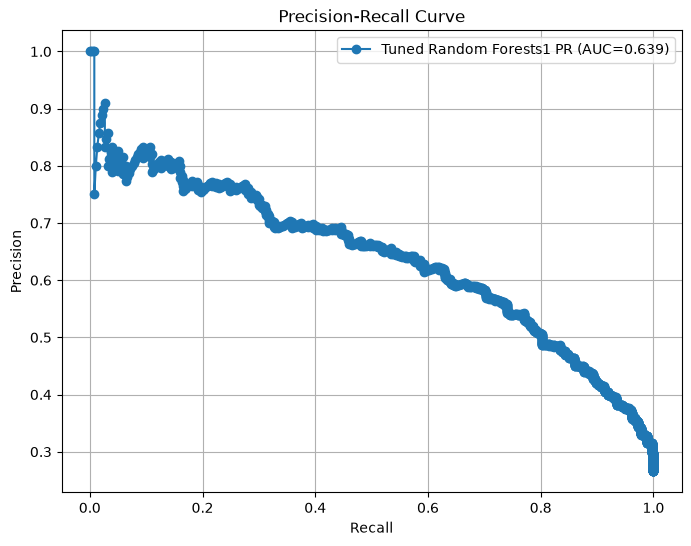

[Tuned Random Forests1] Best F1-score = 0.6336 at threshold = 0.55


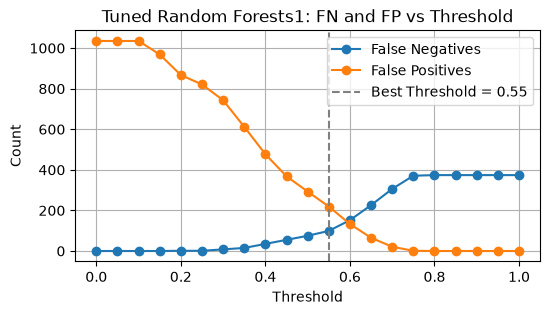

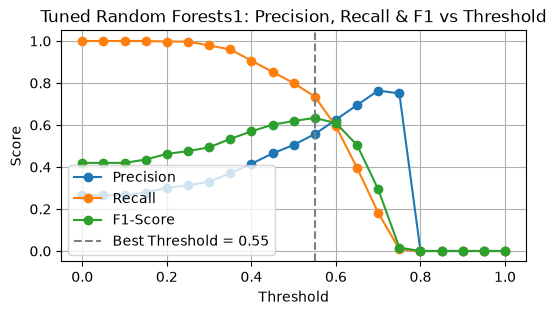

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [70]:
RF2=grid2.best_estimator_
result_df, Probability_Threshold, Ranking_Threshold= store_results("Tuned Random Forests1",X_train, y_train,X_test, y_test, RF2, 5,"N/A", "N/A","Balanced", fit=False)
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison

In [71]:
search_spaces={'n_estimators':[100,150,200],#range(10,110,10),
            'max_depth':[3,5,7],
            'min_samples_split':[3,5],
            'criterion':['gini','entropy']}
# Define model
rf = RandomForestClassifier(class_weight='balanced', random_state=1234)

# Bayesian Optimization
opt = BayesSearchCV(
    estimator=rf,
    search_spaces=search_spaces,
    scoring='average_precision',  # PR_AUC (Precision-Recall)
    cv=5,
    n_iter=30,             # number of iterations (trials)
    random_state=42,
    n_jobs=-1
)

# Fit optimizer
opt.fit(X_train, y_train)

# Best parameters
print("Best Parameters:", opt.best_params_)
print("Best PR_AUC Score:", opt.best_score_)

Best Parameters: OrderedDict({'criterion': 'gini', 'max_depth': 7, 'min_samples_split': 4, 'n_estimators': 100})
Best PR_AUC Score: 0.6500537958225644


Confusion matrix (prob threshold = 0.50):
[[739 296]
 [ 75 299]]


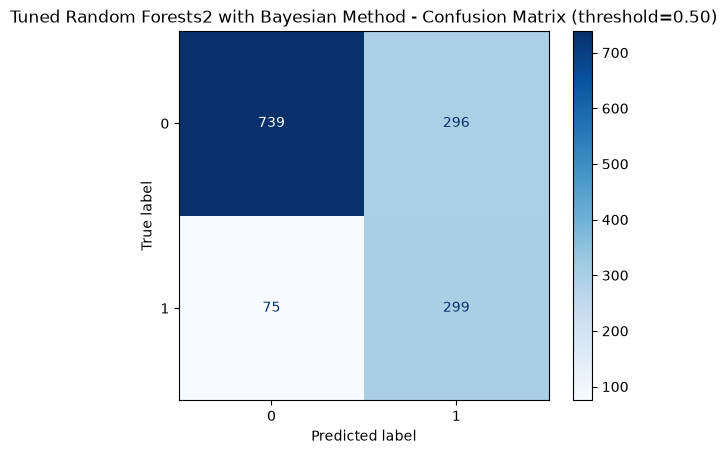

Train F1 Score (0.50): 0.6674
Test  F1 Score (0.50): 0.6171

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1035
           1       0.50      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



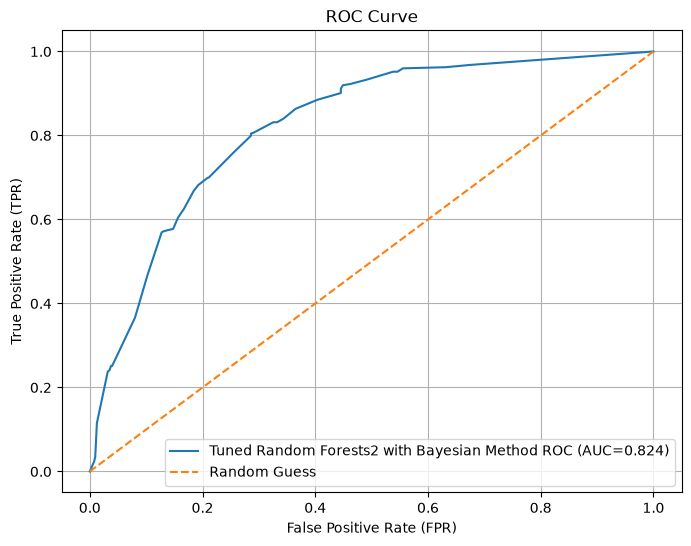

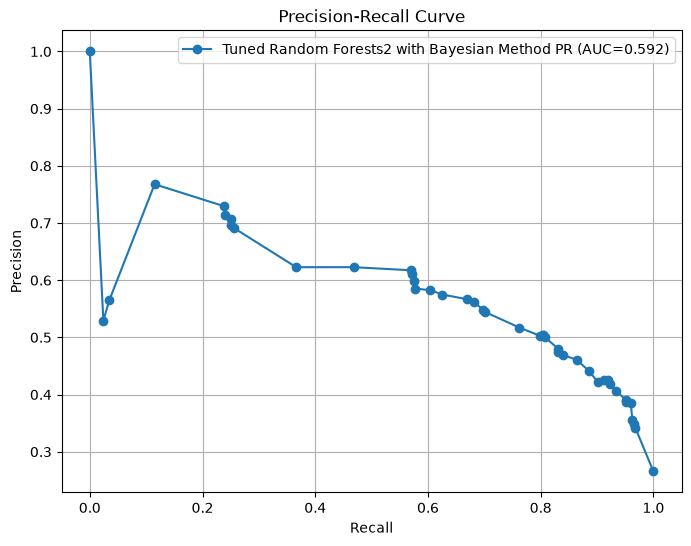

[Tuned Random Forests2 with Bayesian Method] Best F1-score = 0.6176 at threshold = 0.45


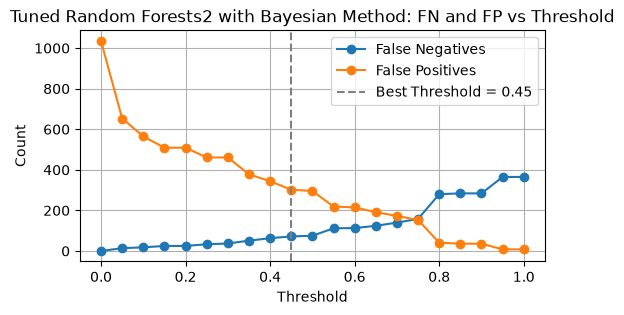

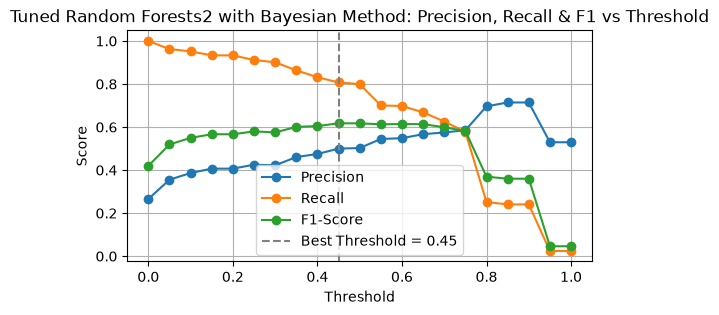

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [72]:
RF3=grid.best_estimator_
result_df, Probability_Threshold, Ranking_Threshold= store_results("Tuned Random Forests2 with Bayesian Method",X_train, y_train,X_test, y_test, RF3, 5,"N/A", "N/A","Balanced",fit=False)
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison

## Feature Importance

In [78]:
#Feature Importance
feature_importances = RF3.feature_importances_
features = X_train.columns
feature_importances_df = pd.DataFrame({'features': features, 'importance': feature_importances})
feature_importances_df.sort_values(by="importance", ascending=False).reset_index(drop=True)

,features,importance
0,Contract,0.453037
1,Dependents,0.147117
2,Monthly_Charges,0.075645
3,Tenure_Months,0.056242
4,Online_Security,0.053451
...,...,...
1146,City_Whitethorn,0.000000
1147,City_Whitmore,0.000000
1148,City_Whittier,0.000000
1149,City_Wildomar,0.000000


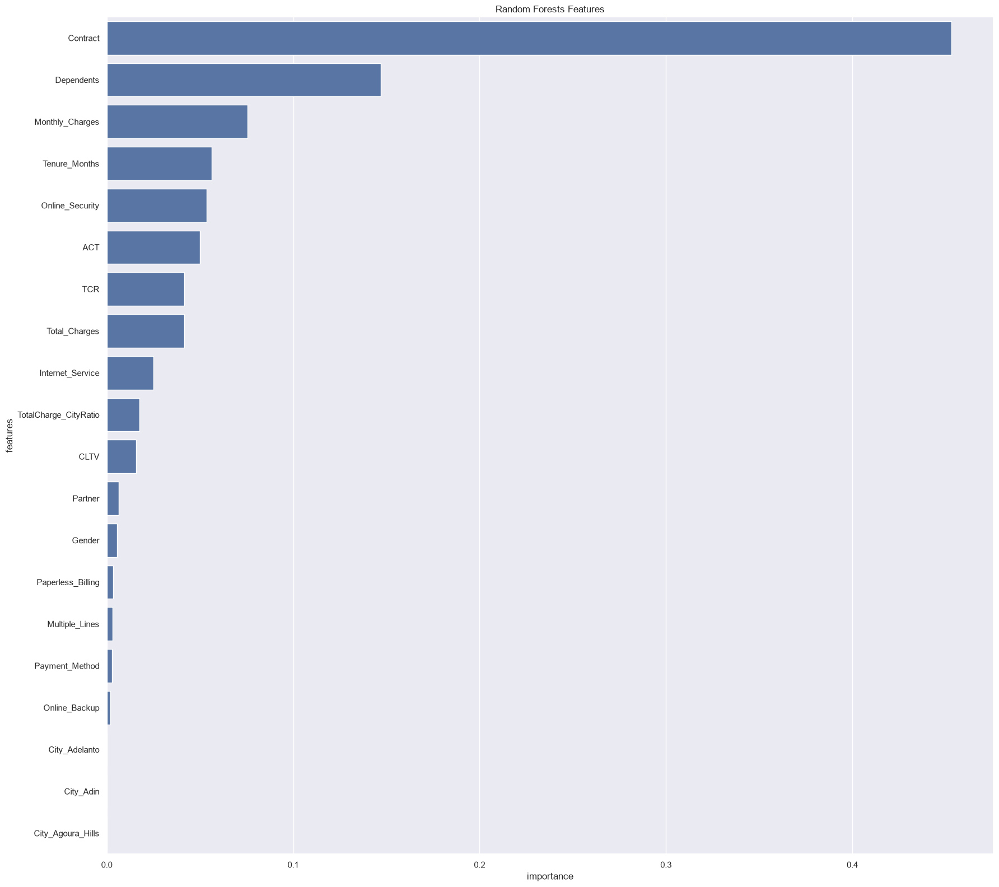

In [79]:
imp=feature_importances_df.sort_values(by="importance", ascending=False).head(20)
plt.figure(figsize=(18, 16))
sns.set(font_scale = 1)
sns.barplot(x="importance", y="features", data=imp.sort_values(by="importance", ascending=False))
plt.title('Random Forests Features')
plt.tight_layout()
plt.show()

## Customizing metric for Tuning

In [80]:
# ===== 1. BAYESIAN SEARCH =====
search_spaces = {
    'n_estimators': [100, 150, 200],
    'max_depth': [3, 5, 7],
    'min_samples_split': [3, 5],
    'criterion': ['gini', 'entropy']
}

rf = RandomForestClassifier(class_weight='balanced', random_state=1234)

opt = BayesSearchCV(
    estimator=rf,
    search_spaces=search_spaces,
    scoring='average_precision',
    cv=5,
    n_iter=30,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

opt.fit(X_train, y_train)

# ===== 2. PENALIZE BY GAP =====
results_df = pd.DataFrame(opt.cv_results_)
results_df['gap'] = results_df['mean_train_score'] - results_df['mean_test_score']

gap_penalty_weight = 0.5
results_df['penalized_score'] = results_df['mean_test_score'] - (gap_penalty_weight * results_df['gap'])

# ===== 3. GET BEST MODEL =====
best_idx = results_df['penalized_score'].idxmax()
best_params = results_df.loc[best_idx, 'params']

print("="*70)
print("BEST MODEL")
print("="*70)
print(f"Parameters: {best_params}")
print(f"CV Test PR_AUC:  {results_df.loc[best_idx, 'mean_test_score']:.4f}")
print(f"CV Train PR_AUC: {results_df.loc[best_idx, 'mean_train_score']:.4f}")
print(f"Gap:             {results_df.loc[best_idx, 'gap']:.4f}")
print(f"Penalized Score: {results_df.loc[best_idx, 'penalized_score']:.4f}")
print("="*70)

# ===== 4. TRAIN FINAL MODEL WITH BEST PARAMS =====
best_model = RandomForestClassifier(
    **best_params,
    class_weight='balanced',
    random_state=1234
)
best_model.fit(X_train, y_train)
'''
# ===== 5. EVALUATE ON TEST SET =====
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = best_model.predict(X_test)

test_pr_auc = average_precision_score(y_test, y_pred_proba)

print(f"\nTest Set Performance:")
print(f"PR_AUC: {test_pr_auc:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred))
print(f"\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# ===== 6. USE BEST MODEL FOR PREDICTIONS =====
# On new data
new_predictions = best_model.predict(X_new)
new_probabilities = best_model.predict_proba(X_new)[:, 1]

print(f"\nSample predictions: {new_predictions[:5]}")
print(f"Sample probabilities: {new_probabilities[:5]}")

# ===== 7. SAVE BEST MODEL (optional) =====
import joblib
joblib.dump(best_model, 'best_rf_model.pkl')
print("\nModel saved as 'best_rf_model.pkl'")
'''
# Later: Load the model
# best_model = joblib.load('best_rf_model.pkl')

BEST MODEL
Parameters: OrderedDict({'criterion': 'gini', 'max_depth': 7, 'min_samples_split': 4, 'n_estimators': 100})
CV Test PR_AUC:  0.6501
CV Train PR_AUC: 0.6910
Gap:             0.0409
Penalized Score: 0.6296


'\n# ===== 5. EVALUATE ON TEST SET =====\ny_pred_proba = best_model.predict_proba(X_test)[:, 1]\ny_pred = best_model.predict(X_test)\n\ntest_pr_auc = average_precision_score(y_test, y_pred_proba)\n\nprint(f"\nTest Set Performance:")\nprint(f"PR_AUC: {test_pr_auc:.4f}")\nprint(f"\nClassification Report:")\nprint(classification_report(y_test, y_pred))\nprint(f"\nConfusion Matrix:")\nprint(confusion_matrix(y_test, y_pred))\n\n# ===== 6. USE BEST MODEL FOR PREDICTIONS =====\n# On new data\nnew_predictions = best_model.predict(X_new)\nnew_probabilities = best_model.predict_proba(X_new)[:, 1]\n\nprint(f"\nSample predictions: {new_predictions[:5]}")\nprint(f"Sample probabilities: {new_probabilities[:5]}")\n\n# ===== 7. SAVE BEST MODEL (optional) =====\nimport joblib\njoblib.dump(best_model, \'best_rf_model.pkl\')\nprint("\nModel saved as \'best_rf_model.pkl\'")\n'

Confusion matrix (prob threshold = 0.50):
[[740 295]
 [ 78 296]]


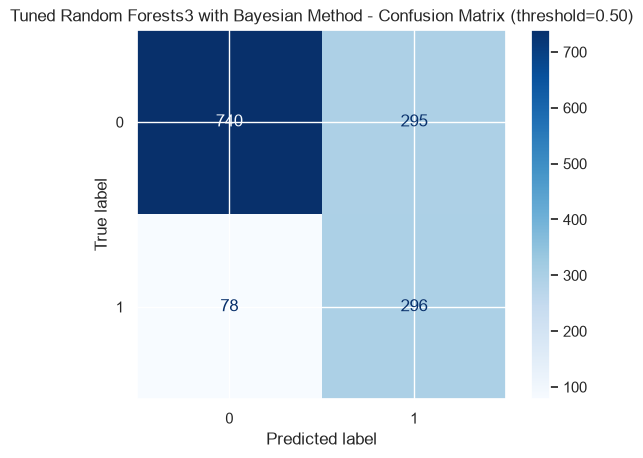

Train F1 Score (0.50): 0.64
Test  F1 Score (0.50): 0.6135

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1035
           1       0.50      0.79      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



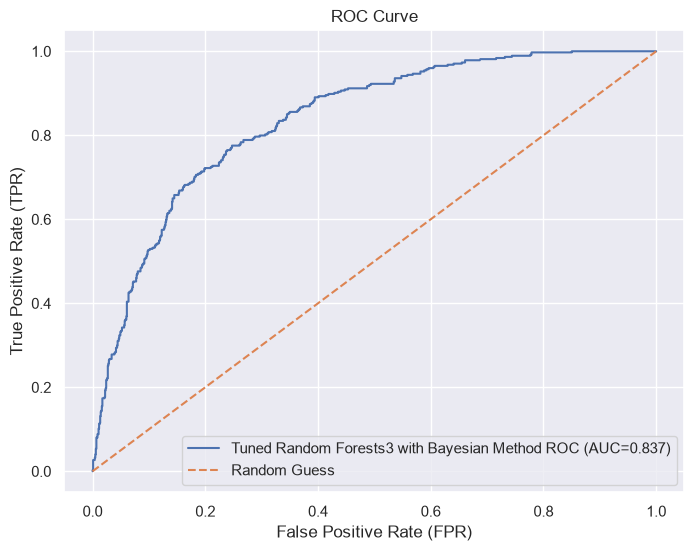

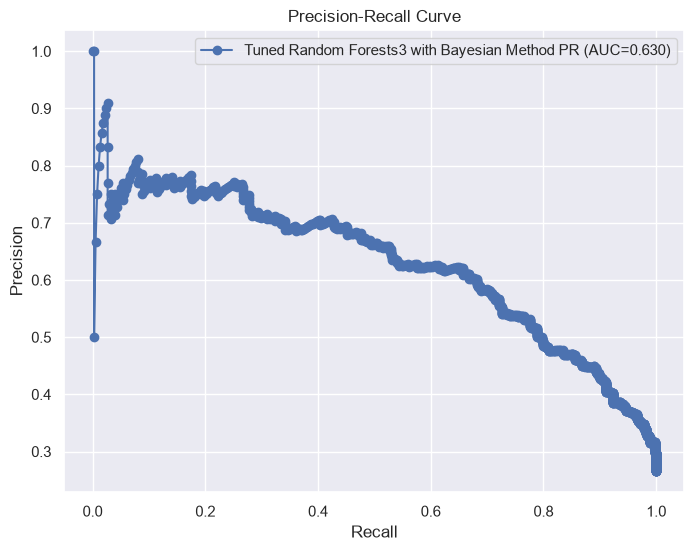

[Tuned Random Forests3 with Bayesian Method] Best F1-score = 0.6231 at threshold = 0.55


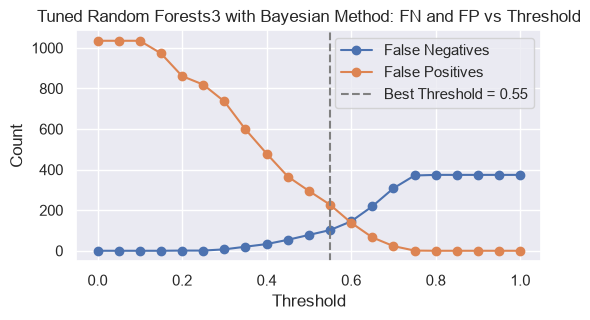

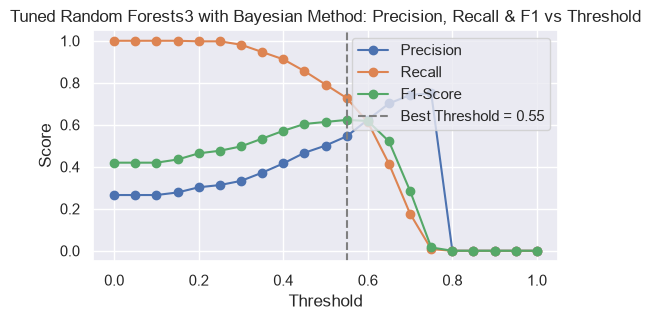

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [81]:
RF4=best_model
result_df, Probability_Threshold, Ranking_Threshold= store_results("Tuned Random Forests3 with Bayesian Method",X_train, y_train,X_test, y_test, RF4, 5,"N/A", "N/A","Balanced",fit=False)
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison

## Extra trees

In [82]:
# ===== 1. BAYESIAN SEARCH WITH EXTRA TREES =====
search_spaces = {
    'n_estimators': [100, 150, 200],
    'max_depth': [3, 5, 7],
    'min_samples_split': [3, 5],
    'criterion': ['gini', 'entropy']
}

et = ExtraTreesClassifier(class_weight='balanced', random_state=1234)

opt = BayesSearchCV(
    estimator=et,
    search_spaces=search_spaces,
    scoring='average_precision',  # PR_AUC
    cv=5,
    n_iter=30,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

opt.fit(X_train, y_train)

# ===== 2. PENALIZE BY GAP =====
results_df = pd.DataFrame(opt.cv_results_)
results_df['gap'] = results_df['mean_train_score'] - results_df['mean_test_score']

gap_penalty_weight = 0.5
results_df['penalized_score'] = results_df['mean_test_score'] - (gap_penalty_weight * results_df['gap'])

# ===== 3. GET BEST MODEL =====
best_idx = results_df['penalized_score'].idxmax()
best_params = results_df.loc[best_idx, 'params']

print("="*70)
print("BEST EXTRA TREES MODEL")
print("="*70)
print(f"Parameters: {best_params}")
print(f"CV Test PR_AUC:  {results_df.loc[best_idx, 'mean_test_score']:.4f}")
print(f"CV Train PR_AUC: {results_df.loc[best_idx, 'mean_train_score']:.4f}")
print(f"Gap:             {results_df.loc[best_idx, 'gap']:.4f}")
print(f"Penalized Score: {results_df.loc[best_idx, 'penalized_score']:.4f}")
print("="*70)

# ===== 4. TRAIN FINAL MODEL WITH BEST PARAMS =====
best_model_et = ExtraTreesClassifier(
    **best_params,
    class_weight='balanced',
    random_state=1234
)
best_model_et.fit(X_train, y_train)

BEST EXTRA TREES MODEL
Parameters: OrderedDict({'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 4, 'n_estimators': 200})
CV Test PR_AUC:  0.6466
CV Train PR_AUC: 0.6890
Gap:             0.0424
Penalized Score: 0.6255


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",1234
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If 

## AdaBoost (Adaptive Boosting)

In [83]:
X_train=X_train_ada.copy()
y_train =y_train_ada.copy()
X_test=X_test_ada.copy()
y_test = y_test_ada.copy()

Confusion matrix (prob threshold = 0.50):
[[929 106]
 [168 206]]


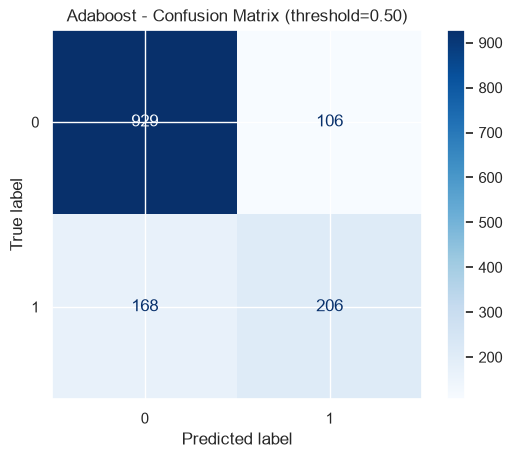

Train F1 Score (0.50): 0.6218
Test  F1 Score (0.50): 0.6006

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.55      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409



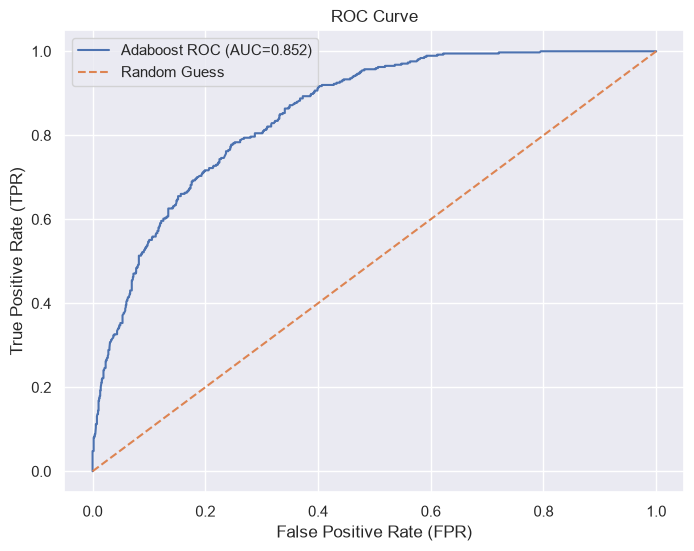

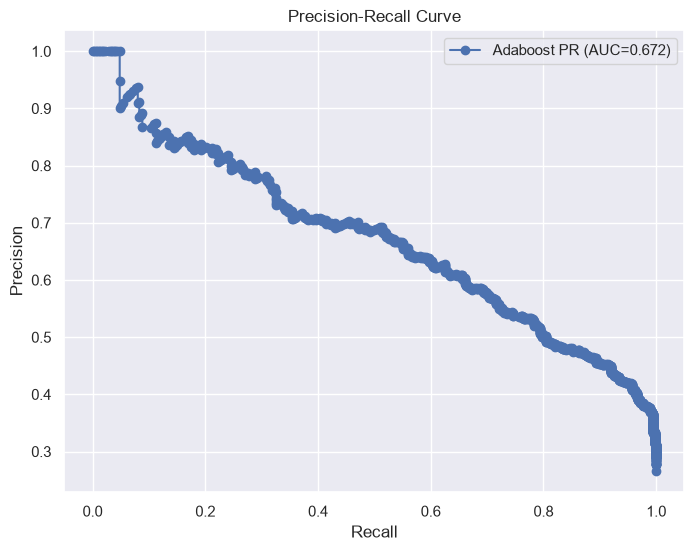

[Adaboost] Best F1-score = 0.6322 at threshold = 0.45


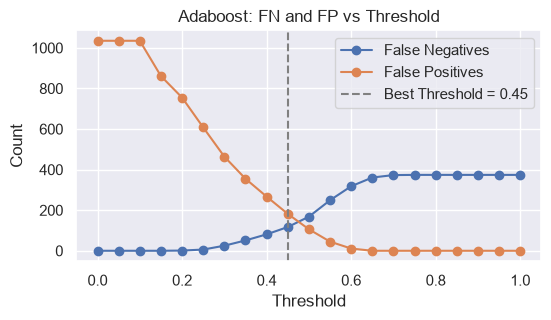

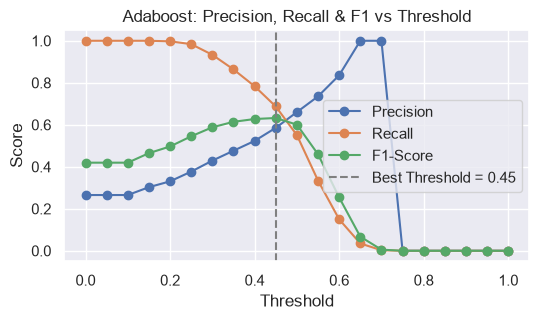

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [84]:
base_est = DecisionTreeClassifier (max_depth =2)
ADA1 = AdaBoostClassifier(base_est, n_estimators=500, random_state=1234, learning_rate=.05)
result_df, Probability_Threshold, Ranking_Threshold= store_results("Adaboost",X_train, y_train,X_test, y_test, ADA1, 5,"N/A", "N/A","N/A")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison

## Tuning

In [85]:
base_est = DecisionTreeClassifier (class_weight='balanced',max_depth=2)
ada_boost1 = AdaBoostClassifier(base_est, random_state=1234, learning_rate=.05)
#param_grid = {"base_estimator__max_depth" : [2, 5],"n_estimators": [200, 400, 600]}
param_grid = {"n_estimators": [200, 400, 600]}
# Bayesian Optimization
opt = BayesSearchCV(
    estimator=ada_boost1,
    search_spaces=param_grid,
    scoring='average_precision',  # PR_AUC
    cv=5,
    n_iter=30,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

opt.fit(X_train, y_train)

# ===== 2. PENALIZE BY GAP =====
results_df = pd.DataFrame(opt.cv_results_)
results_df['gap'] = results_df['mean_train_score'] - results_df['mean_test_score']

gap_penalty_weight = 0.5
results_df['penalized_score'] = results_df['mean_test_score'] - (gap_penalty_weight * results_df['gap'])

# ===== 3. GET BEST MODEL =====
best_idx = results_df['penalized_score'].idxmax()
best_params = results_df.loc[best_idx, 'params']

print("="*70)
print("BEST EXTRA TREES MODEL")
print("="*70)
print(f"Parameters: {best_params}")
print(f"CV Test PR_AUC:  {results_df.loc[best_idx, 'mean_test_score']:.4f}")
print(f"CV Train PR_AUC: {results_df.loc[best_idx, 'mean_train_score']:.4f}")
print(f"Gap:             {results_df.loc[best_idx, 'gap']:.4f}")
print(f"Penalized Score: {results_df.loc[best_idx, 'penalized_score']:.4f}")
print("="*70)

# ===== 4. TRAIN FINAL MODEL WITH BEST PARAMS =====
best_model_ada = ExtraTreesClassifier(
    **best_params,
    class_weight='balanced',
    random_state=1234
)
best_model_ada.fit(X_train, y_train)

BEST EXTRA TREES MODEL
Parameters: OrderedDict({'n_estimators': 400})
CV Test PR_AUC:  0.6178
CV Train PR_AUC: 0.6291
Gap:             0.0113
Penalized Score: 0.6122


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",400
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",1234
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If 

## XGBOOST

In [86]:
X_train=X_train_gb.copy()
y_train =y_train_gb.copy()
X_test=X_test_gb.copy()
y_test = y_test_gb.copy()

In [87]:
X_train.dtypes

Gender                 int64
Senior_Citizen         int64
Partner                int64
Dependents             int64
Tenure_Months          int64
                      ...   
City_Yreka           float64
City_Yuba_City       float64
City_Yucaipa         float64
City_Yucca_Valley    float64
City_Zenia           float64
Length: 1151, dtype: object

Confusion matrix (prob threshold = 0.50):
[[916 119]
 [177 197]]


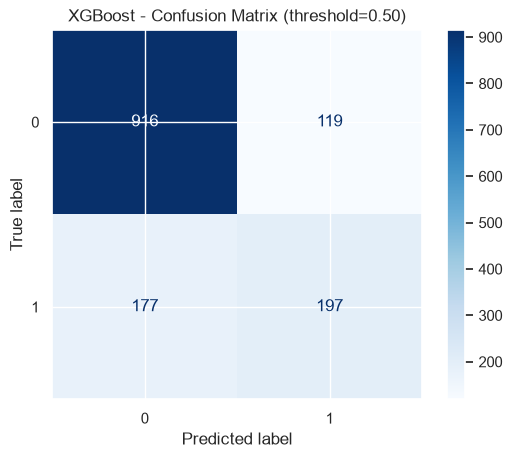

Train F1 Score (0.50): 0.892
Test  F1 Score (0.50): 0.571

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.62      0.53      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.78      0.79      0.78      1409



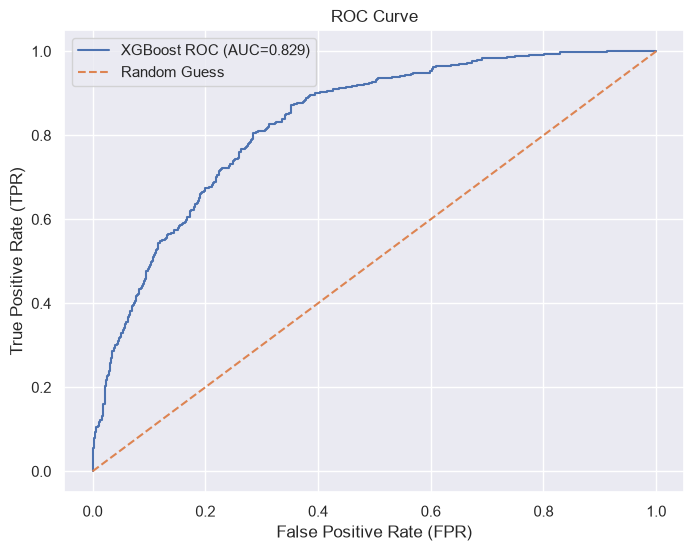

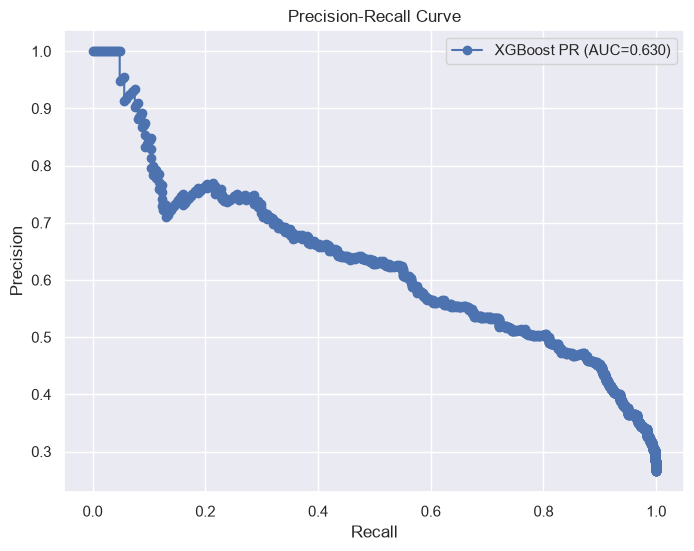

[XGBoost] Best F1-score = 0.6131 at threshold = 0.20


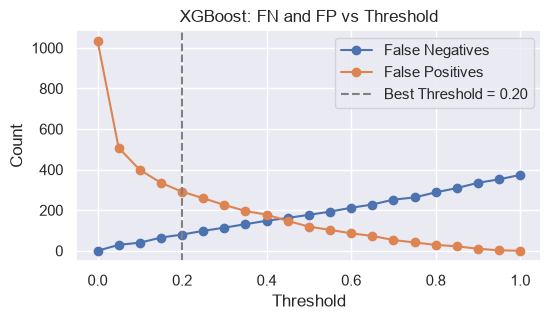

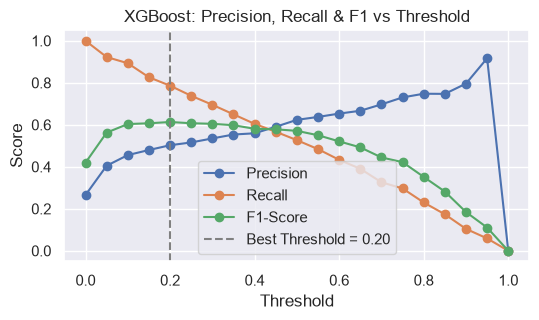

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [88]:
XGB1=XGBClassifier(class_weight='balanced',max_depth= 3,n_estimators= 500)#in newer version you have scale_pos_weight instead of class_weight
#check https://xgboost.readthedocs.io/en/stable/parameter.html
result_df, Probability_Threshold, Ranking_Threshold= store_results("XGBoost",X_train, y_train,X_test, y_test, XGB1, 5,"L2", 1,"Balanced")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison

## Tuning

In [89]:
xgb=XGBClassifier(random_state=1234)

#param_grid={'loss':['ls', 'lad', 'huber'],'n_estimators':range(5,50,10),'max_depth':[3,4,5,6],
#            'min_samples_leaf':range(2,10,3),'max_features':['auto', 'sqrt', 'log2', None]}
param_grid={'n_estimators':[100,300,500],'max_depth':[3,4,5]
           }
opt = BayesSearchCV(
    estimator=xgb,
    search_spaces=param_grid,
    scoring='average_precision',
    cv=5,
    n_iter=30,
    random_state=1234,
    n_jobs=-1,
    return_train_score=True
)

opt.fit(X_train, y_train)

# ===== 2. PENALIZE BY GAP =====
results_df = pd.DataFrame(opt.cv_results_)
results_df['gap'] = results_df['mean_train_score'] - results_df['mean_test_score']

gap_penalty_weight = 0.5
results_df['penalized_score'] = results_df['mean_test_score'] - (gap_penalty_weight * results_df['gap'])

# ===== 3. GET BEST MODEL =====
best_idx = results_df['penalized_score'].idxmax()
best_params = results_df.loc[best_idx, 'params']

print("="*70)
print("BEST MODEL")
print("="*70)
print(f"Parameters: {best_params}")
print(f"CV Test PR_AUC:  {results_df.loc[best_idx, 'mean_test_score']:.4f}")
print(f"CV Train PR_AUC: {results_df.loc[best_idx, 'mean_train_score']:.4f}")
print(f"Gap:             {results_df.loc[best_idx, 'gap']:.4f}")
print(f"Penalized Score: {results_df.loc[best_idx, 'penalized_score']:.4f}")
print("="*70)

# ===== 4. TRAIN FINAL MODEL WITH BEST PARAMS =====
best_model = XGBClassifier(
    **best_params,
    class_weight='balanced',
    random_state=1234
)
best_model.fit(X_train, y_train)

BEST MODEL
Parameters: OrderedDict({'max_depth': 3, 'n_estimators': 100})
CV Test PR_AUC:  0.6593
CV Train PR_AUC: 0.8210
Gap:             0.1617
Penalized Score: 0.5785


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


Confusion matrix (prob threshold = 0.50):
[[920 115]
 [171 203]]


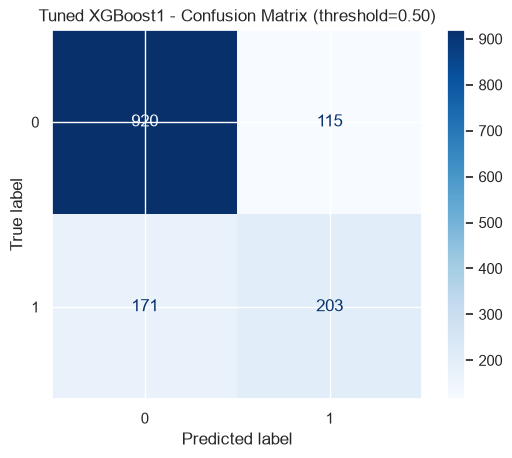

Train F1 Score (0.50): 0.7008
Test  F1 Score (0.50): 0.5867

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1035
           1       0.64      0.54      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



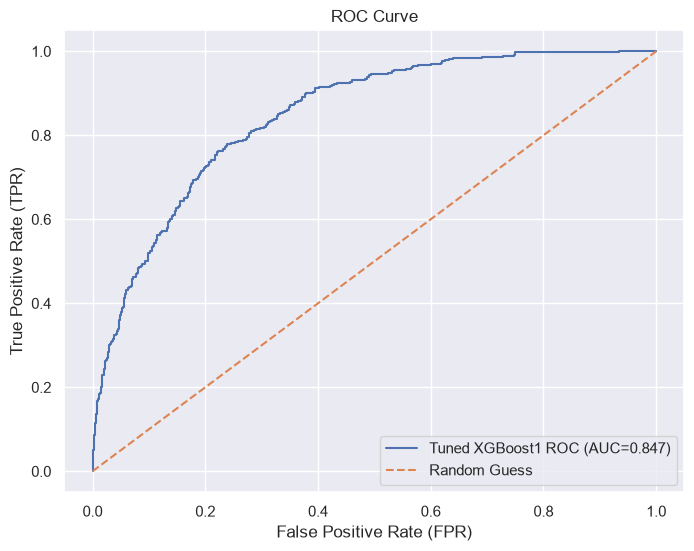

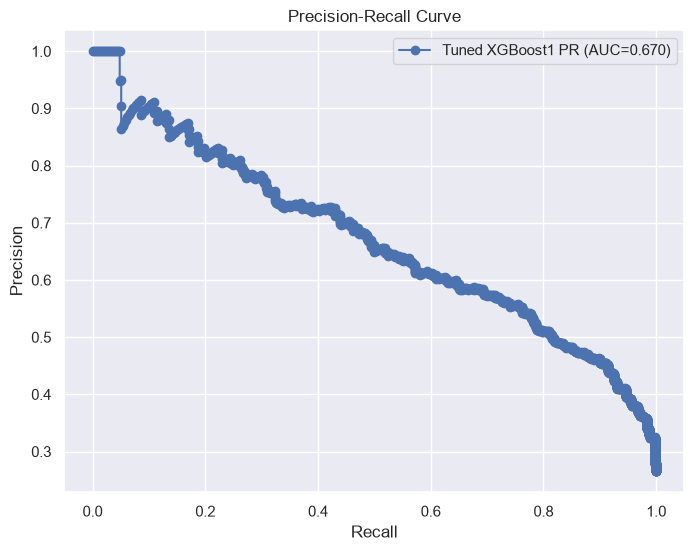

[Tuned XGBoost1] Best F1-score = 0.6390 at threshold = 0.30


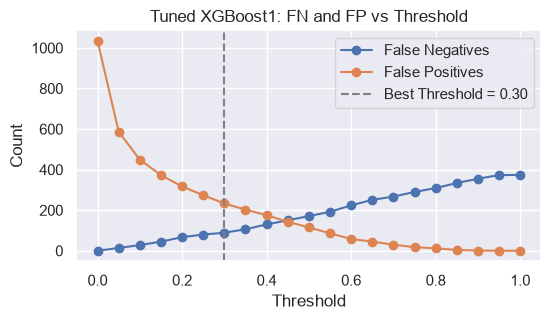

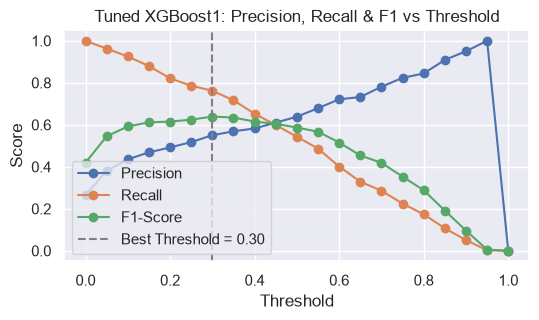

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [90]:
XGB2=best_model 
result_df, Probability_Threshold, Ranking_Threshold= store_results("Tuned XGBoost1",X_train, y_train,X_test, y_test, XGB2, 5,"L2", 1,"Balanced",fit=False)
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison

## Feature Importance

In [91]:

feature_importances = XGB2.feature_importances_
features = X_train.columns
feature_importances_df = pd.DataFrame({'features': features, 'importance': feature_importances})
feature_importances_df.sort_values(by="importance", ascending=False).reset_index(drop=True)

,features,importance
0,Contract,0.347129
1,Dependents,0.084074
2,Tech_Support,0.070260
3,Online_Security,0.069184
4,Tenure_Months,0.044222
...,...,...
1146,City_Whitethorn,0.000000
1147,City_Whitmore,0.000000
1148,City_Witter_Springs,0.000000
1149,City_Wildomar,0.000000


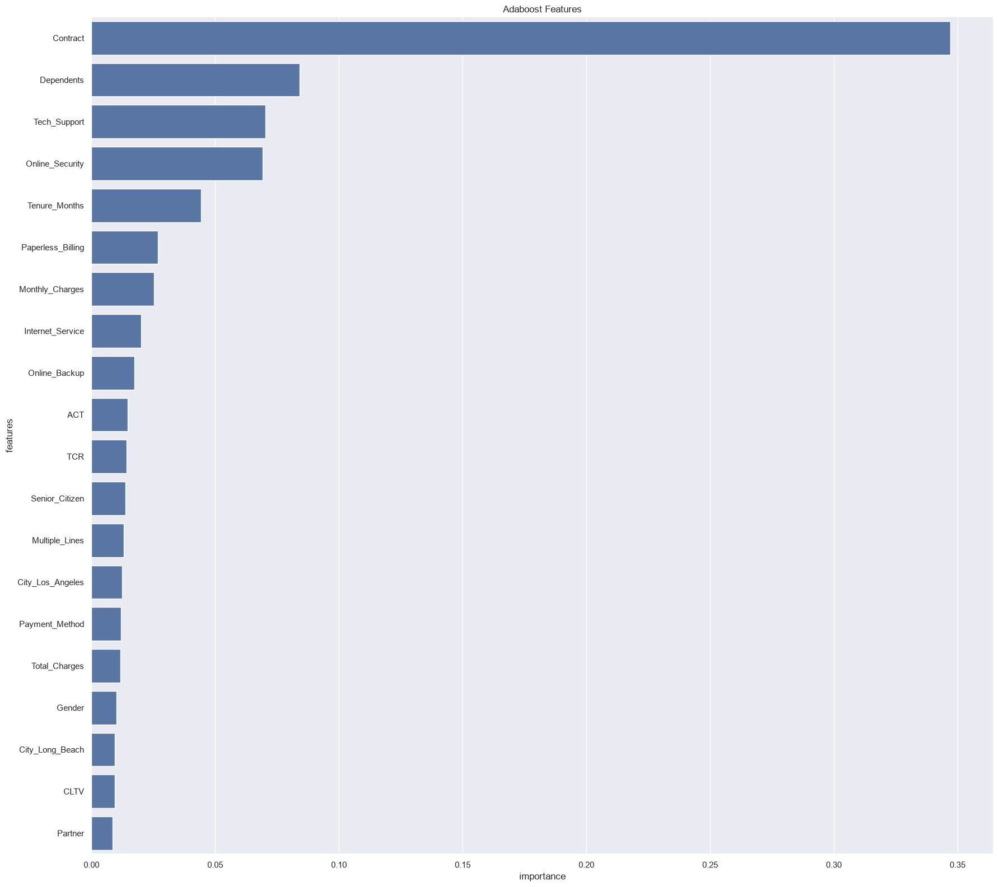

In [92]:

imp=feature_importances_df.sort_values(by="importance", ascending=False).head(20)
plt.figure(figsize=(18, 16))
sns.set(font_scale = 1)
sns.barplot(x="importance", y="features", data=imp.sort_values(by="importance", ascending=False))
plt.title('Adaboost Features')
plt.tight_layout()
plt.show()

In [93]:
Model_Comparison.to_csv(r"C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects\\Model_Comparison2_Classification.csv")
Probability_Threshold_Comparison.to_csv(r"C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects\Probability_Threshold_Comparison_Classification.csv")
Ranking_Threshold_Comparison.to_csv(r"C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects\Ranking_Threshold_Comparison_Classification.csv")

## LightGBM

Confusion matrix (prob threshold = 0.50):
[[812 223]
 [ 95 279]]


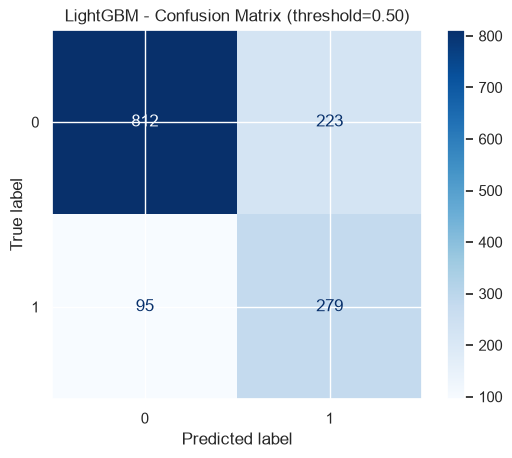

Train F1 Score (0.50): 0.834
Test  F1 Score (0.50): 0.637

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.90      0.78      0.84      1035
           1       0.56      0.75      0.64       374

    accuracy                           0.77      1409
   macro avg       0.73      0.77      0.74      1409
weighted avg       0.81      0.77      0.78      1409



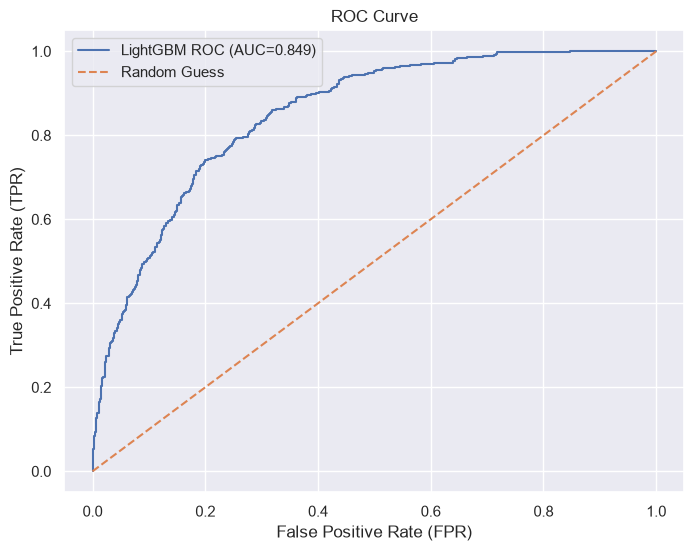

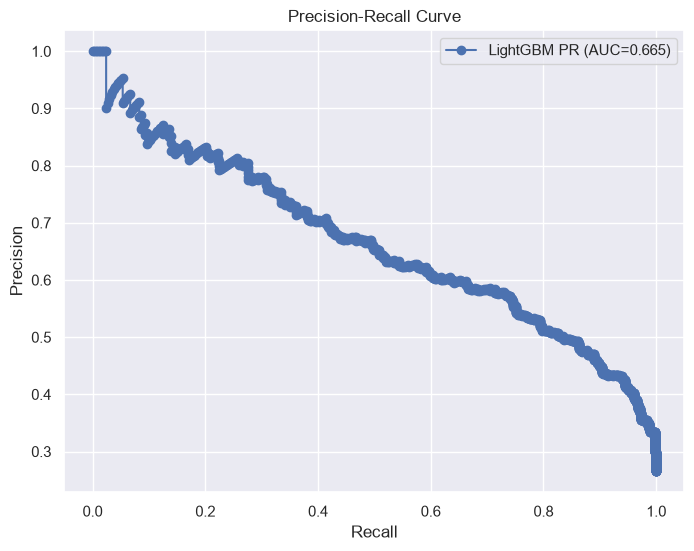

[LightGBM] Best F1-score = 0.6395 at threshold = 0.55


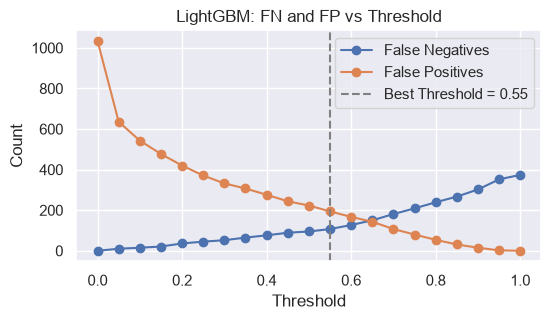

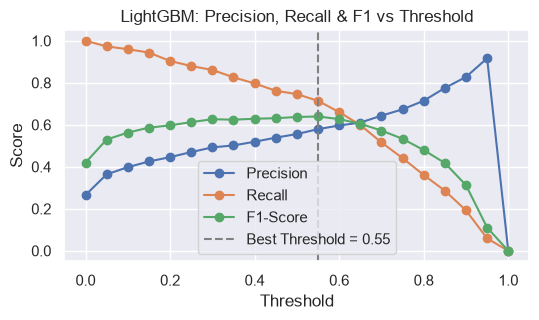

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [94]:
lgb1 = LGBMClassifier(
    is_unbalance=True,  # Automatically handles imbalance
    #in newer versions we can use scale_pos_weight
    #https://lightgbm.readthedocs.io/en/latest/Parameters.html#core-parameters
    n_estimators=100,      # Number of trees
    max_depth=10,          # Max tree depth
    learning_rate=0.1,     # How fast it learns
    random_state=42
)
result_df, Probability_Threshold, Ranking_Threshold= store_results("LightGBM",X_train, y_train,X_test, y_test, lgb1, 5,"L2", 1,"Automatic")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison

Confusion matrix (prob threshold = 0.50):
[[804 231]
 [ 96 278]]


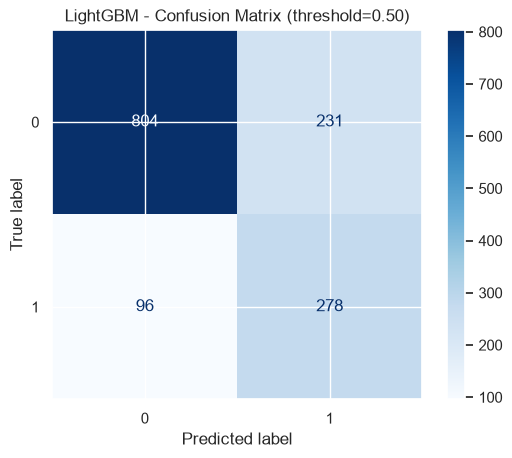

Train F1 Score (0.50): 0.8278
Test  F1 Score (0.50): 0.6297

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.89      0.78      0.83      1035
           1       0.55      0.74      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



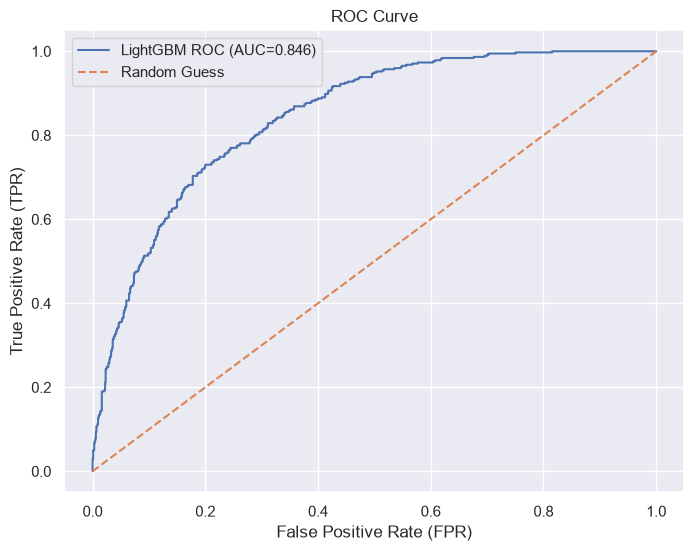

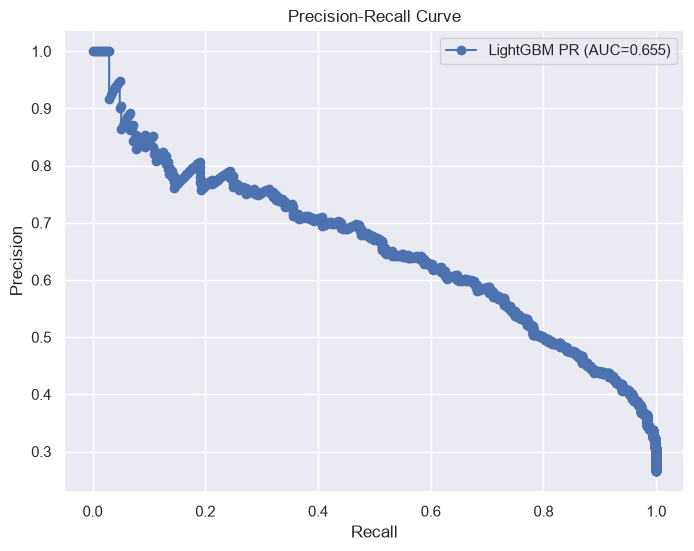

[LightGBM] Best F1-score = 0.6366 at threshold = 0.55


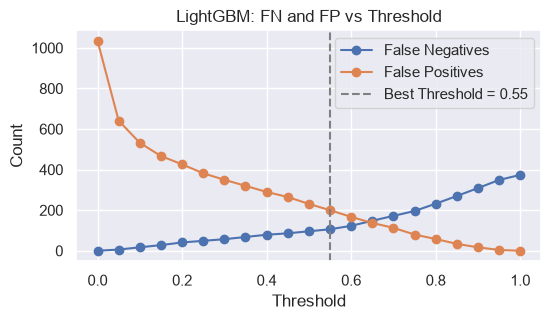

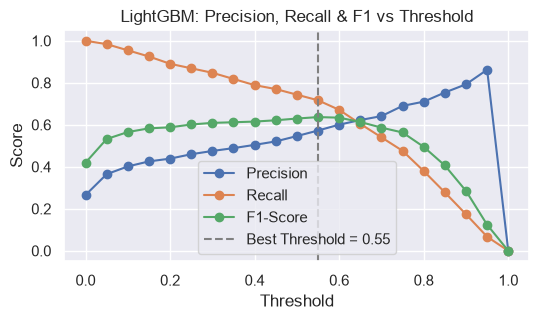

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [95]:
lgb2 = LGBMClassifier(
    class_weight='balanced',  # Some versions support this
    n_estimators=100,      # Number of trees
    max_depth=10,          # Max tree depth
    learning_rate=0.1,     # How fast it learns
    random_state=42
)
result_df, Probability_Threshold, Ranking_Threshold= store_results("LightGBM",X_train, y_train,X_test, y_test, lgb2, 5,"L2", 1,"Balanced")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison

## Tuning

In [96]:
"""param_grid = {

    # Tree structure
    'n_estimators': [100,200, 400, 800],
    'max_depth': [3, 5, 8,10, -1],   # -1 = no limit
    'num_leaves': [15, 31, 63, 127],

    #  Learning control
    'learning_rate': [0.01, 0.05, 0.1],

    #  Regularization
    'min_data_in_leaf': [20, 50, 100],
    'lambda_l2': [0, 1, 5],
    'lambda_l1': [0, 0.5, 1],

    # Sampling
    'feature_fraction': [0.7, 0.8, 0.9],
    'bagging_fraction': [0.7, 0.8, 0.9],
    'bagging_freq': [5]
}"""
param_grid = {

    # Tree structure
    'n_estimators': [100,200],
    'max_depth': [5, 8,10], 
    'num_leaves': [15, 31, 63, 127],

    #  Learning control
    'learning_rate': [0.01, 0.1],
}

clf_LGBM = GridSearchCV(
    LGBMClassifier(random_state=1234,class_weight='balanced'),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

clf_LGBM.fit(X_train, y_train)

clf_LGBM.best_params_

{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'num_leaves': 31}

Confusion matrix (prob threshold = 0.50):
[[789 246]
 [ 87 287]]


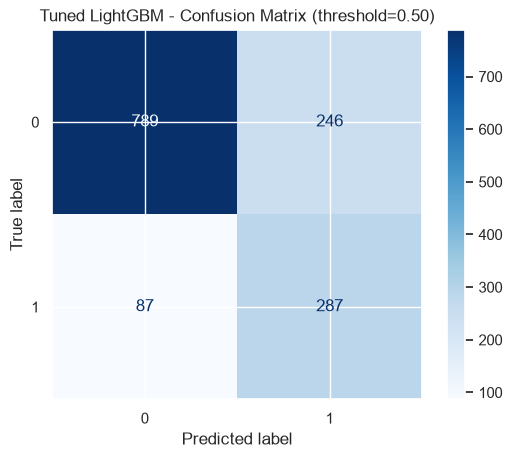

Train F1 Score (0.50): 0.743
Test  F1 Score (0.50): 0.6329

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.90      0.76      0.83      1035
           1       0.54      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



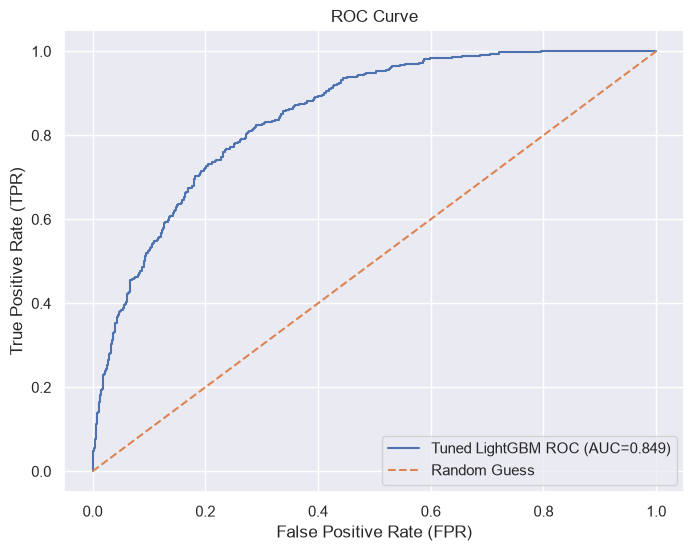

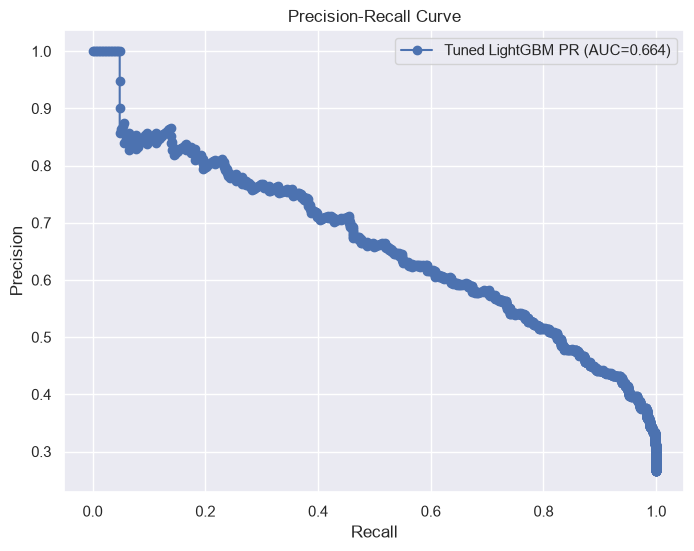

[Tuned LightGBM] Best F1-score = 0.6335 at threshold = 0.55


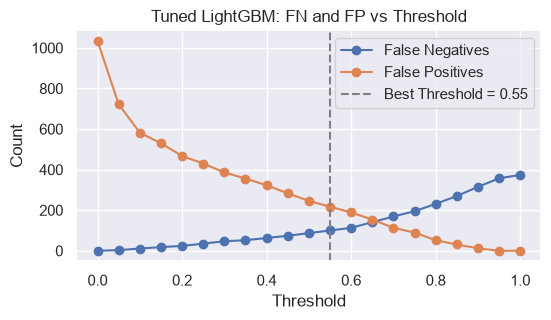

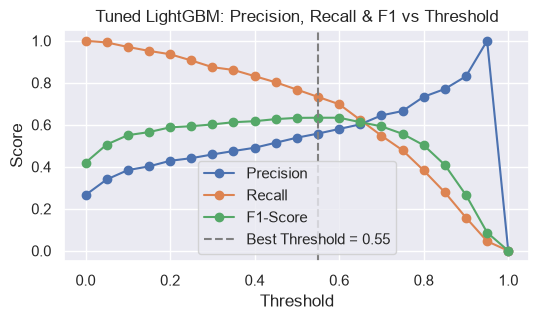

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [97]:
lgb3=clf_LGBM.best_estimator_
result_df, Probability_Threshold, Ranking_Threshold= store_results("Tuned LightGBM",X_train, y_train,X_test, y_test, lgb3, 5,"L2", 1,"Balanced")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison

In [101]:
Model_Comparison.to_csv(fr"{outputfolder}\Model_Comparison2_Classification.csv")
Probability_Threshold_Comparison.to_csv(fr"{outputfolder}\Probability_Threshold_Comparison_Classification.csv")
Ranking_Threshold_Comparison.to_csv(fr"{outputfolder}\Ranking_Threshold_Comparison_Classification.csv")

print("Classification model comparison saved successfully!")

Classification model comparison saved successfully!


In [102]:
#Feature Importance
feature_importances = XGB2.feature_importances_
features = X_train.columns
feature_importances_df = pd.DataFrame({'features': features, 'importance': feature_importances})
feature_importances_df.sort_values(by="importance", ascending=False).reset_index(drop=True)

,features,importance
0,Contract,0.347129
1,Dependents,0.084074
2,Tech_Support,0.070260
3,Online_Security,0.069184
4,Tenure_Months,0.044222
...,...,...
1146,City_Whitethorn,0.000000
1147,City_Whitmore,0.000000
1148,City_Witter_Springs,0.000000
1149,City_Wildomar,0.000000


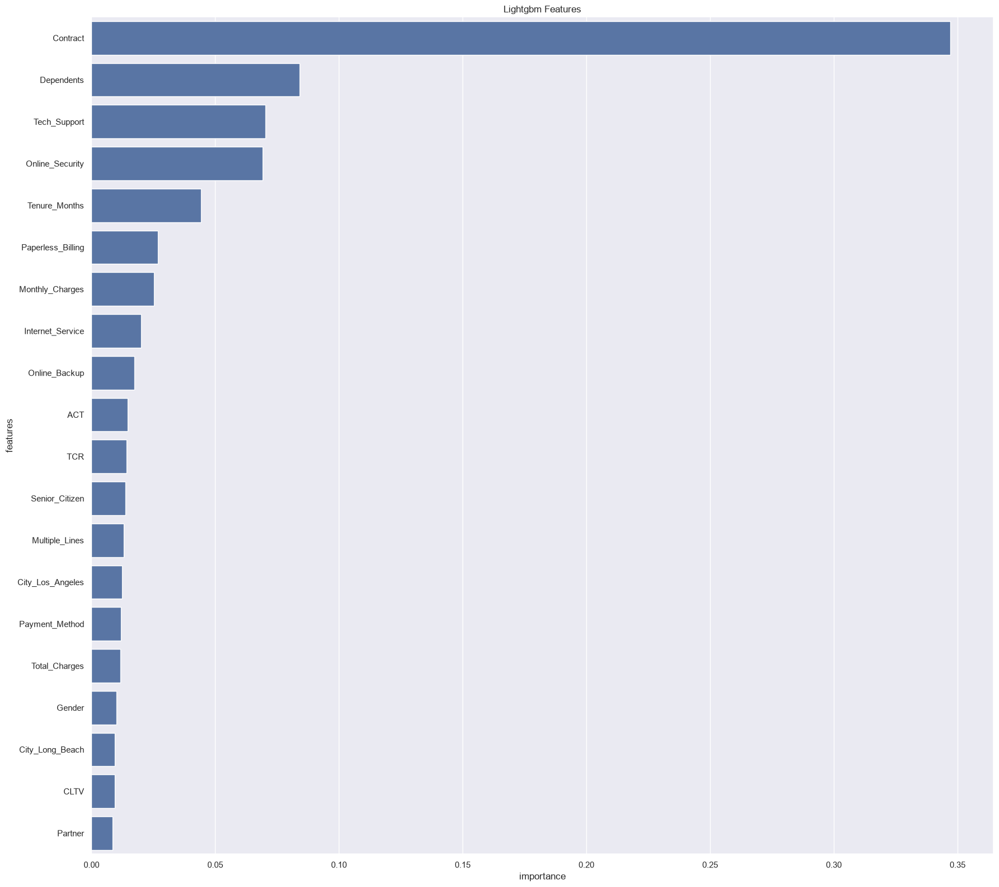

In [103]:
imp=feature_importances_df.sort_values(by="importance", ascending=False).head(20)
plt.figure(figsize=(18, 16))
sns.set(font_scale = 1)
sns.barplot(x="importance", y="features", data=imp.sort_values(by="importance", ascending=False))
plt.title('XGBoost Features')
plt.tight_layout()
plt.show()

## Catboost

Confusion matrix (prob threshold = 0.50):
[[938  97]
 [172 202]]


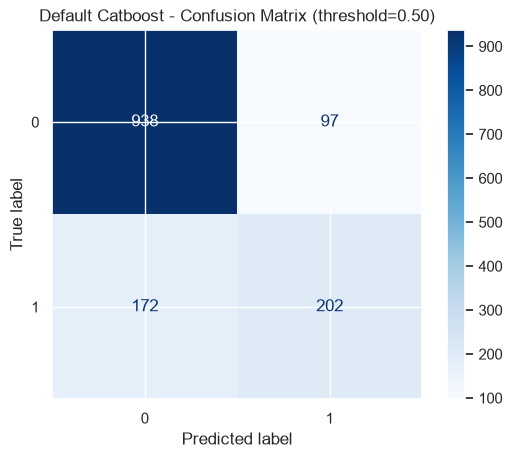

Train F1 Score (0.50): 0.6444
Test  F1 Score (0.50): 0.6003

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.85      0.91      0.87      1035
           1       0.68      0.54      0.60       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409



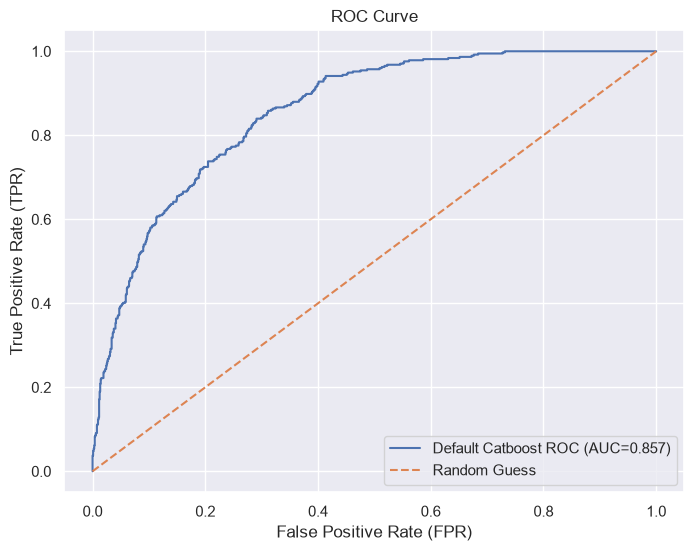

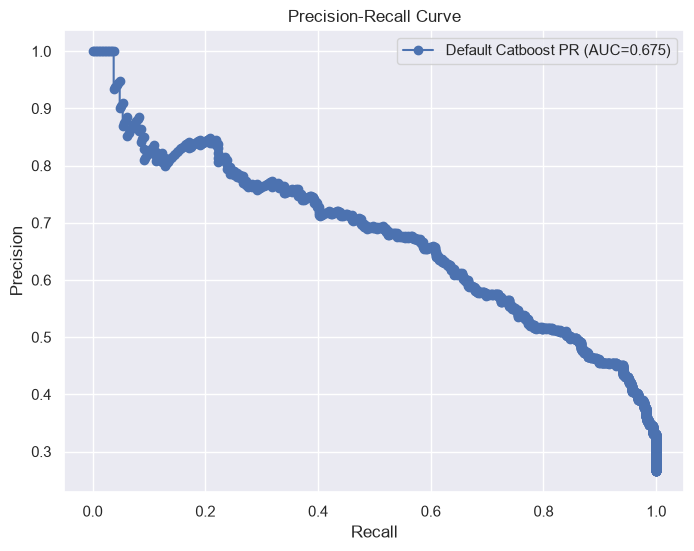

[Default Catboost] Best F1-score = 0.6362 at threshold = 0.35


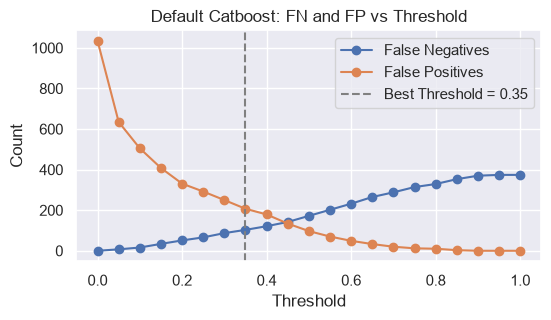

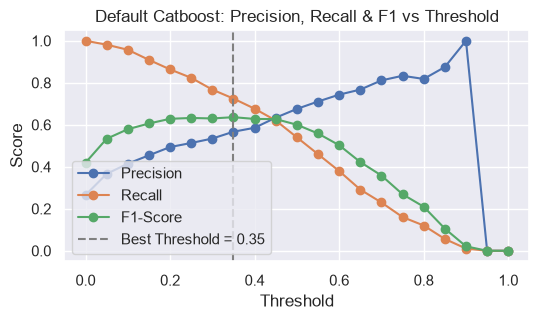

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [104]:
CatB = CatBoostClassifier(iterations=100, learning_rate=0.1, depth=4, loss_function='Logloss',verbose=0)
result_df, Probability_Threshold, Ranking_Threshold= store_results("Default Catboost",X_train, y_train,X_test, y_test, CatB, 5,"NA", "NA","NA")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison 

## Tuning

In [105]:

param_grid = {
    # Tree structure
    'iterations':[200,300,400,500],      # Equivalent to n_estimators
    'depth':[3,4,5,6],          # Equivalent to max_depth (CatBoost uses 'depth')
    
    # Learning control
    'learning_rate': [0.01, 0.1],
}

# Initialize GridSearchCV with CatBoostClassifier
clf_CatBoost = GridSearchCV(
    CatBoostClassifier(
        random_state=1234,
        auto_class_weights='Balanced',  # Handles class imbalance natively
        verbose=0                      # Prevents flooding the output console
    ),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

# Fit the grid search (make sure to pass your cat_features parameter here if you have categorical columns)
# clf_CatBoost.fit(X_train, y_train, cat_features=your_cat_features_list)
clf_CatBoost.fit(X_train, y_train)

# Output the best parameters found
clf_CatBoost.best_params_

{'depth': 6, 'iterations': 400, 'learning_rate': 0.01}

Confusion matrix (prob threshold = 0.50):
[[764 271]
 [ 80 294]]


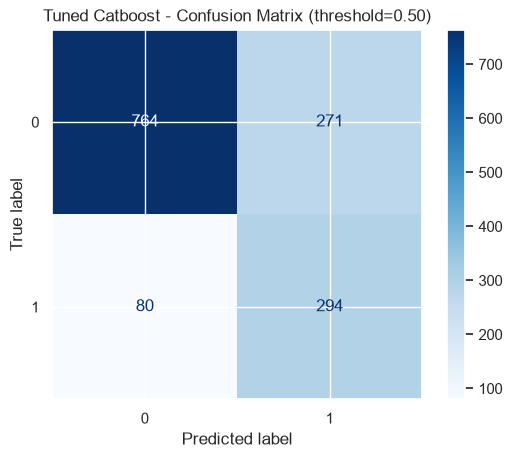

Train F1 Score (0.50): 0.6718
Test  F1 Score (0.50): 0.6262

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.91      0.74      0.81      1035
           1       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



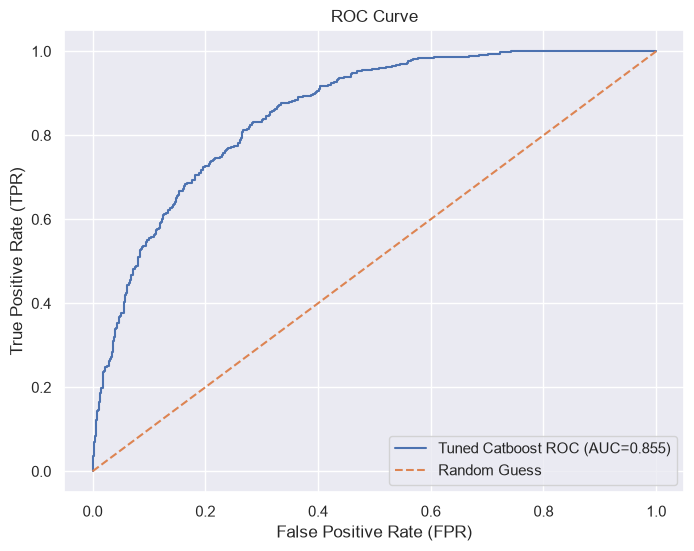

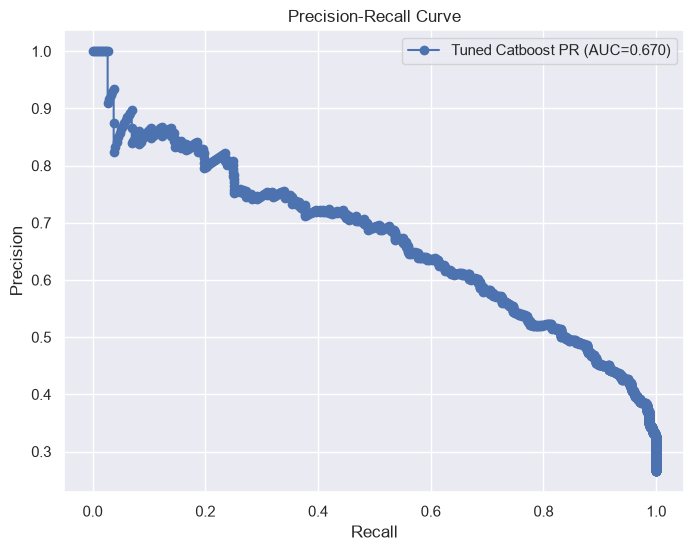

[Tuned Catboost] Best F1-score = 0.6356 at threshold = 0.60


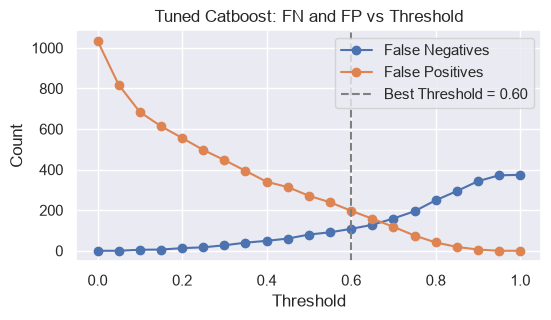

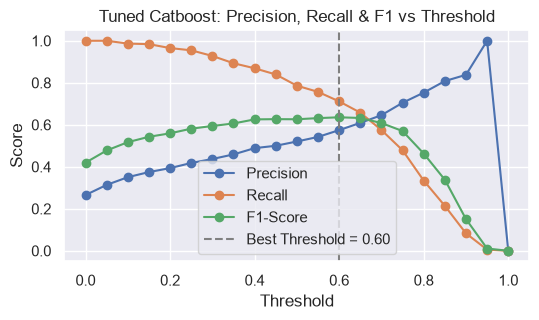

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [106]:
CatB_Tuned=clf_CatBoost.best_estimator_
result_df, Probability_Threshold, Ranking_Threshold= store_results("Tuned Catboost",X_train, y_train,X_test, y_test, CatB_Tuned, 5,"NA", "NA","NA")
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison 

In [107]:
Model_Comparison.to_csv(fr"{outputfolder}\Model_Comparison2_Classification.csv")
Probability_Threshold_Comparison.to_csv(fr"{outputfolder}\Probability_Threshold_Comparison_Classification.csv")
Ranking_Threshold_Comparison.to_csv(fr"{outputfolder}\Ranking_Threshold_Comparison_Classification.csv")

## Feature Importance

In [108]:
feature_importances = CatB_Tuned.feature_importances_
features = X_train.columns
feature_importances_df = pd.DataFrame({'features': features, 'importance': feature_importances})
feature_importances_df.sort_values(by="importance", ascending=False).reset_index(drop=True)

,features,importance
0,Dependents,26.239003
1,Contract,20.982578
2,Tenure_Months,8.451420
3,Internet_Service,5.237049
4,Online_Security,4.009087
...,...,...
1146,City_Whitethorn,0.000000
1147,City_Whitmore,0.000000
1148,City_Ballico,0.000000
1149,City_Wildomar,0.000000


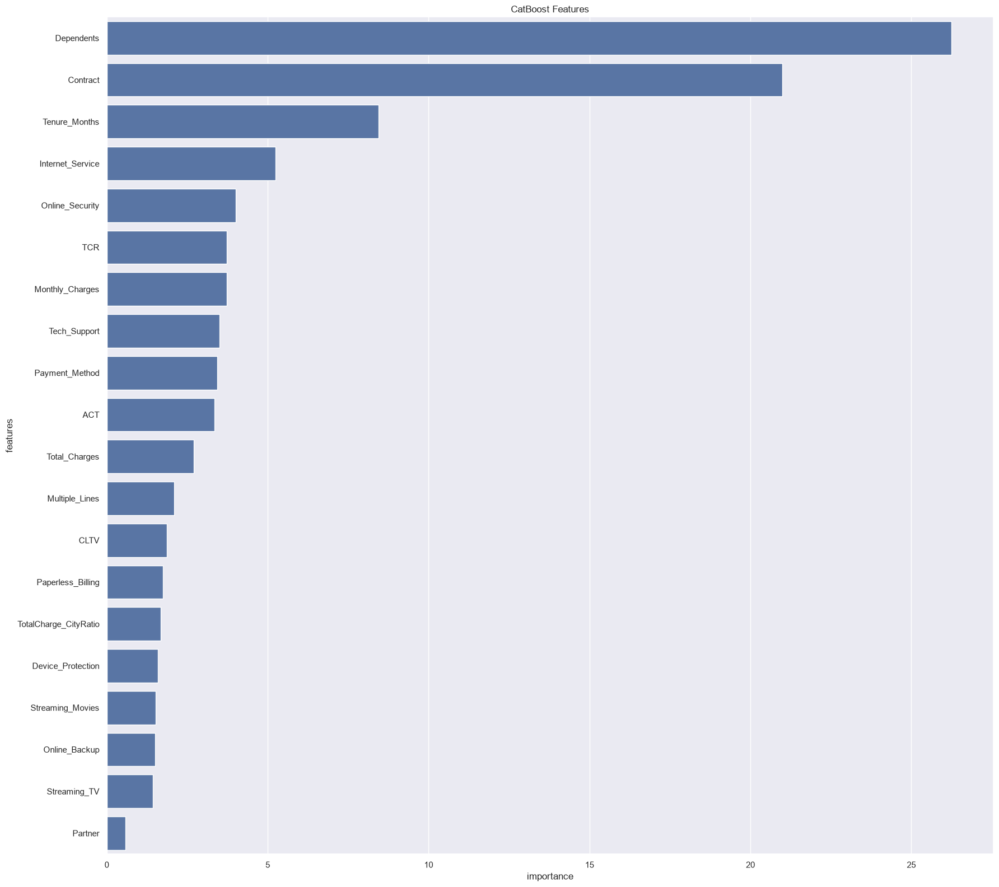

In [109]:
imp=feature_importances_df.sort_values(by="importance", ascending=False).head(20)
plt.figure(figsize=(18, 16))
sns.set(font_scale = 1)
sns.barplot(x="importance", y="features", data=imp.sort_values(by="importance", ascending=False))
plt.title('CatBoost Features')
plt.tight_layout()
plt.show()

## Neural Network

Confusion matrix (prob threshold = 0.50):
[[1035    0]
 [ 374    0]]


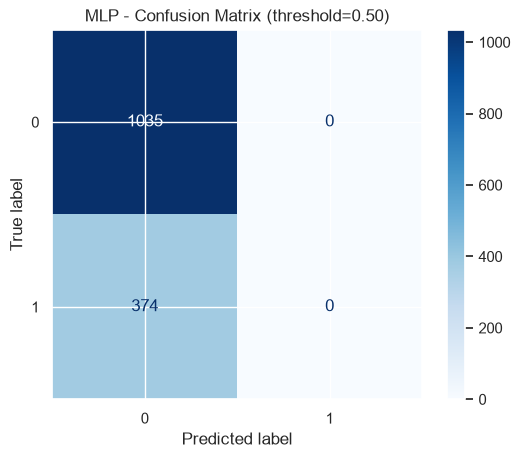

Train F1 Score (0.50): 0.0013
Test  F1 Score (0.50): 0.0

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1035
           1       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409



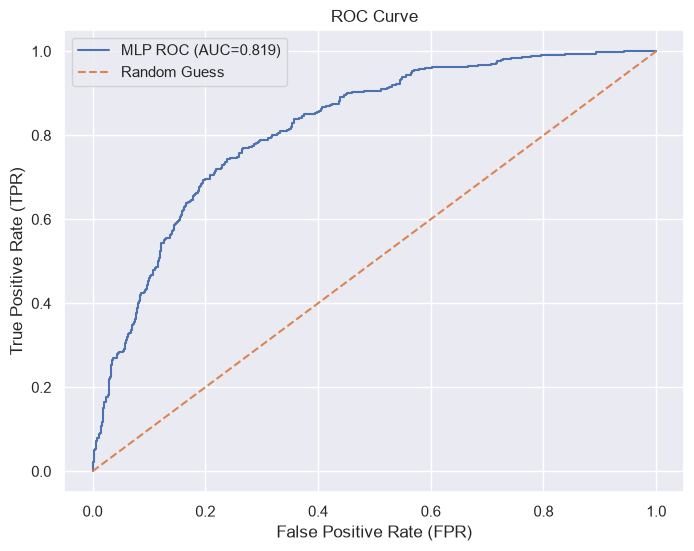

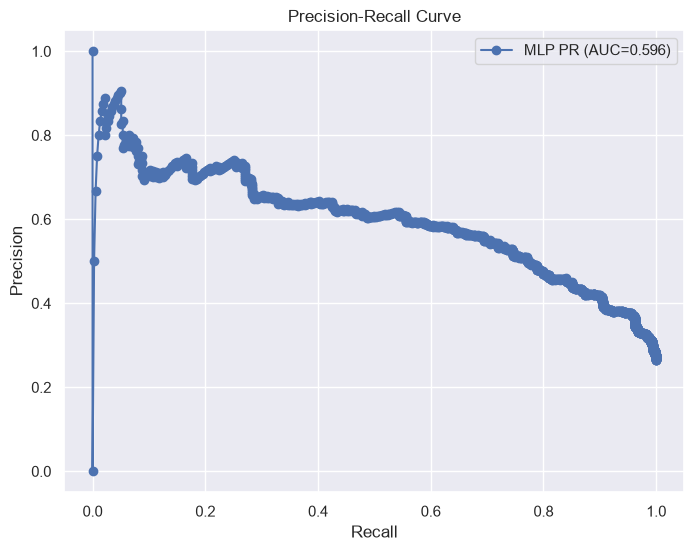

[MLP] Best F1-score = 0.6141 at threshold = 0.35


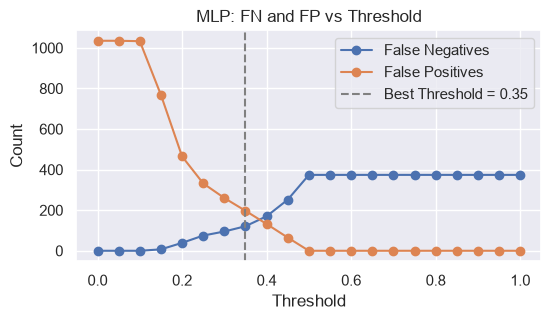

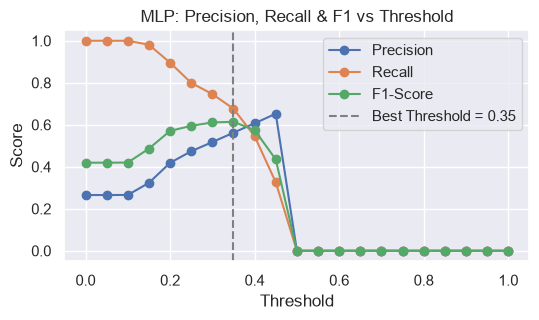

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [110]:
#step1 : import classifier
from sklearn.neural_network import MLPClassifier
#step 2: create an intanse

MLP = MLPClassifier(hidden_layer_sizes=(10,12), #I designed 2 hidden layers for HL1 I put 10 Nerouns and HL2 I put 12 Neorons 
                    activation='relu', # activation = 'identity', 'logistic', 'relu', 'tanh'
                    learning_rate_init=0.01,# normaly best learning rate between .001 and 0.1
                    learning_rate='invscaling',# I learning rate will be started from 0.01 and decreases gradually
                    solver='sgd',#earning_rate='invscaling' works only with solver='sgd'
                    max_iter=50,
                    #momentum=0.5,
                    #batch_size=32,      # Mini-batch size 
                    #batch_size=X_train_scaled.shape[0] #Full Batch Gradient Descent
                   )
result_df, Probability_Threshold, Ranking_Threshold= store_results("MLP",X_train_scaled, y_train_scaled,X_test_scaled, y_test_scaled, MLP, 5,"NA", "NA","NA",fit=True)
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison

## Keras Sequential

In [111]:
model_nn = keras.Sequential([
    keras.layers.Dense(64, activation='relu',#a hidden layer of 64 neurons
                       input_shape=(X_train_scaled.shape[1],)),#relu activation function helped learn
                                                            #complex, non-linear relationships
    keras.layers.Dropout(0.3), #randomly turned off 30% of the neurons during training 
                                #to prevent the network from just memorizing the data (overfitting)
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation='sigmoid')
])

model_nn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_nn.fit(
    X_train_scaled, y_train_scaled,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# Get probability predictions
y_pred_proba_nn = model_nn.predict(X_test_scaled, verbose=0).flatten()

# Find optimal threshold and evaluate
metrics_nn = find_optimal_threshold_and_evaluate(y_test_scaled, y_pred_proba_nn, "Neural Network")

print_results_table([metrics_nn], "NEURAL NETWORK")


NEURAL NETWORK
Model                     Optimal θ    F1 (Optimal)    F1 (Default)    ROC-AUC      PR-AUC      
-------------------------------------------------------------------------------------------------------------------
Neural Network            0.010        0.5461          0.4622          0.7693       0.5403      



store_results() function is designed for scikit-learn models because it expects methods like:
```python
model.fit()
model.predict_proba()
```

A Keras Sequential model has:
```python
model.fit()
model.predict()
```
but does not have:
```python
model.predict_proba()
```
Therefore, our current store_results() will fail at:
```python
y_prob = model.predict_proba(X_test)[:,1]
```

`So one option is Wrap the Keras model to mimic scikit-learn`

In [112]:
from sklearn.base import BaseEstimator, ClassifierMixin
import numpy as np
from tensorflow import keras

class KerasBinaryWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, input_dim, epochs=50, batch_size=32, verbose=0):
        self.input_dim = input_dim
        self.epochs = epochs
        self.batch_size = batch_size
        self.verbose = verbose

    def build_model(self):
        model = keras.Sequential([
            keras.layers.Dense(64, activation='relu', input_shape=(self.input_dim,)),
            keras.layers.Dropout(0.3),
            keras.layers.Dense(32, activation='relu'),
            keras.layers.Dropout(0.3),
            keras.layers.Dense(1, activation='sigmoid')
        ])

        model.compile(
            optimizer='adam',
            loss='binary_crossentropy',
            metrics=['accuracy']
        )

        return model

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.model_ = self.build_model()

        self.model_.fit(
            X,
            np.asarray(y).ravel(),
            epochs=self.epochs,
            batch_size=self.batch_size,
            validation_split=0.2,
            verbose=self.verbose
        )

        return self

    def predict_proba(self, X):
        prob_1 = self.model_.predict(X, verbose=0).ravel()
        prob_0 = 1 - prob_1
        return np.column_stack([prob_0, prob_1])

    def predict(self, X):
        prob_1 = self.predict_proba(X)[:, 1]
        return (prob_1 >= 0.5).astype(int)

Confusion matrix (prob threshold = 0.50):
[[886 149]
 [203 171]]


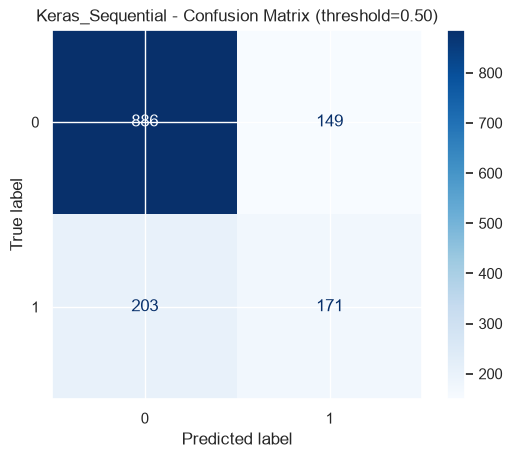

Train F1 Score (0.50): 0.8978
Test  F1 Score (0.50): 0.4928

Classification Report (0.50):
              precision    recall  f1-score   support

           0       0.81      0.86      0.83      1035
           1       0.53      0.46      0.49       374

    accuracy                           0.75      1409
   macro avg       0.67      0.66      0.66      1409
weighted avg       0.74      0.75      0.74      1409



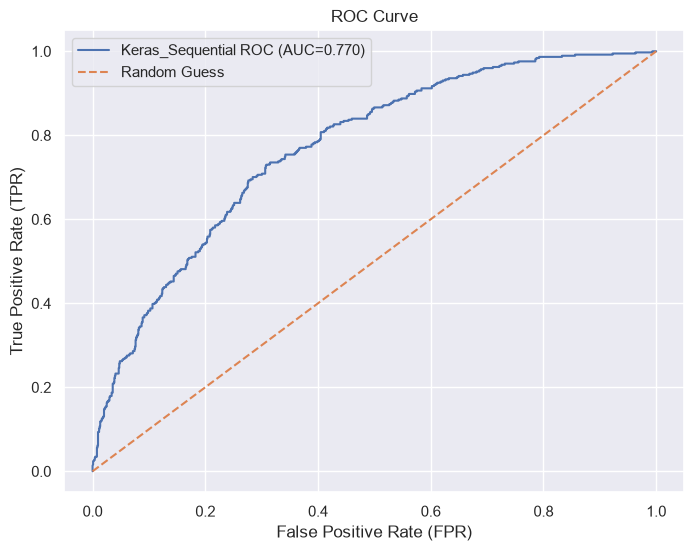

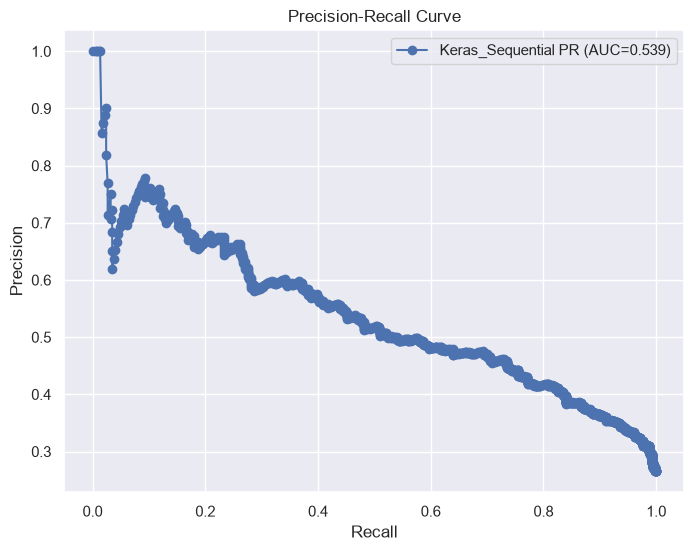

[Keras_Sequential] Best F1-score = 0.5329 at threshold = 0.05


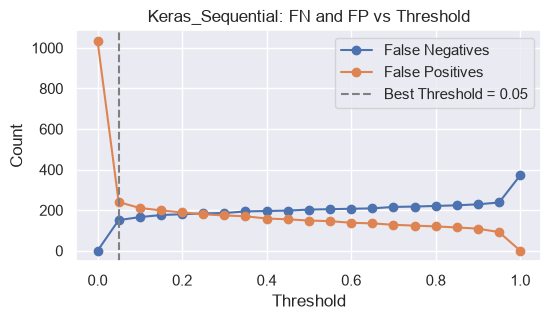

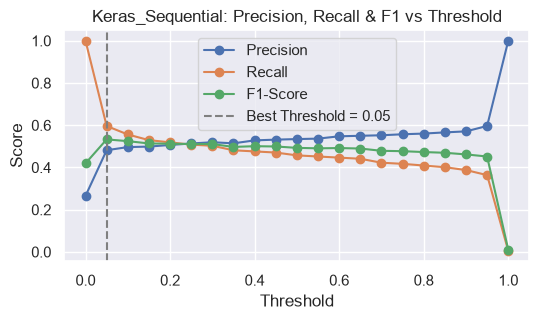

In [113]:
keras_wrapper = KerasBinaryWrapper(
    input_dim=X_train_scaled.shape[1],
    epochs=50,
    batch_size=32,
    verbose=0
)

result_df, Probability_Threshold, Ranking_Threshold = store_results(
    "Keras_Sequential",
    X_train_scaled,
    y_train_scaled,
    X_test_scaled,
    y_test_scaled,
    keras_wrapper,
    5,
    "NA",
    "NA",
    "NA",
    fit=True
)

In [114]:
Model_Comparison = pd.concat([Model_Comparison , result_df], ignore_index=True)
Probability_Threshold_Comparison = pd.concat([Probability_Threshold_Comparison , Probability_Threshold ], ignore_index=True)
Ranking_Threshold_Comparison = pd.concat([Ranking_Threshold_Comparison , Ranking_Threshold ], ignore_index=True)
Model_Comparison

,Model,Class_weight,Test_ROC_AUC,Train_PR_AUC,Test_PR_AUC,Train_Test_Gap(PR_AUC),CrossVal_Std(PR_AUC),CrossVal_Mean(ROC_AUC),CrossVal_Mean_Accuracy,CrossVal_Mean(F1_score),CrossVal_Mean(PR_AUC),train_accuracy_score@0.50,test_accuracy_score@0.50,train_f1_score@0.50,test_f1_score@0.50,max_f1score,best_Prob_threshold,CrossVal1(f1),CrossVal2(f1),CrossVal3(f1),CrossVal4(f1),CrossVal5(f1),CrossVal1(PR_AUC),CrossVal2(PR_AUC),CrossVal3(PR_AUC),CrossVal4(PR_AUC),CrossVal5(PR_AUC),Train_Precision@top1%,Train_Recall@top1%,Train_Lift@top1%,Test_Precision@top1%,Test_Recall@top1%,Test_Lift@top1%,Train_Precision@top5%,Train_Recall@top5%,Train_Lift@top5%,Test_Precision@top5%,Test_Recall@top5%,Test_Lift@top5%,Train_Precision@top10%,Train_Recall@top10%,Train_Lift@top10%,Test_Precision@top10%,Test_Recall@top10%,Test_Lift@top10%,Regularization,C
0,Default Logistic Regression,NA,0.8485,0.7905,0.6662,0.1243,0.0186,0.8546,0.8090,0.6136,0.6719,0.8559,0.8070,0.7085,0.6136,0.623907,0.20,0.5899,0.5811,0.6154,0.6430,0.6385,0.6631,0.6403,0.6929,0.6785,0.6848,1.0000,0.0381,3.7686,0.9333,0.0374,3.5162,0.9468,0.1786,3.5681,0.8451,0.1604,3.1837,0.8954,0.3378,3.3743,0.7589,0.2861,2.8589,L2,1
1,Logistic Regression_class weight balanced,Balanced,0.8450,0.7771,0.6580,0.1191,0.0162,0.8523,0.7602,0.6311,0.6661,0.8048,0.7480,0.7004,0.6162,0.627838,0.40,0.6332,0.6118,0.6022,0.6434,0.6648,0.6529,0.6415,0.6836,0.6725,0.6797,0.9825,0.0375,3.7024,0.8667,0.0348,3.2651,0.9007,0.1699,3.3944,0.8310,0.1578,3.1306,0.8688,0.3278,3.2741,0.7376,0.2781,2.7788,L2,1
2,Logistic Regression_ SMOTE,SMOTE,0.8403,0.9130,0.6467,0.2664,0.0079,0.8926,0.8101,0.8182,0.8682,0.8467,0.7495,0.8522,0.6073,0.621094,0.35,0.8159,0.8190,0.8223,0.8155,0.8182,0.8704,0.8649,0.8814,0.8570,0.8674,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9614,0.0962,1.9227,0.7887,0.1497,2.9715,0.9601,0.1921,1.9203,0.7376,0.2781,2.7788,L2,1
3,Logistic Regression_ DownSampled,DownSampled,0.8494,0.9087,0.6726,0.2361,0.0176,0.8493,0.7722,0.7790,0.8352,0.8234,0.7402,0.8285,0.6164,0.622605,0.40,0.7735,0.7902,0.7650,0.7865,0.7798,0.8413,0.8618,0.8085,0.8258,0.8386,1.0000,0.0201,2.0000,0.8667,0.0348,3.2651,0.9933,0.0997,1.9867,0.8873,0.1684,3.3429,0.9833,0.1967,1.9666,0.7801,0.2941,2.9391,L2,1
4,Logistic Regression_class weight balanced_L1,Balanced,0.8518,0.6868,0.6666,0.0202,0.0253,0.8583,0.7638,0.6456,0.6835,0.7643,0.7473,0.6459,0.6237,0.631043,0.65,0.6596,0.6344,0.6245,0.6545,0.6548,0.6593,0.6546,0.7233,0.6979,0.6825,0.8772,0.0334,3.3058,0.9333,0.0374,3.5162,0.8688,0.1639,3.2741,0.8310,0.1578,3.1306,0.7926,0.2990,2.9868,0.7447,0.2807,2.8055,L1,1
5,Logistic Regression_class weight L2,Balanced,0.8454,0.7780,0.6584,0.1196,0.0154,0.8522,0.7597,0.6305,0.6658,0.8062,0.7473,0.7016,0.6147,0.627838,0.40,0.6350,0.6118,0.6011,0.6426,0.6620,0.6533,0.6427,0.6832,0.6708,0.6789,0.9649,0.0368,3.6363,0.8667,0.0348,3.2651,0.9043,0.1706,3.4077,0.8310,0.1578,3.1306,0.8706,0.3284,3.2808,0.7376,0.2781,2.7788,L2,1
6,Decision Tree with max_depth=3,Balanced,0.8031,0.5216,0.5028,0.0189,0.0095,0.8106,0.7006,0.6046,0.5153,0.7075,0.6991,0.6102,0.5977,0.600690,0.55,0.6053,0.6047,0.6047,0.6041,0.6044,0.5079,0.5011,0.5180,0.5267,0.5228,0.5263,0.0201,1.9835,0.6000,0.0241,2.2604,0.5567,0.1050,2.0981,0.6761,0.1283,2.5470,0.5532,0.2087,2.0847,0.6170,0.2326,2.3246,NA,NA
7,Tuned Decision Tree,Balanced,0.8242,0.7049,0.5846,0.1203,0.0182,0.8300,0.7480,0.6250,0.6159,0.7709,0.7367,0.6674,0.6171,0.617587,0.45,0.6164,0.6179,0.6212,0.6250,0.6442,0.6168,0.5816,0.6355,0.6236,0.6219,1.0000,0.0381,3.7686,0.6000,0.0241,2.2604,0.8759,0.1652,3.3008,0.7324,0.1390,2.7592,0.8280,0.3124,3.1204,0.6879,0.2594,2.5917,NA,NA
8,Bagging Classifier,NA,0.8069,0.9964,0.5782,0.4181,0.0307,0.8150,0.7936,0.5523,0.5971,0.9863,0.7821,0.9742,0.5742,0.618721,0.25,0.5709,0.4886,0.5592,0.5795,0.5634,0.5958,0.5379,0.6166,0.6171,0.6181,1.0000,0.0381,3.7686,0.7333,0.0294,2.7627,1.0000,0.1886,3.7686,0.7606,0.1444,2.8653,1.0000,0.3773,3.7686,0.6596,0.2487,2.4849,NA,NA
9,Default Random Forest,NA,0.8482,1.0

In [115]:
Model_Comparison.to_csv(fr"{outputfolder}\Model_Comparison2_Classification.csv")
Probability_Threshold_Comparison.to_csv(fr"{outputfolder}\Probability_Threshold_Comparison_Classification.csv")
Ranking_Threshold_Comparison.to_csv(fr"{outputfolder}\Ranking_Threshold_Comparison_Classification.csv")

print("Classification model comparison saved successfully!")

Classification model comparison saved successfully!


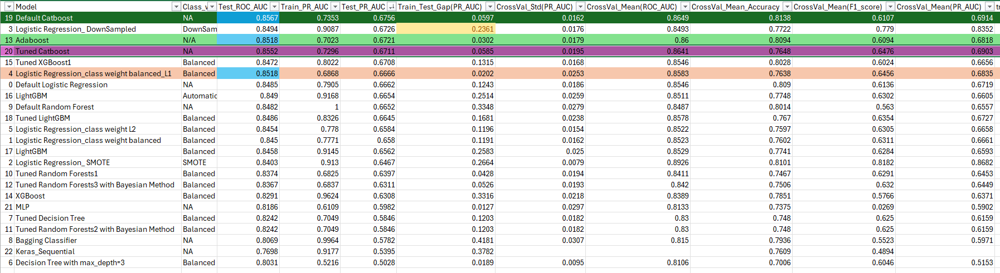

# Champion–Challenger Model Selection

## Objective
The objective of this analysis is to identify the most suitable Champion and Challenger models based on their predictive performance, generalization ability, and stability across cross-validation folds. Given the class imbalance in the dataset, particular emphasis was placed on **PR AUC**, **ROC AUC**, and model robustness.

---

## Champion Model: Default CatBoost

### Key Performance Metrics

| Metric | Value |
|----------|---------|
| Test ROC AUC | 0.8567
| Test PR AUC | 0.6756 |
| Train-Test Gap (PR AUC) | 0.0597 |
| CV ROC AUC Mean | 0.8649 |
| CV PR AUC Mean | 0.6914 |
| CV F1 Mean | 0.6107 |
| Best Probability Threshold | 0.25 |

## Note on Tuned Catboost: Tuning decreased the Test_PR_AUC (0.8552) and less generalization gap (0.0585) decreased from Default CatBoost (0.0597), making the Default version the better choice.

### Rationale

The Defalut CatBoost model was selected as the **Champion** because it provides the best overall balance between predictive performance and generalization:

- Achieved the highest **Test ROC AUC** values.
- Produced the highest **Test PR AUC**, which is particularly important for imbalanced classification problems.
- Demonstrated a relatively small train-test performance gap, indicating limited overfitting.
- Delivered strong and consistent cross-validation results.
- Achieved the highest cross-validation F1 score= 0.874 among the leading candidates.

Overall, Default CatBoost offers the strongest combination of discrimination power, stability, and generalization performance.

---

## Challenger Model: AdaBoost

### Key Performance Metrics

| Metric | Value |
|----------|---------|
| Test ROC AUC | 0.8518 |
| Test PR AUC | 0.6721 |
| Train-Test Gap (PR AUC) | 0.0302 |
| CV ROC AUC Mean | 0.86 |
| CV PR AUC Mean | 0.6818 |
| CV F1 Mean | 0.6094 |
| Best Probability Threshold | 0.65 |

### Rationale

The AdaBoost model was selected as the **Challenger** because:

- It achieved the second highest Test ROC AUC among all evaluated models with combination of Test ROC_AUC.
- It demonstrated the  smallest train-test performance gap as compared to Logistic Regression_ DownSampled , suggesting excellent generalization.
- It achieved fourth average ROC AUC and PR AUC across cross-validation folds.
- Cross-validation results indicate strong model stability.

Although its ranking performance is extremely competitive, its classification performance (F1 score) is weaker than Default CatBoost. Therefore, it is retained as the Challenger model for ongoing monitoring and future comparison.

---

## Models Not Selected

### Default Random Forest
- Significant overfitting observed.
- Train PR AUC = 1.00 compared with Test PR AUC = 0.9151.

### Tuned LightGBM
- Relatively Large train-test gap compared to other models.
- Lower ROC_AUC score comapred to the top performing models.

### Bagging Classifier
- Train PR AUC = 0.9991 versus Test PR AUC = 0.6652.
- Generalization performance is weaker than the selected models.

### Logistic Regression Variants
- Lower ROC AUC and PR AUC compared with Default CatBoost and AdaBoost.
- Did not provide sufficient improvement in stability or interpretability to offset the performance gap.

---

## Final Recommendation

| Role | Model |
|--------|--------|
| **Champion** | **Default CatBoost** |
| **Challenger** | **AdaBoost** |
| **Benchmark / Reserve** | **CatBoost (Tuned)** |

The Champion–Challenger framework will use **Default CatBoost** as the production model and **AdaBoost1** as the primary challenger for ongoing performance monitoring and future model validation exercises.fitting

# Model Explainabilty

In [119]:
#Feature Importance
feature_importances = CatB.feature_importances_
features = X_train.columns
feature_importances_df = pd.DataFrame({'features': features, 'importance': feature_importances})
feature_importances_df.sort_values(by="importance", ascending=False).reset_index(drop=True)


,features,importance
0,Dependents,30.404448
1,Contract,24.629570
2,Tenure_Months,10.326963
3,ACT,4.411088
4,Online_Security,4.130488
...,...,...
1146,City_Whitethorn,0.000000
1147,City_Whitmore,0.000000
1148,City_Whittier,0.000000
1149,City_Wildomar,0.000000


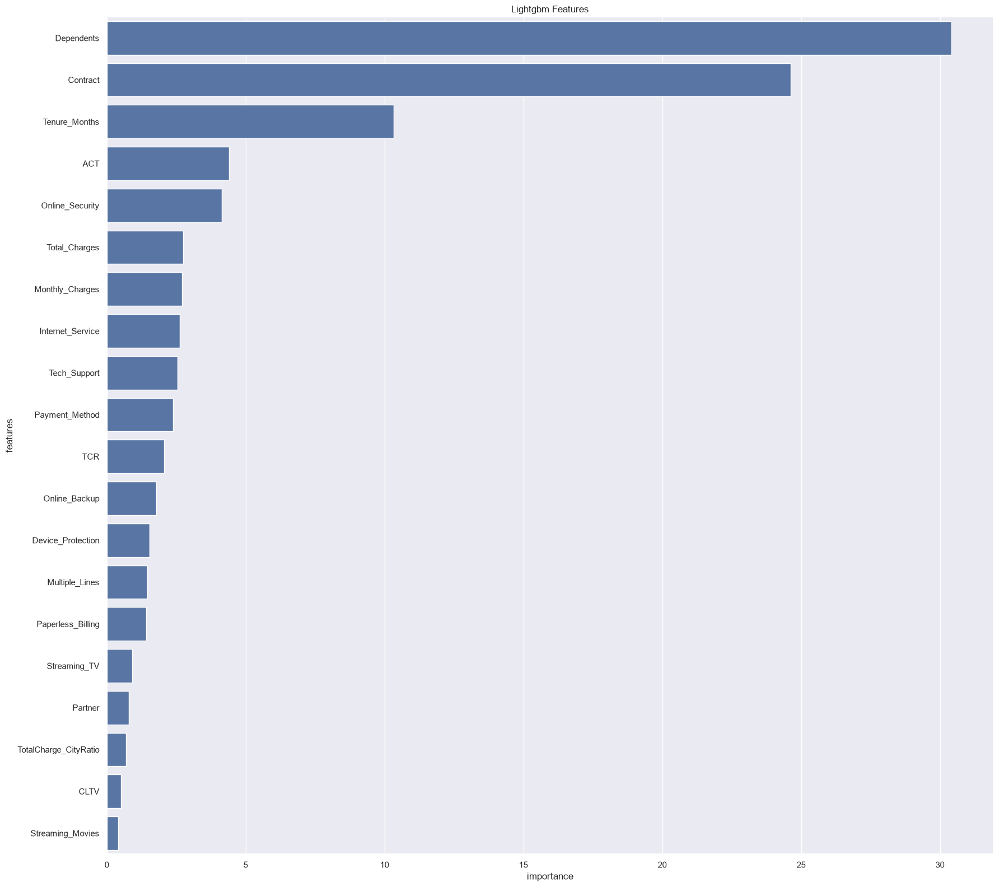

In [120]:
imp=feature_importances_df.sort_values(by="importance", ascending=False).head(20)
plt.figure(figsize=(18, 16))
sns.set(font_scale = 1)
sns.barplot(x="importance", y="features", data=imp.sort_values(by="importance", ascending=False))
plt.title('Default CatBoost Features')
plt.tight_layout()
plt.show()

## SHAP: Individual AND Aggregate

In [125]:
#For Tuned Lightgbm
X_train=X_train_gb.copy()
y_train =y_train_gb.copy()
X_test=X_test_gb.copy()
y_test = y_test_gb.copy()
model=CatB

STEP 1: Training LightGBM Model
Accuracy:  0.8091
F1-Score:  0.6003
ROC-AUC:   0.8567

Model trained successfully!
Training samples: 5634
Test samples: 1409
Features: 1151


PART 1: SHAP ANALYSIS

Initializing SHAP TreeExplainer...
Calculating SHAP values (this may take a minute)...
SHAP values calculated! Shape: (1409, 1151)

--------------------------------------------------------------------------------
SHAP PLOT 1: Summary Plot (Global Importance)
--------------------------------------------------------------------------------

SUMMARY PLOT INTERPRETATION
This plot shows:
- X-axis: SHAP value (impact on prediction)
- Y-axis: Features (ranked by importance)
- Color: Feature value (red=high, blue=low)
- Each dot: One prediction from test set

How to read it:
1. Features at the TOP are most important
2. Wide spread = feature has varying impact
3. Red dots on RIGHT = high feature values increase prediction
4. Blue dots on LEFT = low feature values decrease prediction

Example interpret

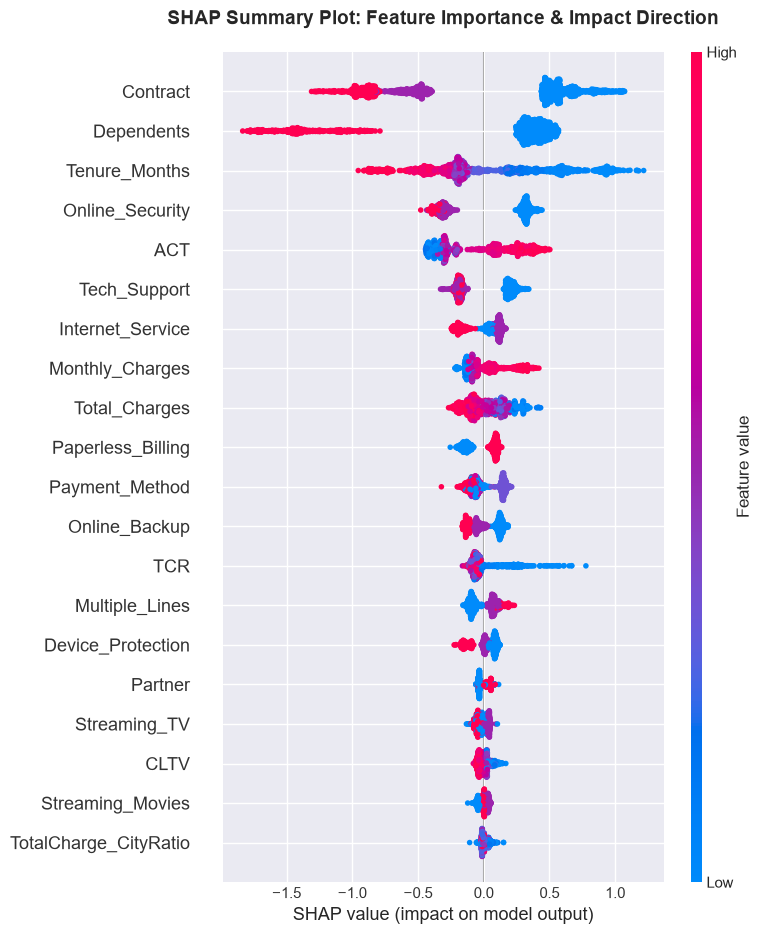


--------------------------------------------------------------------------------
SHAP PLOT 2: Bar Plot (Mean Absolute Impact)
--------------------------------------------------------------------------------

BAR PLOT INTERPRETATION
This plot shows the AVERAGE absolute impact of each feature.

How to read it:
- Longer bar = More important feature (on average)
- This ignores the DIRECTION (positive/negative)
- Just shows MAGNITUDE of impact

Example:
If "Annual Income" has bar length 0.15:
- On average, Annual Income changes predictions by ±0.15
- Some customers it increases risk, some it decreases
- But on average, it has a 0.15 magnitude impact

✓ Saved: shap_bar_plot_classification.png


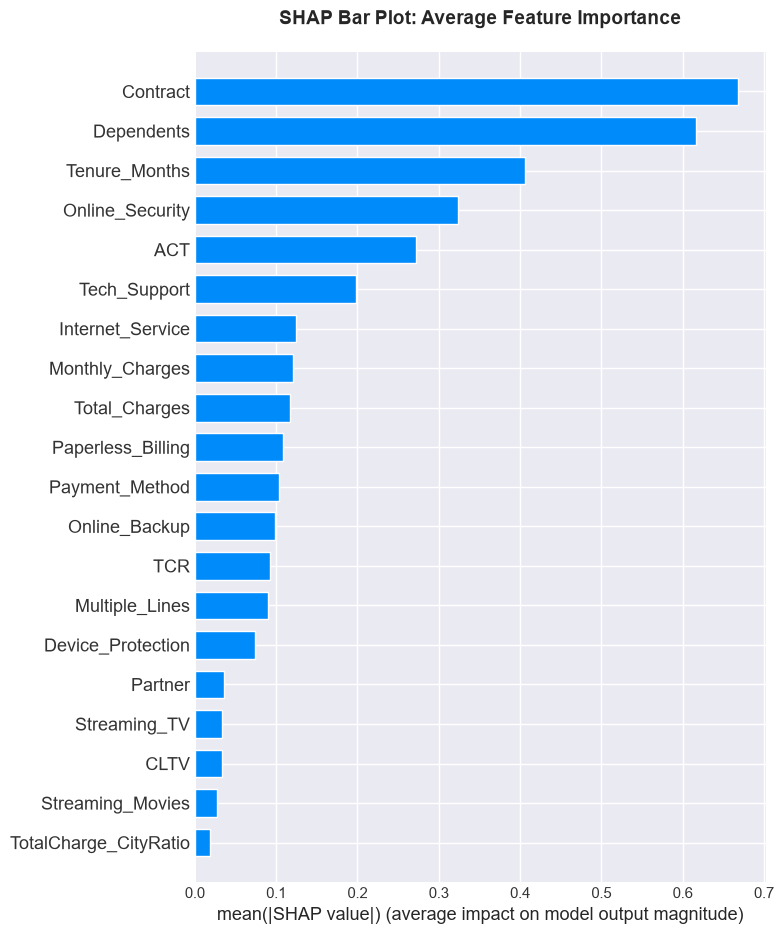


--------------------------------------------------------------------------------
SHAP PLOT 3: Waterfall Plot (Individual Explanation)
--------------------------------------------------------------------------------

WATERFALL PLOT INTERPRETATION
This explains ONE specific prediction step-by-step.

How to read it:
- Starts at base value (average prediction for all customers)
- Each bar shows how one feature pushes prediction up or down
- Red bars = Push prediction HIGHER (increase default risk)
- Blue bars = Push prediction LOWER (decrease default risk)
- Final value at top = actual prediction for this customer

Example walkthrough:
1. Base value: 0.15 (15% average default rate)
2. Low income (+0.30): Now at 0.45
3. High debt ratio (+0.25): Now at 0.70
4. Good credit score (-0.10): Now at 0.60
5. ... (other features)
6. Final prediction: 0.85 (85% default probability)

This tells the STORY of why this specific customer is high risk.

Analyzing high-risk customer (index 1090)
Predicted 

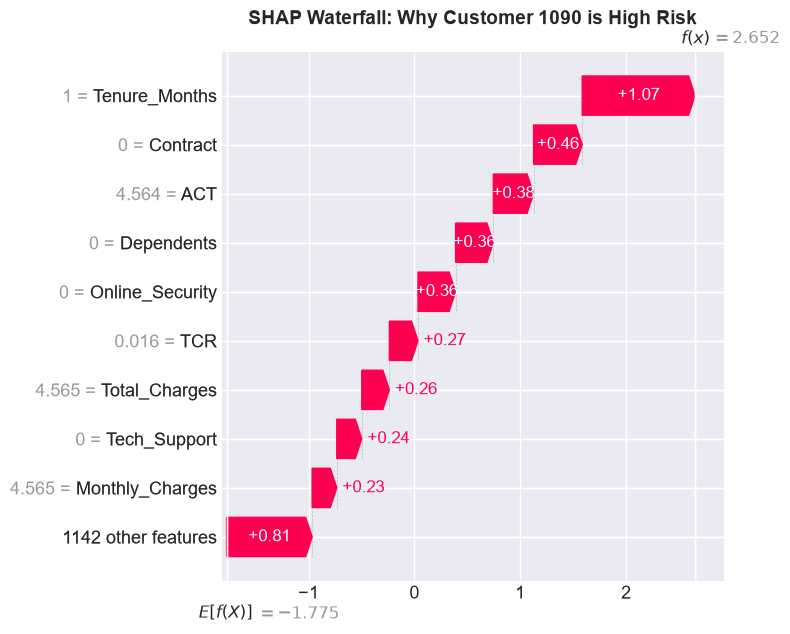


Analyzing low-risk customer (index 475)
Predicted probability: 0.0013
Actual outcome: No Default
✓ Saved: shap_waterfall_low_risk.png


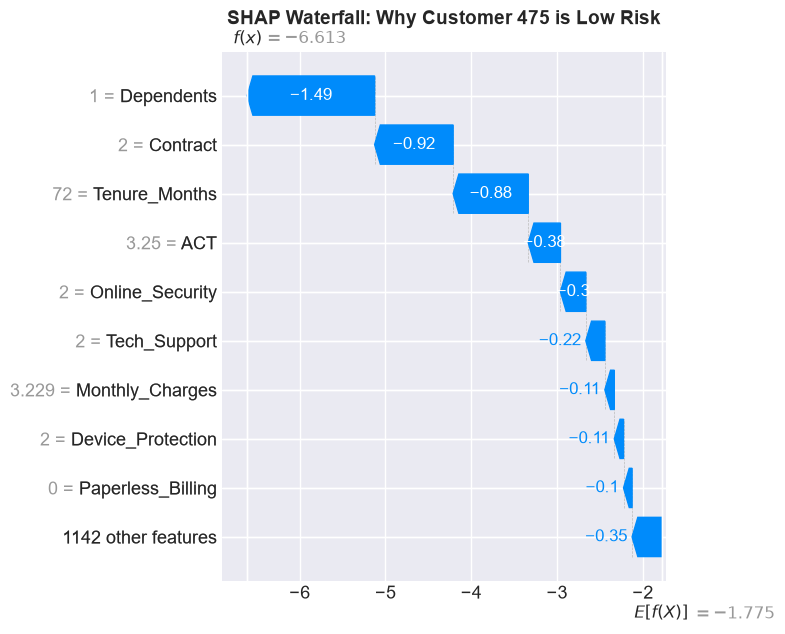


--------------------------------------------------------------------------------
SHAP PLOT 4: Force Plot (Interactive)
--------------------------------------------------------------------------------

FORCE PLOT INTERPRETATION
Similar to waterfall plot but horizontal and more visual.

Red sections = Push prediction HIGHER (toward default)
Blue sections = Push prediction LOWER (away from default)

The width of each section shows the magnitude of impact.

✓ Saved: shap_force_high_risk_classification.png


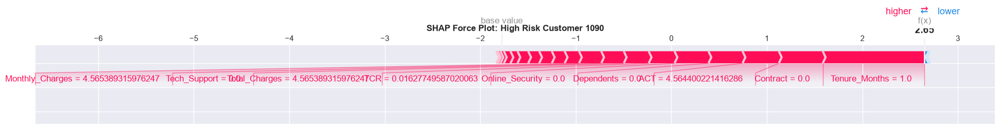


--------------------------------------------------------------------------------
SHAP PLOT 5: Dependence Plot (Feature Relationships)
--------------------------------------------------------------------------------

DEPENDENCE PLOT INTERPRETATION
Shows how SHAP values change as a feature value changes.

X-axis: Feature value
Y-axis: SHAP value (impact on prediction)
Color: Another feature (shows interactions)

How to read it:
- Upward trend = Higher feature value → Higher prediction
- Downward trend = Higher feature value → Lower prediction  
- Scatter = Complex non-linear relationship
- Color patterns = Interaction with another feature

Example:
If "Annual Income" dependence plot shows:
- Low income (left) has positive SHAP → increases default risk
- High income (right) has negative SHAP → decreases default risk
- Color shows interaction with "Debt": High debt makes income even more important

Creating dependence plots for top 3 features: ['Tenure_Months', 'Dependents', 'Contract']
✓

<Figure size 1000x600 with 0 Axes>

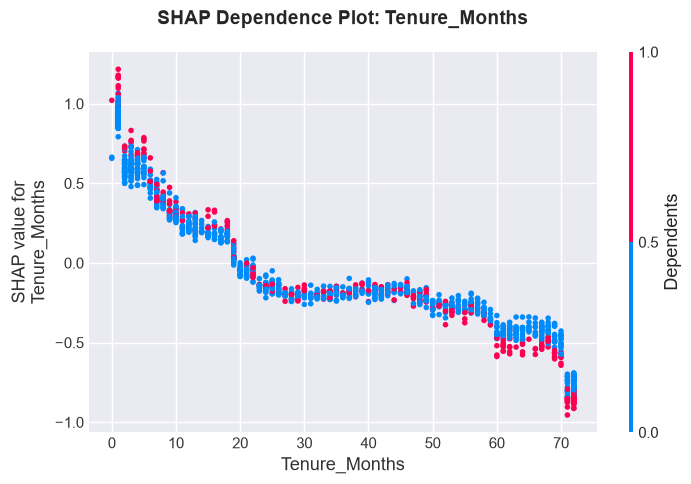

✓ Saved: shap_dependence_Dependents_classification.png


<Figure size 1000x600 with 0 Axes>

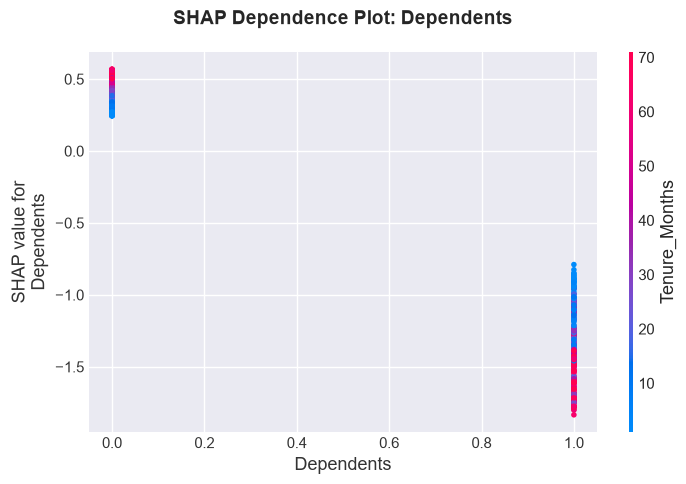

✓ Saved: shap_dependence_Contract_classification.png


<Figure size 1000x600 with 0 Axes>

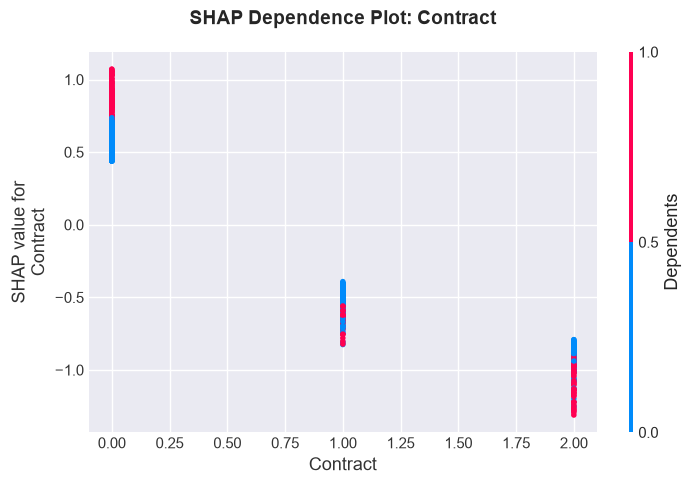



PART 2: LIME ANALYSIS

Initializing LIME explainer...
LIME explainer initialized!

--------------------------------------------------------------------------------
LIME EXPLANATION 1: High-Risk Customer
--------------------------------------------------------------------------------
Explaining high-risk customer (index 1090)...


PART 3: ICE PLOTS

WHAT ARE ICE PLOTS?
ICE plots answer: "How would the prediction change if we changed ONE feature?"

Imagine asking:
"What if this customer's income was $20k? $40k? $60k? $80k?"
ICE plot shows how the prediction changes for each scenario.

How ICE works:
1. Pick one feature (e.g., Annual Income)
2. For one customer, vary ONLY that feature across its range
3. Keep all other features fixed
4. See how the prediction changes
5. Repeat for multiple customers
6. Plot all the lines together

ICE vs PDP (Partial Dependence Plot):
- ICE: Shows individual curves for each customer (detailed)
- PDP: Shows the average curve (simplified)
- ICE reveals he

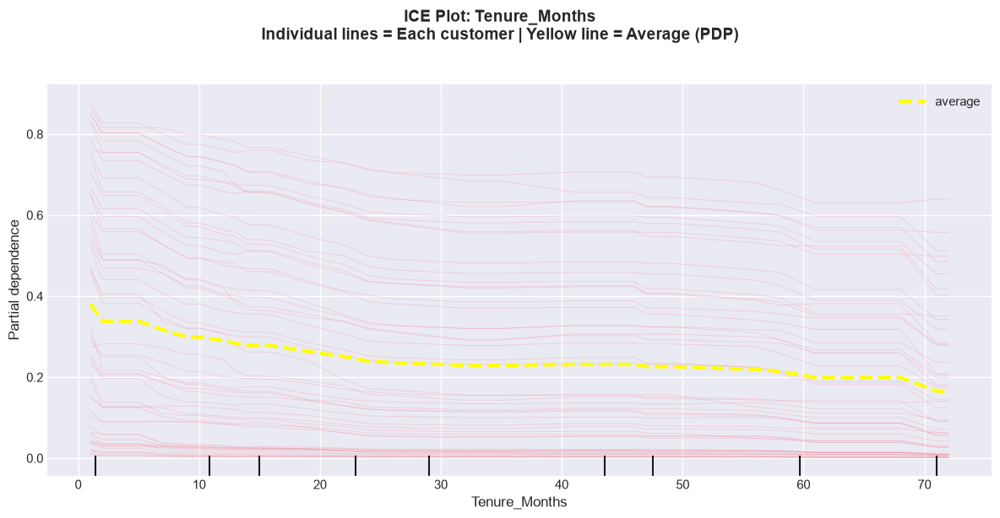


Creating ICE plot for: Dependents
✓ Saved: ice_plot_Dependents_classification.png


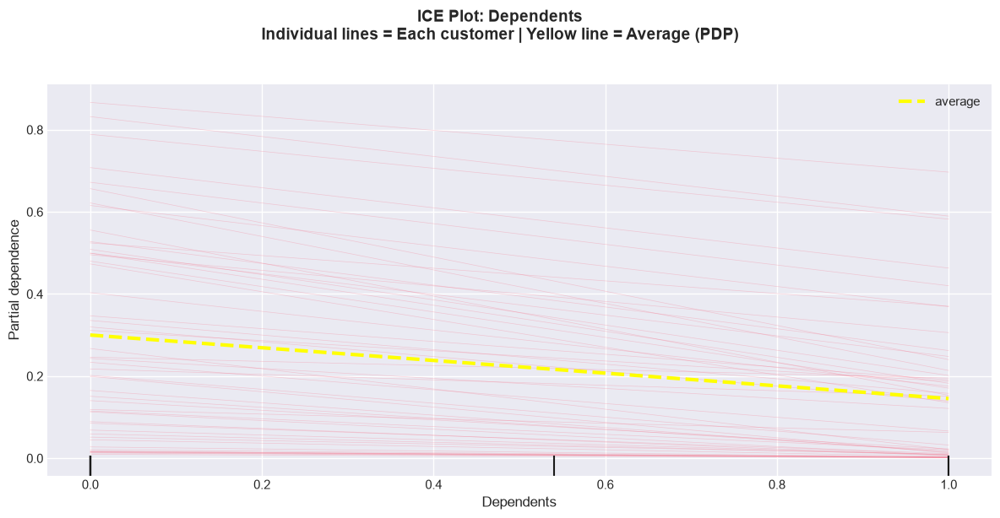


Creating ICE plot for: Contract
✓ Saved: ice_plot_Contract_classification.png


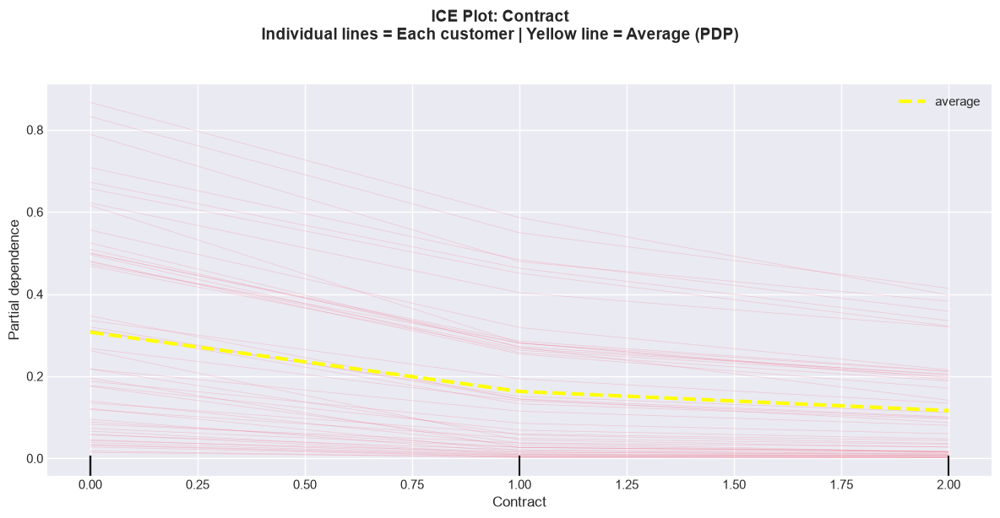


--------------------------------------------------------------------------------
ICE PLOT: Manual Analysis for Specific Customers
--------------------------------------------------------------------------------

MANUAL ICE PLOT
Let's manually create an ICE plot to see exactly what's happening.
We'll pick one feature and one customer, and see how predictions change.

This is like a "what-if" analysis:
"What if this customer had a different credit score?"

Analyzing feature: Tenure_Months
✓ Saved: ice_manual_comparison_classification.png


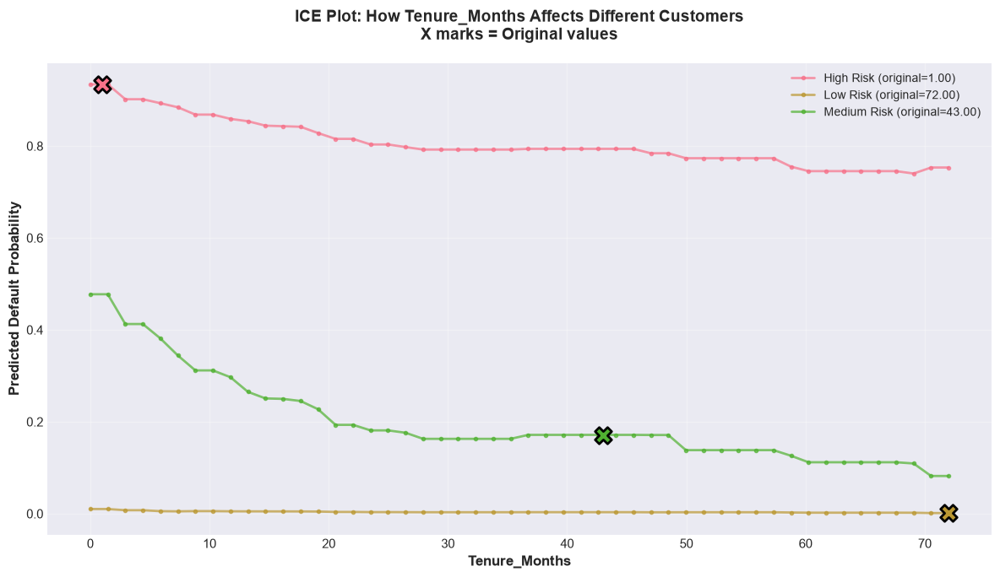


Interpretation:
- Each line shows how Tenure_Months affects one customer
- X marks show their original values
- Different slopes mean the feature affects customers differently
- This is the 'heterogeneity' that ICE plots reveal!


SUMMARY: SHAP vs LIME vs ICE

┌─────────────┬──────────────────────────────┬──────────────────────────────┬──────────────────────────────┐
│ Aspect      │ SHAP                         │ LIME                         │ ICE                          │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Question    │ "How much does each feature  │ "Why this specific           │ "How would prediction change │
│             │  contribute?"                │  prediction?"                │  if we varied one feature?"  │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Scope       │ Global + Local               │ Local only                   │ Local 

In [127]:
"""
MODEL INTERPRETABILITY FOR LIGHTGBM
===================================
This code demonstrates three powerful interpretability techniques:
1. SHAP - Global and local feature importance
2. LIME - Individual prediction explanations
3. ICE - How predictions change when we vary one feature

Dataset: X_train, y_train, X_test, y_test (already preprocessed)
Model: LightGBM
"""

# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# from lightgbm import LGBMClassifier

# Install required packages (run once)
# pip install shap lime scikit-learn

import shap
import lime
import lime.lime_tabular
from sklearn.inspection import PartialDependenceDisplay

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# ══════════════════════════════════════════════════════════════════════════════
# STEP 1: Train LightGBM Model
# ══════════════════════════════════════════════════════════════════════════════
print("=" * 80)
print("STEP 1: Training LightGBM Model")
print("=" * 80)

# Train model
"""
model =  CatBoostClassifier(iterations=100, 
    learning_rate=0.1,
    depth=4, loss_function='Logloss',verbose=0)

model.fit(X_train, y_train)
"""

# Evaluate
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"\nModel trained successfully!")
print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")
print(f"Features: {X_train.shape[1]}")


# ══════════════════════════════════════════════════════════════════════════════
# PART 1: SHAP (SHapley Additive exPlanations)
# ══════════════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 80)
print("PART 1: SHAP ANALYSIS")
print("=" * 80)

"""
WHAT IS SHAP?
=============
SHAP (SHapley Additive exPlanations) answers the question:
"How much does each feature contribute to the prediction?"

Think of it like a team game:
- The prediction is the team's final score
- Each feature is a player
- SHAP values tell you each player's contribution to the score

SHAP calculates values for EACH individual record, but can also show aggregate patterns across all records.
# Each row = SHAP values for ONE customer
# shap_values[0] = SHAP values for customer 0
# shap_values[1] = SHAP values for customer 1
# ... and so on

Example:
Base prediction (average): 0.15 (15% default rate)
Customer A's prediction: 0.85 (85% default probability)

SHAP breakdown:
- Low income:           +0.30 (increases default risk)
- High debt ratio:      +0.25 (increases default risk)
- Poor credit score:    +0.20 (increases default risk)
- Short job tenure:     +0.10 (increases default risk)
- Purpose (debt consol): -0.05 (decreases default risk slightly)
                        ------
Total change:           +0.70 → Final: 0.15 + 0.70 = 0.85 ✓

Key Concepts:
1. POSITIVE SHAP value = Pushes prediction HIGHER (more likely to default)
2. NEGATIVE SHAP value = Pushes prediction LOWER (less likely to default)
3. Sum of all SHAP values = Final prediction - Base prediction

Why SHAP is powerful:
✓ Based on game theory (Shapley values) - mathematically rigorous
✓ Consistent across all models (works for any ML algorithm)
✓ Provides both global (overall) and local (individual) explanations
✓ Shows feature interactions
"""

# Initialize SHAP explainer for tree-based models
print("\nInitializing SHAP TreeExplainer...")
explainer = shap.TreeExplainer(model)

# Calculate SHAP values for test set
# This might take a few minutes for large datasets
print("Calculating SHAP values (this may take a minute)...")
shap_values = explainer.shap_values(X_test)

# For binary classification, shap_values might be a list [class_0, class_1]
# We want the positive class (class 1 = default)
if isinstance(shap_values, list):
    shap_values = shap_values[1]  # SHAP values for class 1 (default)

print(f"SHAP values calculated! Shape: {shap_values.shape}")

# ──────────────────────────────────────────────────────────────────────────────
# SHAP Plot 1: Summary Plot (Global Feature Importance)
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "-" * 80)
print("SHAP PLOT 1: Summary Plot (Global Importance)")
print("-" * 80)
print("""
SUMMARY PLOT INTERPRETATION
===========================
This plot shows:
- X-axis: SHAP value (impact on prediction)
- Y-axis: Features (ranked by importance)
- Color: Feature value (red=high, blue=low)
- Each dot: One prediction from test set

How to read it:
1. Features at the TOP are most important
2. Wide spread = feature has varying impact
3. Red dots on RIGHT = high feature values increase prediction
4. Blue dots on LEFT = low feature values decrease prediction

Example interpretation:
"Credit Score" at top with:
- Blue dots (low scores) on RIGHT → Low credit scores INCREASE default risk
- Red dots (high scores) on LEFT → High credit scores DECREASE default risk
This makes perfect sense!
""")

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test, plot_type="dot", show=False)
plt.title("SHAP Summary Plot: Feature Importance & Impact Direction", 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('shap_summary_plot_clssification.png', dpi=300, bbox_inches='tight')
print("✓ Saved: shap_summary_plot_classification.png")
plt.show()


# ──────────────────────────────────────────────────────────────────────────────
# SHAP Plot 2: Bar Plot (Average Absolute SHAP Values)
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "-" * 80)
print("SHAP PLOT 2: Bar Plot (Mean Absolute Impact)")
print("-" * 80)

print("""
BAR PLOT INTERPRETATION
=======================
This plot shows the AVERAGE absolute impact of each feature.

How to read it:
- Longer bar = More important feature (on average)
- This ignores the DIRECTION (positive/negative)
- Just shows MAGNITUDE of impact

Example:
If "Annual Income" has bar length 0.15:
- On average, Annual Income changes predictions by ±0.15
- Some customers it increases risk, some it decreases
- But on average, it has a 0.15 magnitude impact
""")

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("SHAP Bar Plot: Average Feature Importance", 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('shap_bar_plot_classification.png', dpi=300, bbox_inches='tight')
print("✓ Saved: shap_bar_plot_classification.png")
plt.show()


# ──────────────────────────────────────────────────────────────────────────────
# SHAP Plot 3: Waterfall Plot (Individual Prediction Explanation)
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "-" * 80)
print("SHAP PLOT 3: Waterfall Plot (Individual Explanation)")
print("-" * 80)

print("""
WATERFALL PLOT INTERPRETATION
==============================
This explains ONE specific prediction step-by-step.

How to read it:
- Starts at base value (average prediction for all customers)
- Each bar shows how one feature pushes prediction up or down
- Red bars = Push prediction HIGHER (increase default risk)
- Blue bars = Push prediction LOWER (decrease default risk)
- Final value at top = actual prediction for this customer

Example walkthrough:
1. Base value: 0.15 (15% average default rate)
2. Low income (+0.30): Now at 0.45
3. High debt ratio (+0.25): Now at 0.70
4. Good credit score (-0.10): Now at 0.60
5. ... (other features)
6. Final prediction: 0.85 (85% default probability)

This tells the STORY of why this specific customer is high risk.
""")

# Pick a high-risk customer (predicted to default)
high_risk_idx = np.argmax(y_pred_proba)
print(f"Analyzing high-risk customer (index {high_risk_idx})")
print(f"Predicted probability: {y_pred_proba[high_risk_idx]:.4f}")
print(f"Actual outcome: {'Default' if y_test.iloc[high_risk_idx] == 1 else 'No Default'}")

# Create waterfall plot
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[high_risk_idx],
        base_values=explainer.expected_value,
        data=X_test.iloc[high_risk_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.title(f"SHAP Waterfall: Why Customer {high_risk_idx} is High Risk", 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('shap_waterfall_high_risk_classification.png', dpi=300, bbox_inches='tight')
print("✓ Saved: shap_waterfall_high_risk_classification.png")
plt.show()

# Also analyze a low-risk customer
low_risk_idx = np.argmin(y_pred_proba)
print(f"\nAnalyzing low-risk customer (index {low_risk_idx})")
print(f"Predicted probability: {y_pred_proba[low_risk_idx]:.4f}")
print(f"Actual outcome: {'Default' if y_test.iloc[low_risk_idx] == 1 else 'No Default'}")

shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[low_risk_idx],
        base_values=explainer.expected_value,
        data=X_test.iloc[low_risk_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.title(f"SHAP Waterfall: Why Customer {low_risk_idx} is Low Risk", 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('shap_waterfall_low_risk.png', dpi=300, bbox_inches='tight')
print("✓ Saved: shap_waterfall_low_risk.png")
plt.show()


# ──────────────────────────────────────────────────────────────────────────────
# SHAP Plot 4: Force Plot (Interactive HTML)
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "-" * 80)
print("SHAP PLOT 4: Force Plot (Interactive)")
print("-" * 80)

print("""
FORCE PLOT INTERPRETATION
=========================
Similar to waterfall plot but horizontal and more visual.

Red sections = Push prediction HIGHER (toward default)
Blue sections = Push prediction LOWER (away from default)

The width of each section shows the magnitude of impact.
""")

# Force plot for high-risk customer
shap.force_plot(
    explainer.expected_value,
    shap_values[high_risk_idx],
    X_test.iloc[high_risk_idx],
    matplotlib=True,
    show=False
)
plt.title(f"SHAP Force Plot: High Risk Customer {high_risk_idx}", 
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_force_high_risk_classification.png', dpi=300, bbox_inches='tight')
print("✓ Saved: shap_force_high_risk_classification.png")
plt.show()


# ──────────────────────────────────────────────────────────────────────────────
# SHAP Plot 5: Dependence Plot (Feature Interaction)
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "-" * 80)
print("SHAP PLOT 5: Dependence Plot (Feature Relationships)")
print("-" * 80)

print("""
DEPENDENCE PLOT INTERPRETATION
===============================
Shows how SHAP values change as a feature value changes.

X-axis: Feature value
Y-axis: SHAP value (impact on prediction)
Color: Another feature (shows interactions)

How to read it:
- Upward trend = Higher feature value → Higher prediction
- Downward trend = Higher feature value → Lower prediction  
- Scatter = Complex non-linear relationship
- Color patterns = Interaction with another feature

Example:
If "Annual Income" dependence plot shows:
- Low income (left) has positive SHAP → increases default risk
- High income (right) has negative SHAP → decreases default risk
- Color shows interaction with "Debt": High debt makes income even more important
""")

# Get top 3 most important features
feature_importance = np.abs(shap_values).mean(axis=0)
top_features_idx = np.argsort(feature_importance)[-3:]
top_features = X_test.columns[top_features_idx].tolist()

print(f"Creating dependence plots for top 3 features: {top_features}")

for feature in top_features:
    plt.figure(figsize=(10, 6))
    shap.dependence_plot(
        feature,
        shap_values,
        X_test,
        show=False
    )
    plt.title(f"SHAP Dependence Plot: {feature}", 
              fontsize=14, fontweight='bold', pad=20)
    plt.tight_layout()
    safe_feature_name = feature.replace('/', '_').replace(' ', '_')
    plt.savefig(f'shap_dependence_{safe_feature_name}_classification.png', dpi=300, bbox_inches='tight')
    print(f"✓ Saved: shap_dependence_{safe_feature_name}_classification.png")
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# PART 2: LIME (Local Interpretable Model-agnostic Explanations)
# ══════════════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 80)
print("PART 2: LIME ANALYSIS")
print("=" * 80)

"""
WHAT IS LIME?
=============
LIME answers: "Why did the model make THIS specific prediction?"

How LIME works:
1. Take one prediction you want to explain
2. Create thousands of "similar" synthetic examples
3. See how the model predicts on these synthetic examples
4. Fit a simple linear model to approximate the complex model locally
5. The simple model's coefficients explain the prediction

Think of it like this:
- Complex model = A brilliant expert who can't explain their reasoning
- LIME = A translator who simplifies the expert's decision

Example LIME output:
"Customer A predicted 85% default because:"
- Income < $30k        (+40% risk)
- Debt ratio > 0.5     (+25% risk)
- Credit score < 600   (+15% risk)
- Recent bankruptcy    (+5% risk)

Key differences from SHAP:
- SHAP: Globally consistent, mathematically rigorous, slower
- LIME: Faster, model-agnostic, but can vary between runs
- LIME: Better for simple explanations to non-technical audiences
- SHAP: Better for technical analysis and fairness audits
"""

# Initialize LIME explainer
print("\nInitializing LIME explainer...")
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=['No Default', 'Default'],
    mode='classification',
    random_state=42
)

print("LIME explainer initialized!")


# ──────────────────────────────────────────────────────────────────────────────
# LIME Explanation 1: High-Risk Customer
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "-" * 80)
print("LIME EXPLANATION 1: High-Risk Customer")
print("-" * 80)

"""
HOW TO READ LIME OUTPUT
=======================
Left side (orange bars): Features that INCREASE default probability
Right side (blue bars): Features that DECREASE default probability

Example:
Orange bars (increase risk):
  Annual_Income <= 25000.00         0.30  ████████████
  Credit_Score <= 580.00            0.25  ██████████
  
Blue bars (decrease risk):
  Years_employed > 5.00            -0.10  ████
  Purpose = Home_Improvement       -0.05  ██

Prediction probability: 0.85 (85% chance of default)

This means:
- Low income is the BIGGEST reason for high risk (+30%)
- Poor credit score also contributes (+25%)
- Long employment helps slightly (-10%)
- Purpose helps a tiny bit (-5%)
"""

print(f"Explaining high-risk customer (index {high_risk_idx})...")
'''
# Get LIME explanation
lime_exp_high = lime_explainer.explain_instance(
    data_row=X_test.iloc[high_risk_idx].values,
    predict_fn=model.predict_proba,
    num_features=10  # Show top 10 features
)

# Display explanation
print("\nLIME Explanation (text):")
print(lime_exp_high.as_list())

# Plot explanation
fig = lime_exp_high.as_pyplot_figure()
plt.title(f"LIME Explanation: High-Risk Customer {high_risk_idx}\n"
          f"Predicted: {y_pred_proba[high_risk_idx]:.2%} default probability",
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('lime_high_risk.png', dpi=300, bbox_inches='tight')
print("✓ Saved: lime_high_risk.png")
plt.show()


# ──────────────────────────────────────────────────────────────────────────────
# LIME Explanation 2: Low-Risk Customer
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "-" * 80)
print("LIME EXPLANATION 2: Low-Risk Customer")
print("-" * 80)

print(f"Explaining low-risk customer (index {low_risk_idx})...")

lime_exp_low = lime_explainer.explain_instance(
    data_row=X_test.iloc[low_risk_idx].values,
    predict_fn=model.predict_proba,
    num_features=10
)

print("\nLIME Explanation (text):")
print(lime_exp_low.as_list())

fig = lime_exp_low.as_pyplot_figure()
plt.title(f"LIME Explanation: Low-Risk Customer {low_risk_idx}\n"
          f"Predicted: {y_pred_proba[low_risk_idx]:.2%} default probability",
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('lime_low_risk.png', dpi=300, bbox_inches='tight')
print("✓ Saved: lime_low_risk.png")
plt.show()


# ──────────────────────────────────────────────────────────────────────────────
# LIME: Compare Multiple Predictions
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "-" * 80)
print("LIME: Analyzing 5 Random Customers")
print("-" * 80)

"""
COMPARING MULTIPLE LIME EXPLANATIONS
====================================
This shows how LIME explanations differ across customers.
Notice how:
- Different features are important for different customers
- The same feature can push in different directions
- This is the "local" nature of LIME - it adapts to each individual
"""

# Select 5 random test samples
np.random.seed(42)
random_indices = np.random.choice(len(X_test), size=5, replace=False)

for i, idx in enumerate(random_indices):
    print(f"\nCustomer {i+1} (index {idx}):")
    print(f"  Predicted probability: {y_pred_proba[idx]:.4f}")
    print(f"  Actual: {'Default' if y_test.iloc[idx] == 1 else 'No Default'}")
    
    lime_exp = lime_explainer.explain_instance(
        X_test.iloc[idx].values,
        model.predict_proba,
        num_features=5
    )
    
    print("  Top 5 features:")
    for feature, weight in lime_exp.as_list()[:5]:
        direction = "increases" if weight > 0 else "decreases"
        print(f"    - {feature}: {direction} risk by {abs(weight):.3f}")

'''
# ══════════════════════════════════════════════════════════════════════════════
# PART 3: ICE (Individual Conditional Expectation) Plots
# ══════════════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 80)
print("PART 3: ICE PLOTS")
print("=" * 80)

print("""
WHAT ARE ICE PLOTS?
===================
ICE plots answer: "How would the prediction change if we changed ONE feature?"

Imagine asking:
"What if this customer's income was $20k? $40k? $60k? $80k?"
ICE plot shows how the prediction changes for each scenario.

How ICE works:
1. Pick one feature (e.g., Annual Income)
2. For one customer, vary ONLY that feature across its range
3. Keep all other features fixed
4. See how the prediction changes
5. Repeat for multiple customers
6. Plot all the lines together

ICE vs PDP (Partial Dependence Plot):
- ICE: Shows individual curves for each customer (detailed)
- PDP: Shows the average curve (simplified)
- ICE reveals heterogeneity (different customers react differently)

Example interpretation:
Annual Income ICE plot shows:
- Most customers: Higher income → Lower default risk (downward lines)
- Some customers: Income has little effect (flat lines)
- A few customers: Higher income → Higher risk (upward lines - surprising!)

The upward lines might be customers with:
- Very high debt that scales with income
- Lifestyle inflation issues
- Other risk factors that dominate

This heterogeneity is HIDDEN in PDP but REVEALED in ICE!
""")

# ──────────────────────────────────────────────────────────────────────────────
# ICE Plot 1: Using sklearn's PartialDependenceDisplay with ICE
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "-" * 80)
print("ICE PLOT: Top 3 Most Important Features")
print("-" * 80)

print("""
INTERPRETING ICE + PDP PLOTS
=============================
Each plot shows TWO things:

1. ICE curves (thin lines):
   - Each line = one customer
   - Shows how THAT customer's prediction changes
   - Many lines = heterogeneous effects
   - Few lines = homogeneous effects

2. PDP curve (thick yellow line):
   - Average of all ICE curves
   - Shows overall trend
   - This is what you'd see in a standard PDP

How to read:
- All lines going DOWN = Feature consistently decreases risk
- All lines going UP = Feature consistently increases risk
- Lines going different directions = Feature effect varies by customer
- Flat lines = Feature doesn't matter for those customers
- Wide spread = High heterogeneity in feature effects

Example:
Credit Score ICE plot:
- Most lines slope DOWN (higher score → lower risk) ✓
- A few flat lines (score doesn't matter for them)
- No upward lines (score never increases risk)
- Interpretation: Credit score reliably predicts lower risk
""")

# Get top 3 important features for ICE plots
# We'll use the same top features from SHAP analysis
print(f"Creating ICE plots for: {top_features}")

# Sample customers for ICE (plotting all customers is too slow)
# We'll use 50 random customers
ice_sample_size = min(50, len(X_test))
ice_indices = np.random.choice(len(X_test), size=ice_sample_size, replace=False)
X_ice = X_test.iloc[ice_indices]

# Create sample subset first
X_ice = X_test.iloc[ice_indices].copy()

# Cast it to float right before running the PartialDependenceDisplay
X_ice = X_ice.astype(float)

print(f"Using {ice_sample_size} customers for ICE plots")

for feature in top_features:
    # Get feature index
    feature_idx = X_train.columns.get_loc(feature)
    
    print(f"\nCreating ICE plot for: {feature}")
    
    
    # Create ICE plot with PDP overlay
    fig, ax = plt.subplots(figsize=(12, 6))
    
    display = PartialDependenceDisplay.from_estimator(
        model,
        X_ice,
        features=[feature_idx],
        kind='both',  # Shows both ICE and PDP
        ice_lines_kw={'alpha': 0.3, 'linewidth': 0.5},  # Transparent ICE lines
        pd_line_kw={'color': 'yellow', 'linewidth': 3},  # Thick PDP line
        ax=ax
    )
    
    plt.suptitle(f"ICE Plot: {feature}\n"
                 f"Individual lines = Each customer | Yellow line = Average (PDP)",
                 fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    safe_feature_name = feature.replace('/', '_').replace(' ', '_')
    plt.savefig(f'ice_plot_{safe_feature_name}_classification.png', dpi=300, bbox_inches='tight')
    print(f"✓ Saved: ice_plot_{safe_feature_name}_classification.png")
    plt.show()


# ──────────────────────────────────────────────────────────────────────────────
# ICE Plot 2: Manual ICE for Specific Customers
# ──────────────────────────────────────────────────────────────────────────────
print("\n" + "-" * 80)
print("ICE PLOT: Manual Analysis for Specific Customers")
print("-" * 80)

print("""
MANUAL ICE PLOT
===============
Let's manually create an ICE plot to see exactly what's happening.
We'll pick one feature and one customer, and see how predictions change.

This is like a "what-if" analysis:
"What if this customer had a different credit score?"
""")

# Pick the most important feature
most_important_feature = top_features[0]
feature_idx = X_train.columns.get_loc(most_important_feature)

print(f"Analyzing feature: {most_important_feature}")

# Pick 3 specific customers: high-risk, medium-risk, low-risk
risk_levels = {
    'High Risk': high_risk_idx,
    'Low Risk': low_risk_idx,
    'Medium Risk': np.argsort(y_pred_proba)[len(y_pred_proba)//2]
}

# Create range of values for the feature
feature_min = X_train.iloc[:, feature_idx].min()
feature_max = X_train.iloc[:, feature_idx].max()
feature_range = np.linspace(feature_min, feature_max, 50)

# Plot ICE curves for these 3 customers
plt.figure(figsize=(12, 7))

for risk_label, idx in risk_levels.items():
    # Get customer's data
    customer = X_test.iloc[idx].values.copy()
    original_value = customer[feature_idx]
    
    # Store predictions as we vary the feature
    predictions = []
    
    for value in feature_range:
        # Change only the target feature
        customer_modified = customer.copy()
        customer_modified[feature_idx] = value
        
        # Predict
        pred = model.predict_proba([customer_modified])[0, 1]
        predictions.append(pred)
    
    # Plot
    plt.plot(feature_range, predictions, 
             label=f'{risk_label} (original={original_value:.2f})',
             linewidth=2, marker='o', markersize=3, alpha=0.7)
    
    # Mark original value
    original_pred = model.predict_proba([customer])[0, 1]
    plt.scatter([original_value], [original_pred], 
                s=200, marker='X', zorder=5,
                edgecolors='black', linewidths=2)

plt.xlabel(most_important_feature, fontsize=12, fontweight='bold')
plt.ylabel('Predicted Default Probability', fontsize=12, fontweight='bold')
plt.title(f'ICE Plot: How {most_important_feature} Affects Different Customers\n'
          f'X marks = Original values',
          fontsize=14, fontweight='bold', pad=20)
plt.legend(loc='best', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('ice_manual_comparison_classification.png', dpi=300, bbox_inches='tight')
print("✓ Saved: ice_manual_comparison_classification.png")
plt.show()

print("\nInterpretation:")
print(f"- Each line shows how {most_important_feature} affects one customer")
print(f"- X marks show their original values")
print(f"- Different slopes mean the feature affects customers differently")
print(f"- This is the 'heterogeneity' that ICE plots reveal!")


# ══════════════════════════════════════════════════════════════════════════════
# SUMMARY AND COMPARISON
# ══════════════════════════════════════════════════════════════════════════════
print("\n\n" + "=" * 80)
print("SUMMARY: SHAP vs LIME vs ICE")
print("=" * 80)

summary_table = """
┌─────────────┬──────────────────────────────┬──────────────────────────────┬──────────────────────────────┐
│ Aspect      │ SHAP                         │ LIME                         │ ICE                          │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Question    │ "How much does each feature  │ "Why this specific           │ "How would prediction change │
│             │  contribute?"                │  prediction?"                │  if we varied one feature?"  │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Scope       │ Global + Local               │ Local only                   │ Local only                   │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Math Basis  │ Game theory (Shapley values) │ Local linear approximation   │ Conditional expectation      │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Consistency │ Always same for same input   │ Can vary between runs        │ Always same for same input   │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Speed       │ Slower (rigorous)            │ Faster (approximate)         │ Medium                       │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Audience    │ Technical users, auditors    │ Non-technical stakeholders   │ Data scientists              │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Best For    │ Fairness audits, feature     │ Explaining individual        │ Understanding feature        │
│             │ importance, debugging        │ decisions to customers       │ effects, finding non-linear  │
│             │                              │                              │ relationships                │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Output      │ Feature contribution values  │ Simple if-then rules         │ Prediction curves            │
├─────────────┼──────────────────────────────┼──────────────────────────────┼──────────────────────────────┤
│ Model       │ Any model                    │ Any model                    │ Any model                    │
│ Agnostic?   │ Yes (but optimized for trees)│ Yes                          │ Yes                          │
└─────────────┴──────────────────────────────┴──────────────────────────────┴──────────────────────────────┘

WHEN TO USE WHICH?

Use SHAP when you need:
✓ Rigorous, defensible explanations (e.g., for regulators)
✓ Consistent results across multiple runs
✓ Both global and local interpretability
✓ Feature importance for model debugging
✓ Fairness analysis (checking for bias)

Use LIME when you need:
✓ Quick, intuitive explanations for stakeholders
✓ Simple "if-then" style explanations
✓ To explain predictions to customers
✓ Fast results (LIME is faster than SHAP)
✓ Explanations in non-technical language

Use ICE when you need:
✓ To understand how predictions change with one feature
✓ To find non-linear relationships
✓ To discover heterogeneous effects (feature affects different people differently)
✓ To do "what-if" analysis
✓ To validate feature engineering ideas

RECOMMENDED WORKFLOW:
1. Start with SHAP Summary Plot → Identify important features globally
2. Use ICE Plots → Understand how those features work
3. Use LIME → Explain specific predictions to stakeholders
4. Use SHAP Waterfall → Deep-dive into individual cases for debugging
"""

print(summary_table)

# ══════════════════════════════════════════════════════════════════════════════
# SAVED FILES SUMMARY
# ══════════════════════════════════════════════════════════════════════════════
print("\n" + "=" * 80)
print("ALL SAVED VISUALIZATIONS")
print("=" * 80)
print("""
SHAP Plots:
1. shap_summary_plot.png        - Global feature importance with value distribution
2. shap_bar_plot.png             - Average absolute feature importance
3. shap_waterfall_high_risk.png  - Detailed explanation of high-risk prediction
4. shap_waterfall_low_risk.png   - Detailed explanation of low-risk prediction
5. shap_force_high_risk.png      - Visual force plot for high-risk customer
6. shap_dependence_*.png         - Feature relationship plots (one per top feature)

LIME Plots:
7. lime_high_risk.png            - LIME explanation for high-risk customer
8. lime_low_risk.png             - LIME explanation for low-risk customer

ICE Plots:
9. ice_plot_*.png                - ICE curves (one per top feature)
10. ice_manual_comparison.png    - Custom ICE comparison of 3 customers

Total plots saved: ~10-15 depending on number of top features
""")

print("=" * 80)
print("ANALYSIS COMPLETE!")
print("=" * 80)

## Announcement of Winner

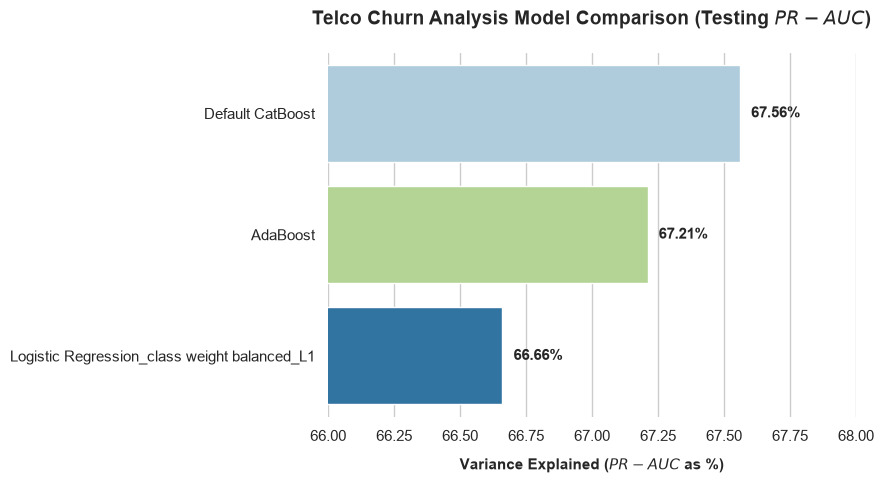

In [130]:
# 1. Structure empirical results into a clean Pandas DataFrame
summary_data = {
    'Model Configuration': [
        'Default CatBoost', 
        'AdaBoost', 
        'Logistic Regression_class weight balanced_L1'
    ],
    'Test PR_AUC Score': [0.6756, 0.6721, 0.6666]
}
df_perf = pd.DataFrame(summary_data)

# 2. Convert raw scores to percentages for clearer display
df_perf['PR_AUC (%)'] = df_perf['Test PR_AUC Score'] * 100

# 3. Initialize the Seaborn Visual Layout
plt.figure(figsize=(9, 5))
sns.set_theme(style="whitegrid")

# Create the bar plot
# We use a custom color palette to highlight the winning model in deep blue
ax = sns.barplot(
    data=df_perf,
    x='PR_AUC (%)',
    y='Model Configuration',
    hue='Model Configuration',  # Fixed assignment pattern
    palette={'Default CatBoost': '#a6cee3', 
             'AdaBoost': '#b2df8a', 
             'Logistic Regression_class weight balanced_L1': '#1f77b4'},
    legend=False
)

# 4. Dynamically overlay the precise value label on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=8, weight='bold', size=11)

# 5. Clean, professional presentation framing
plt.title("Telco Churn Analysis Model Comparison (Testing $PR-AUC$)", fontsize=14, pad=20, weight='bold')
plt.xlabel("Variance Explained ($PR-AUC$ as %)", fontsize=11, labelpad=10, weight='bold')
plt.ylabel("", fontsize=11) # Cleared because model names are descriptive enough

# Constrain the X-axis boundary to give the text labels breathing room
plt.xlim(66,68)

# Strip away unnecessary chart ink for an executive presentation look
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

## The above bar chart clearly announces Default CatBoost as the winner with AdaBoost on the runner-up position.